In [12]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')
import pywt
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split


In [13]:
# Define CNN-LSTM model
class CNN_LSTM_Model(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(CNN_LSTM_Model, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.conv1 = nn.Conv1d(1, 32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm1d(32)  # Add batch normalization layer
        self.conv2 = nn.Conv1d(32, 64, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm1d(64)  # Add batch normalization layer
        self.pool = nn.MaxPool1d(kernel_size=2, stride=2)
        self.lstm = nn.LSTM(64, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)
        
    def forward(self, x):
        x = x.unsqueeze(1)  # Add channel dimension
        x = self.conv1(x)
        x = self.bn1(x)  # Apply batch normalization
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = self.bn2(x)  # Apply batch normalization
        x = self.relu(x)
        x = self.pool(x)
        x = x.permute(0, 2, 1)  # Reshape for LSTM input (batch_size, seq_len, input_size)
        lstm_out, _ = self.lstm(x)
        lstm_out = lstm_out[:, -1, :]  # Take only the output of the last time step
        out = self.fc(lstm_out)
        out = self.softmax(out)
        return out


In [14]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [15]:
# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [16]:
def plot_graphs(epochs_path,
                num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"

In [17]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix

def plot_confusion_matrix(conf_matrix, class_labels,epochs_path):
    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Confusion Matrix.png'))
    plt.show()


In [32]:
def train_model():
    
    global mfcc,model
    
    dataset=input("Enter dataset name:\ntess, savee, crema, ravdess\n ")
    mfcc = int(input("Enter N_MFCC:  "))
    
    if dataset=="tess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\tess_dataset.csv"
    
    elif dataset=="savee":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\savee_dataset.csv"
    
    elif dataset=="crema":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\crema_dataset.csv"
    
    elif dataset=="ravdess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\ravdess_dataset.csv"
    
    
    df = pd.read_csv(csv_file)
    X_mfcc = df['File_Path'].apply(lambda x: extract_mfcc(x,mfcc))
    
    X = [x for x in X_mfcc]
    X = np.array(X)
    
    class_labels = df['Emotion_Label'].unique().tolist()
    
    from sklearn.preprocessing import OneHotEncoder
    enc = OneHotEncoder()
    y = enc.fit_transform(df[['Emotion_Label']])
    y = y.toarray()
    
    train_loader, val_loader = Loader(X, y) 
      
    # Determine input size based on wavelet level
    input_size = mfcc
    hidden_size = 256
    num_layers = 1
        
    # Initialize model
    model = CNN_LSTM_Model(input_size, hidden_size, num_layers, num_classes)
    
    print(f'Input size : {input_size}\n' 
          f'Hidden Size : {hidden_size}\n' 
          f'Model Name: {model.__class__.__name__}\n' 
          f'\nX Shape : {X.shape}'
          f'\nY Shape : {y.shape}\n')
    
    model_path=model.__class__.__name__
    if not os.path.exists( model_path):
        os.makedirs( model_path)
        
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Reset model parameters
    model.apply(reset_parameters)
    
    # Reset optimizer state
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    
    print("Training with N_MFCC:", mfcc)
    num_epochs =int(input("Enter no. of epochs "))
    
    dataset_path = dataset
    dataset_dir = os.path.join(model_path,dataset_path)
    if not os.path.exists(dataset_dir):
        os.makedirs(dataset_dir)
    
    mfcc_level_path = "level "+str(mfcc)+" wavelet"
    mfcc_level_dir = os.path.join(dataset_dir,mfcc_level_path)
    if not os.path.exists(mfcc_level_dir):
        os.makedirs(mfcc_level_dir)
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    epochs_path = os.path.join(mfcc_level_dir,epochs_dir)
    if not os.path.exists(epochs_path):
        os.makedirs(epochs_path)
        
    with open(os.path.join(epochs_path,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validatio Precision', 'Validatio Recall', 'Validatio F1-Score'])

        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(last).pth'))

            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(best).pth'))

    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix = generate_confusion_matrix(model, val_loader, device)
    plot_confusion_matrix(conf_matrix, class_labels,epochs_path)  
    
    return plot_graphs(epochs_path,num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)


def reset_parameters(layer):
    if isinstance(layer, nn.Conv1d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)

In [24]:
def Loader(X,y):
    
    global num_classes

    
    num_classes = y.shape[1]
    print(f"No. of classes {num_classes}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

    train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
    val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)


    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

    return train_loader, val_loader

In [28]:
def extract_mfcc(filename, mfcc):
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    mfcc = np.mean(librosa.feature.mfcc(y=y, sr=sr, n_mfcc=mfcc).T, axis=0)
    print("Training with N_MFCC:", n_mfcc)
    return mfcc

In [29]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# SAVEE

# N_MFCC 16


# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  16
No. of classes 6
Input size : 16
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (480, 16)
Y Shape : (480, 6)
Training with N_MFCC: 16
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7797, Training Accuracy: 0.2474, Training Precision:0.0612,Training Recall:0.2474,Training F1-Score:0.0981
Validation Loss: 1.7433, Validation Accuracy: 0.2604, Validation Precision:0.0678,Validation Recall:0.2604,Validation F1-Score:0.1076
Epoch [2/500],
Training Loss: 1.7460, Training Accuracy: 0.2500, Training Precision:0.1385,Training Recall:0.2500,Training F1-Score:0.1233
Validation Loss: 1.6793, Validation Accuracy: 0.3438, Validation Precision:0.2437,Validation Recall:0.3438,Validation F1-Score:0.1886
Epoch [3/500],
Training Loss: 1.7241, Training Accuracy: 0.3333, Training Precision:0.1959,Training Recall:0.3333,Training F1-Score:0.2332
Validation Loss: 1.6735, Validation Accuracy: 0.3646, Validation Precision:

Epoch [31/500],
Training Loss: 1.5232, Training Accuracy: 0.5286, Training Precision:0.5581,Training Recall:0.5286,Training F1-Score:0.4940
Validation Loss: 1.5274, Validation Accuracy: 0.4688, Validation Precision:0.3576,Validation Recall:0.4688,Validation F1-Score:0.3948
Epoch [32/500],
Training Loss: 1.5055, Training Accuracy: 0.5443, Training Precision:0.5920,Training Recall:0.5443,Training F1-Score:0.5145
Validation Loss: 1.5278, Validation Accuracy: 0.5208, Validation Precision:0.6035,Validation Recall:0.5208,Validation F1-Score:0.4815
Epoch [33/500],
Training Loss: 1.5198, Training Accuracy: 0.5625, Training Precision:0.5766,Training Recall:0.5625,Training F1-Score:0.5488
Validation Loss: 1.5113, Validation Accuracy: 0.5208, Validation Precision:0.4738,Validation Recall:0.5208,Validation F1-Score:0.4880
Epoch [34/500],
Training Loss: 1.5635, Training Accuracy: 0.4922, Training Precision:0.4981,Training Recall:0.4922,Training F1-Score:0.4583
Validation Loss: 1.5193, Validation Ac

Epoch [62/500],
Training Loss: 1.4307, Training Accuracy: 0.6276, Training Precision:0.6250,Training Recall:0.6276,Training F1-Score:0.6145
Validation Loss: 1.4605, Validation Accuracy: 0.5521, Validation Precision:0.5433,Validation Recall:0.5521,Validation F1-Score:0.5153
Epoch [63/500],
Training Loss: 1.4063, Training Accuracy: 0.6250, Training Precision:0.6452,Training Recall:0.6250,Training F1-Score:0.6153
Validation Loss: 1.5042, Validation Accuracy: 0.5000, Validation Precision:0.4798,Validation Recall:0.5000,Validation F1-Score:0.4854
Epoch [64/500],
Training Loss: 1.4082, Training Accuracy: 0.6250, Training Precision:0.6320,Training Recall:0.6250,Training F1-Score:0.6214
Validation Loss: 1.5584, Validation Accuracy: 0.4792, Validation Precision:0.4524,Validation Recall:0.4792,Validation F1-Score:0.4564
Epoch [65/500],
Training Loss: 1.4375, Training Accuracy: 0.6354, Training Precision:0.6485,Training Recall:0.6354,Training F1-Score:0.6203
Validation Loss: 1.4716, Validation Ac

Epoch [92/500],
Training Loss: 1.3948, Training Accuracy: 0.6510, Training Precision:0.6720,Training Recall:0.6510,Training F1-Score:0.6479
Validation Loss: 1.5092, Validation Accuracy: 0.5104, Validation Precision:0.5516,Validation Recall:0.5104,Validation F1-Score:0.5195
Epoch [93/500],
Training Loss: 1.4022, Training Accuracy: 0.6484, Training Precision:0.6749,Training Recall:0.6484,Training F1-Score:0.6338
Validation Loss: 1.4711, Validation Accuracy: 0.5521, Validation Precision:0.5570,Validation Recall:0.5521,Validation F1-Score:0.5222
Epoch [94/500],
Training Loss: 1.3738, Training Accuracy: 0.6849, Training Precision:0.7002,Training Recall:0.6849,Training F1-Score:0.6833
Validation Loss: 1.4797, Validation Accuracy: 0.5729, Validation Precision:0.5996,Validation Recall:0.5729,Validation F1-Score:0.5644
Epoch [95/500],
Training Loss: 1.3406, Training Accuracy: 0.7396, Training Precision:0.7548,Training Recall:0.7396,Training F1-Score:0.7344
Validation Loss: 1.4489, Validation Ac

Epoch [122/500],
Training Loss: 1.2808, Training Accuracy: 0.7839, Training Precision:0.7935,Training Recall:0.7839,Training F1-Score:0.7812
Validation Loss: 1.4919, Validation Accuracy: 0.5521, Validation Precision:0.5537,Validation Recall:0.5521,Validation F1-Score:0.5486
Epoch [123/500],
Training Loss: 1.2702, Training Accuracy: 0.7812, Training Precision:0.7866,Training Recall:0.7812,Training F1-Score:0.7768
Validation Loss: 1.4518, Validation Accuracy: 0.5625, Validation Precision:0.5407,Validation Recall:0.5625,Validation F1-Score:0.5455
Epoch [124/500],
Training Loss: 1.3093, Training Accuracy: 0.7760, Training Precision:0.7846,Training Recall:0.7760,Training F1-Score:0.7714
Validation Loss: 1.4234, Validation Accuracy: 0.6042, Validation Precision:0.5840,Validation Recall:0.6042,Validation F1-Score:0.5888
Epoch [125/500],
Training Loss: 1.2982, Training Accuracy: 0.7526, Training Precision:0.7584,Training Recall:0.7526,Training F1-Score:0.7468
Validation Loss: 1.4321, Validatio

...

Epoch [364/500],
Training Loss: 1.1311, Training Accuracy: 0.9036, Training Precision:0.9057,Training Recall:0.9036,Training F1-Score:0.9035
Validation Loss: 1.4509, Validation Accuracy: 0.6042, Validation Precision:0.6143,Validation Recall:0.6042,Validation F1-Score:0.6024
Epoch [365/500],
Training Loss: 1.1351, Training Accuracy: 0.9297, Training Precision:0.9299,Training Recall:0.9297,Training F1-Score:0.9291
Validation Loss: 1.3836, Validation Accuracy: 0.6667, Validation Precision:0.6580,Validation Recall:0.6667,Validation F1-Score:0.6611
Epoch [366/500],
Training Loss: 1.1195, Training Accuracy: 0.9297, Training Precision:0.9309,Training Recall:0.9297,Training F1-Score:0.9292
Validation Loss: 1.3862, Validation Accuracy: 0.6667, Validation Precision:0.6493,Validation Recall:0.6667,Validation F1-Score:0.6548
Epoch [367/500],
Training Loss: 1.1258, Training Accuracy: 0.9297, Training Precision:0.9303,Training Recall:0.9297,Training F1-Score:0.9292
Validation Loss: 1.4287, Validatio

Epoch [394/500],
Training Loss: 1.1143, Training Accuracy: 0.9349, Training Precision:0.9353,Training Recall:0.9349,Training F1-Score:0.9343
Validation Loss: 1.3881, Validation Accuracy: 0.6667, Validation Precision:0.6556,Validation Recall:0.6667,Validation F1-Score:0.6543
Epoch [395/500],
Training Loss: 1.1108, Training Accuracy: 0.9323, Training Precision:0.9330,Training Recall:0.9323,Training F1-Score:0.9319
Validation Loss: 1.3998, Validation Accuracy: 0.6354, Validation Precision:0.6374,Validation Recall:0.6354,Validation F1-Score:0.6308
Epoch [396/500],
Training Loss: 1.1131, Training Accuracy: 0.9297, Training Precision:0.9325,Training Recall:0.9297,Training F1-Score:0.9295
Validation Loss: 1.3994, Validation Accuracy: 0.6354, Validation Precision:0.6454,Validation Recall:0.6354,Validation F1-Score:0.6304
Epoch [397/500],
Training Loss: 1.1097, Training Accuracy: 0.9349, Training Precision:0.9353,Training Recall:0.9349,Training F1-Score:0.9344
Validation Loss: 1.4084, Validatio

Epoch [424/500],
Training Loss: 1.1305, Training Accuracy: 0.9323, Training Precision:0.9340,Training Recall:0.9323,Training F1-Score:0.9323
Validation Loss: 1.4370, Validation Accuracy: 0.5833, Validation Precision:0.6010,Validation Recall:0.5833,Validation F1-Score:0.5832
Epoch [425/500],
Training Loss: 1.1439, Training Accuracy: 0.9115, Training Precision:0.9142,Training Recall:0.9115,Training F1-Score:0.9104
Validation Loss: 1.3748, Validation Accuracy: 0.6771, Validation Precision:0.6736,Validation Recall:0.6771,Validation F1-Score:0.6691
Epoch [426/500],
Training Loss: 1.1391, Training Accuracy: 0.9115, Training Precision:0.9138,Training Recall:0.9115,Training F1-Score:0.9117
Validation Loss: 1.4271, Validation Accuracy: 0.5938, Validation Precision:0.6370,Validation Recall:0.5938,Validation F1-Score:0.5946
Epoch [427/500],
Training Loss: 1.1516, Training Accuracy: 0.9062, Training Precision:0.9078,Training Recall:0.9062,Training F1-Score:0.9040
Validation Loss: 1.4128, Validatio

Epoch [454/500],
Training Loss: 1.1082, Training Accuracy: 0.9271, Training Precision:0.9275,Training Recall:0.9271,Training F1-Score:0.9270
Validation Loss: 1.4245, Validation Accuracy: 0.6042, Validation Precision:0.6183,Validation Recall:0.6042,Validation F1-Score:0.6036
Epoch [455/500],
Training Loss: 1.1121, Training Accuracy: 0.9323, Training Precision:0.9345,Training Recall:0.9323,Training F1-Score:0.9320
Validation Loss: 1.4354, Validation Accuracy: 0.5938, Validation Precision:0.6071,Validation Recall:0.5938,Validation F1-Score:0.5931
Epoch [456/500],
Training Loss: 1.1132, Training Accuracy: 0.9401, Training Precision:0.9419,Training Recall:0.9401,Training F1-Score:0.9399
Validation Loss: 1.4366, Validation Accuracy: 0.5938, Validation Precision:0.6089,Validation Recall:0.5938,Validation F1-Score:0.5953
Epoch [457/500],
Training Loss: 1.1014, Training Accuracy: 0.9427, Training Precision:0.9437,Training Recall:0.9427,Training F1-Score:0.9425
Validation Loss: 1.4115, Validatio

Epoch [484/500],
Training Loss: 1.0975, Training Accuracy: 0.9453, Training Precision:0.9453,Training Recall:0.9453,Training F1-Score:0.9451
Validation Loss: 1.3994, Validation Accuracy: 0.6354, Validation Precision:0.6232,Validation Recall:0.6354,Validation F1-Score:0.6256
Epoch [485/500],
Training Loss: 1.0977, Training Accuracy: 0.9453, Training Precision:0.9454,Training Recall:0.9453,Training F1-Score:0.9451
Validation Loss: 1.3889, Validation Accuracy: 0.6562, Validation Precision:0.6394,Validation Recall:0.6562,Validation F1-Score:0.6438
Epoch [486/500],
Training Loss: 1.0975, Training Accuracy: 0.9401, Training Precision:0.9409,Training Recall:0.9401,Training F1-Score:0.9401
Validation Loss: 1.3901, Validation Accuracy: 0.6562, Validation Precision:0.6394,Validation Recall:0.6562,Validation F1-Score:0.6438
Epoch [487/500],
Training Loss: 1.0972, Training Accuracy: 0.9453, Training Precision:0.9453,Training Recall:0.9453,Training F1-Score:0.9450
Validation Loss: 1.3946, Validatio

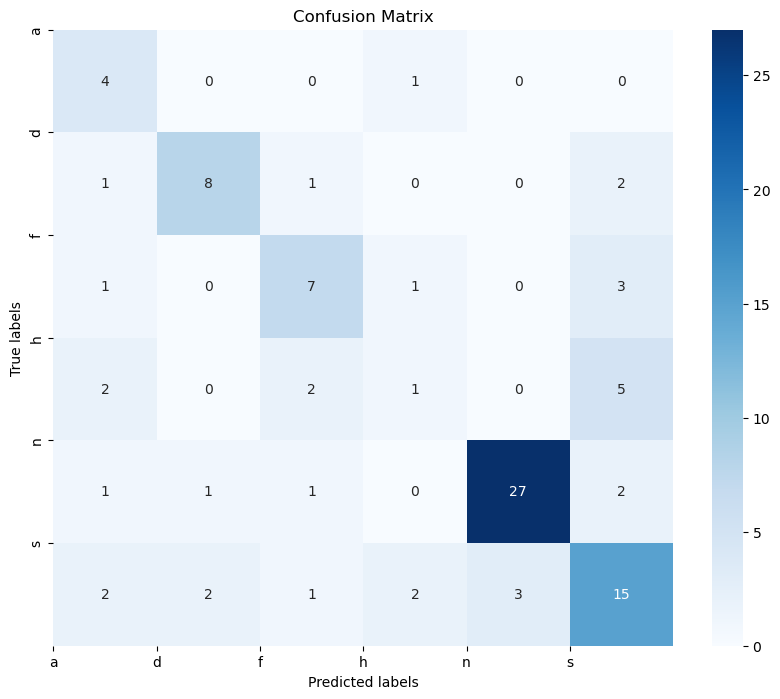

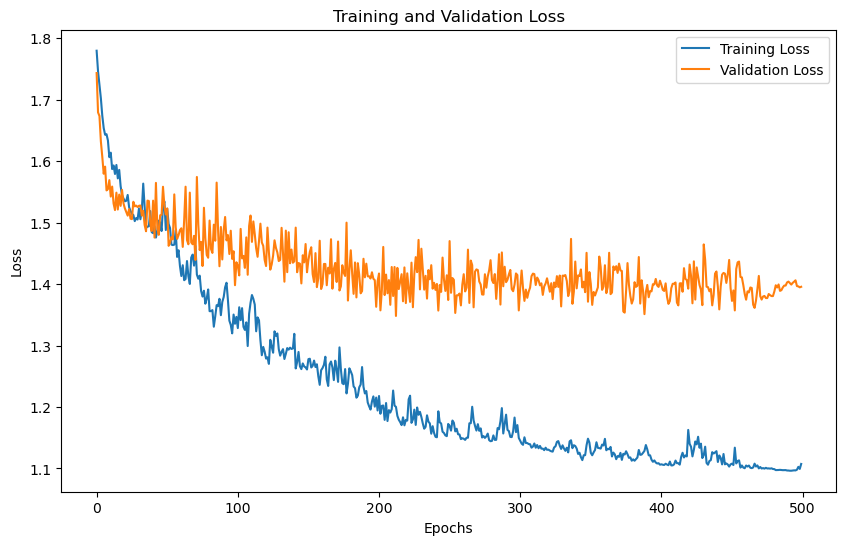

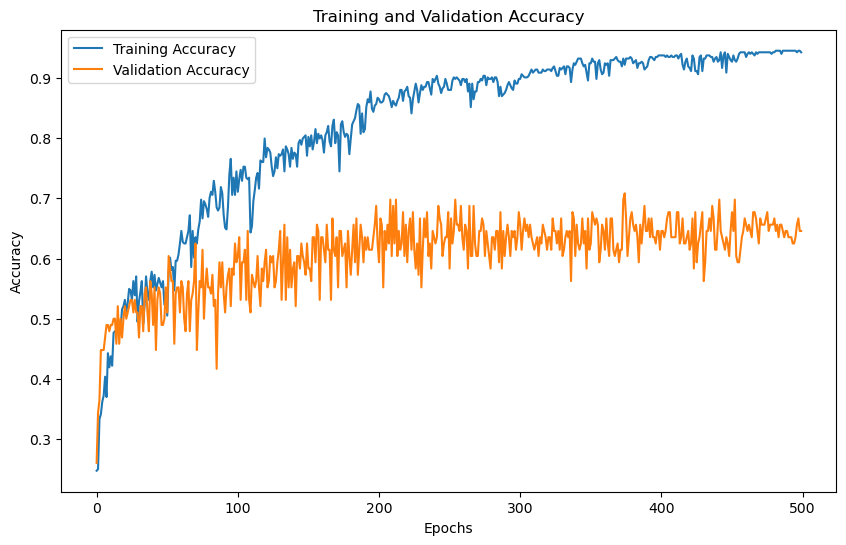

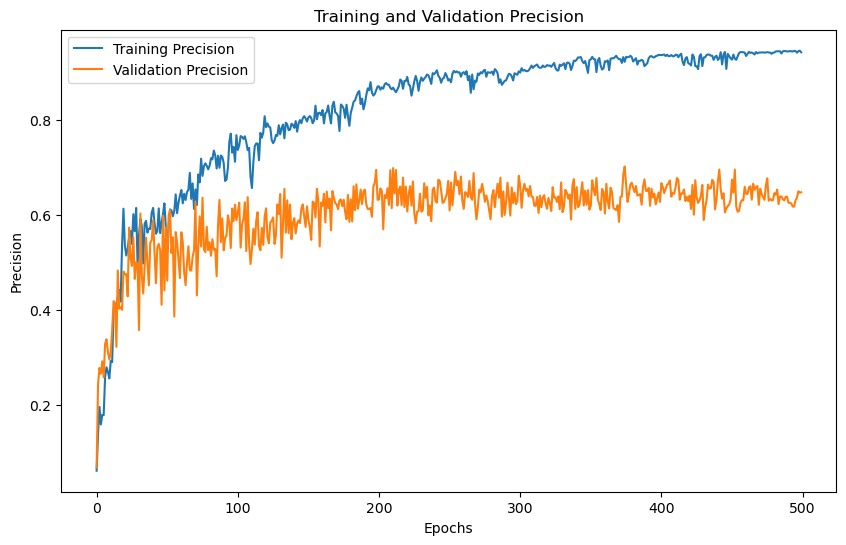

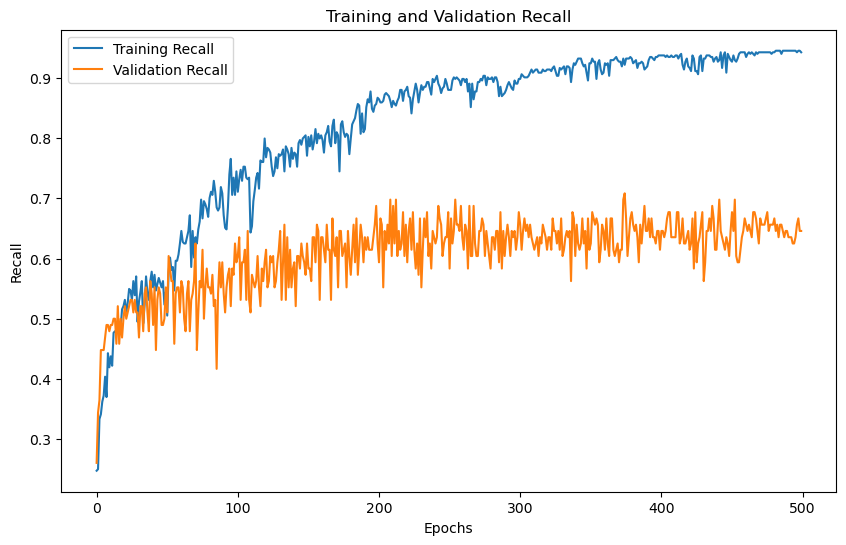

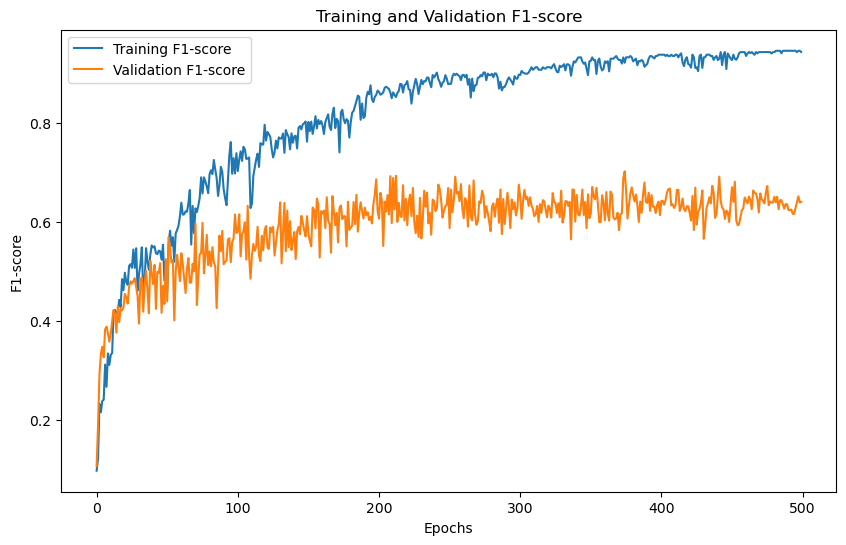

'Model Training and Evaluation Successfully completed'

In [33]:
train_model()

# N_MFCC= 24

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  24
No. of classes 6
Input size : 24
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (480, 24)
Y Shape : (480, 6)
Training with N_MFCC: 24
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7727, Training Accuracy: 0.2500, Training Precision:0.1298,Training Recall:0.2500,Training F1-Score:0.1231
Validation Loss: 1.7222, Validation Accuracy: 0.3438, Validation Precision:0.3727,Validation Recall:0.3438,Validation F1-Score:0.1880
Epoch [2/500],
Training Loss: 1.7371, Training Accuracy: 0.2917, Training Precision:0.1300,Training Recall:0.2917,Training F1-Score:0.1693
Validation Loss: 1.6611, Validation Accuracy: 0.3854, Validation Precision:0.2185,Validation Recall:0.3854,Validation F1-Score:0.2539
Epoch [3/500],
Training Loss: 1.7251, Training Accuracy: 0.3646, Training Precision:0.1833,Training Recall:0.3646,Training F1-Score:0.2422
Validation Loss: 1.6483, Validation Accuracy: 0.4167, Validation Precision:

Epoch [31/500],
Training Loss: 1.5408, Training Accuracy: 0.5156, Training Precision:0.4462,Training Recall:0.5156,Training F1-Score:0.4595
Validation Loss: 1.5634, Validation Accuracy: 0.4792, Validation Precision:0.4361,Validation Recall:0.4792,Validation F1-Score:0.4471
Epoch [32/500],
Training Loss: 1.5247, Training Accuracy: 0.5234, Training Precision:0.4834,Training Recall:0.5234,Training F1-Score:0.4579
Validation Loss: 1.5227, Validation Accuracy: 0.5312, Validation Precision:0.5208,Validation Recall:0.5312,Validation F1-Score:0.4514
Epoch [33/500],
Training Loss: 1.5223, Training Accuracy: 0.5286, Training Precision:0.4729,Training Recall:0.5286,Training F1-Score:0.4927
Validation Loss: 1.6315, Validation Accuracy: 0.4062, Validation Precision:0.4696,Validation Recall:0.4062,Validation F1-Score:0.4084
Epoch [34/500],
Training Loss: 1.5543, Training Accuracy: 0.4844, Training Precision:0.4976,Training Recall:0.4844,Training F1-Score:0.4089
Validation Loss: 1.5305, Validation Ac

Epoch [61/500],
Training Loss: 1.3601, Training Accuracy: 0.6745, Training Precision:0.6744,Training Recall:0.6745,Training F1-Score:0.6731
Validation Loss: 1.4850, Validation Accuracy: 0.5625, Validation Precision:0.5901,Validation Recall:0.5625,Validation F1-Score:0.5577
Epoch [62/500],
Training Loss: 1.3606, Training Accuracy: 0.6276, Training Precision:0.6490,Training Recall:0.6276,Training F1-Score:0.6022
Validation Loss: 1.4933, Validation Accuracy: 0.5417, Validation Precision:0.5179,Validation Recall:0.5417,Validation F1-Score:0.4913
Epoch [63/500],
Training Loss: 1.3998, Training Accuracy: 0.6719, Training Precision:0.6944,Training Recall:0.6719,Training F1-Score:0.6648
Validation Loss: 1.5332, Validation Accuracy: 0.5104, Validation Precision:0.5843,Validation Recall:0.5104,Validation F1-Score:0.5239
Epoch [64/500],
Training Loss: 1.3793, Training Accuracy: 0.6901, Training Precision:0.7012,Training Recall:0.6901,Training F1-Score:0.6837
Validation Loss: 1.4682, Validation Ac

Epoch [91/500],
Training Loss: 1.3381, Training Accuracy: 0.7318, Training Precision:0.7499,Training Recall:0.7318,Training F1-Score:0.7233
Validation Loss: 1.4375, Validation Accuracy: 0.5938, Validation Precision:0.6451,Validation Recall:0.5938,Validation F1-Score:0.5749
Epoch [92/500],
Training Loss: 1.3138, Training Accuracy: 0.7708, Training Precision:0.7741,Training Recall:0.7708,Training F1-Score:0.7656
Validation Loss: 1.4571, Validation Accuracy: 0.5729, Validation Precision:0.6111,Validation Recall:0.5729,Validation F1-Score:0.5746
Epoch [93/500],
Training Loss: 1.2903, Training Accuracy: 0.7891, Training Precision:0.8051,Training Recall:0.7891,Training F1-Score:0.7857
Validation Loss: 1.4190, Validation Accuracy: 0.6354, Validation Precision:0.6603,Validation Recall:0.6354,Validation F1-Score:0.6319
Epoch [94/500],
Training Loss: 1.2676, Training Accuracy: 0.7917, Training Precision:0.8043,Training Recall:0.7917,Training F1-Score:0.7897
Validation Loss: 1.4236, Validation Ac

Epoch [121/500],
Training Loss: 1.2156, Training Accuracy: 0.8464, Training Precision:0.8525,Training Recall:0.8464,Training F1-Score:0.8440
Validation Loss: 1.4140, Validation Accuracy: 0.6042, Validation Precision:0.6157,Validation Recall:0.6042,Validation F1-Score:0.6028
Epoch [122/500],
Training Loss: 1.1949, Training Accuracy: 0.8438, Training Precision:0.8509,Training Recall:0.8438,Training F1-Score:0.8443
Validation Loss: 1.4862, Validation Accuracy: 0.5312, Validation Precision:0.5703,Validation Recall:0.5312,Validation F1-Score:0.5405
Epoch [123/500],
Training Loss: 1.2261, Training Accuracy: 0.7682, Training Precision:0.7995,Training Recall:0.7682,Training F1-Score:0.7633
Validation Loss: 1.4292, Validation Accuracy: 0.6146, Validation Precision:0.6308,Validation Recall:0.6146,Validation F1-Score:0.5975
Epoch [124/500],
Training Loss: 1.2660, Training Accuracy: 0.8568, Training Precision:0.8692,Training Recall:0.8568,Training F1-Score:0.8556
Validation Loss: 1.4095, Validatio

...

Epoch [361/500],
Training Loss: 1.0928, Training Accuracy: 0.9505, Training Precision:0.9515,Training Recall:0.9505,Training F1-Score:0.9501
Validation Loss: 1.3995, Validation Accuracy: 0.6354, Validation Precision:0.6715,Validation Recall:0.6354,Validation F1-Score:0.6420
Epoch [362/500],
Training Loss: 1.0899, Training Accuracy: 0.9531, Training Precision:0.9536,Training Recall:0.9531,Training F1-Score:0.9527
Validation Loss: 1.4193, Validation Accuracy: 0.6042, Validation Precision:0.6452,Validation Recall:0.6042,Validation F1-Score:0.6083
Epoch [363/500],
Training Loss: 1.0919, Training Accuracy: 0.9531, Training Precision:0.9543,Training Recall:0.9531,Training F1-Score:0.9528
Validation Loss: 1.4186, Validation Accuracy: 0.6042, Validation Precision:0.6226,Validation Recall:0.6042,Validation F1-Score:0.5990
Epoch [364/500],
Training Loss: 1.0906, Training Accuracy: 0.9531, Training Precision:0.9545,Training Recall:0.9531,Training F1-Score:0.9528
Validation Loss: 1.3953, Validatio

Epoch [391/500],
Training Loss: 1.0979, Training Accuracy: 0.9531, Training Precision:0.9561,Training Recall:0.9531,Training F1-Score:0.9532
Validation Loss: 1.4195, Validation Accuracy: 0.6042, Validation Precision:0.6097,Validation Recall:0.6042,Validation F1-Score:0.5943
Epoch [392/500],
Training Loss: 1.1013, Training Accuracy: 0.9453, Training Precision:0.9467,Training Recall:0.9453,Training F1-Score:0.9454
Validation Loss: 1.4670, Validation Accuracy: 0.5729, Validation Precision:0.5970,Validation Recall:0.5729,Validation F1-Score:0.5727
Epoch [393/500],
Training Loss: 1.1121, Training Accuracy: 0.9479, Training Precision:0.9502,Training Recall:0.9479,Training F1-Score:0.9484
Validation Loss: 1.4279, Validation Accuracy: 0.6146, Validation Precision:0.6505,Validation Recall:0.6146,Validation F1-Score:0.6175
Epoch [394/500],
Training Loss: 1.1003, Training Accuracy: 0.9583, Training Precision:0.9596,Training Recall:0.9583,Training F1-Score:0.9584
Validation Loss: 1.3949, Validatio

Epoch [422/500],
Training Loss: 1.1015, Training Accuracy: 0.9271, Training Precision:0.9291,Training Recall:0.9271,Training F1-Score:0.9263
Validation Loss: 1.4445, Validation Accuracy: 0.5833, Validation Precision:0.6409,Validation Recall:0.5833,Validation F1-Score:0.5639
Epoch [423/500],
Training Loss: 1.1168, Training Accuracy: 0.9505, Training Precision:0.9518,Training Recall:0.9505,Training F1-Score:0.9505
Validation Loss: 1.5000, Validation Accuracy: 0.5312, Validation Precision:0.5311,Validation Recall:0.5312,Validation F1-Score:0.5210
Epoch [424/500],
Training Loss: 1.0928, Training Accuracy: 0.9531, Training Precision:0.9542,Training Recall:0.9531,Training F1-Score:0.9531
Validation Loss: 1.3792, Validation Accuracy: 0.6354, Validation Precision:0.6321,Validation Recall:0.6354,Validation F1-Score:0.6289
Epoch [425/500],
Training Loss: 1.1029, Training Accuracy: 0.9557, Training Precision:0.9561,Training Recall:0.9557,Training F1-Score:0.9556
Validation Loss: 1.3789, Validatio

Epoch [453/500],
Training Loss: 1.0895, Training Accuracy: 0.9531, Training Precision:0.9543,Training Recall:0.9531,Training F1-Score:0.9533
Validation Loss: 1.4361, Validation Accuracy: 0.6146, Validation Precision:0.6382,Validation Recall:0.6146,Validation F1-Score:0.6152
Epoch [454/500],
Training Loss: 1.0860, Training Accuracy: 0.9557, Training Precision:0.9564,Training Recall:0.9557,Training F1-Score:0.9556
Validation Loss: 1.4347, Validation Accuracy: 0.6042, Validation Precision:0.6223,Validation Recall:0.6042,Validation F1-Score:0.6010
Epoch [455/500],
Training Loss: 1.0956, Training Accuracy: 0.9557, Training Precision:0.9562,Training Recall:0.9557,Training F1-Score:0.9556
Validation Loss: 1.4320, Validation Accuracy: 0.6146, Validation Precision:0.6353,Validation Recall:0.6146,Validation F1-Score:0.6087
Epoch [456/500],
Training Loss: 1.0837, Training Accuracy: 0.9609, Training Precision:0.9626,Training Recall:0.9609,Training F1-Score:0.9610
Validation Loss: 1.4191, Validatio

Epoch [483/500],
Training Loss: 1.0814, Training Accuracy: 0.9609, Training Precision:0.9619,Training Recall:0.9609,Training F1-Score:0.9610
Validation Loss: 1.4033, Validation Accuracy: 0.6250, Validation Precision:0.6389,Validation Recall:0.6250,Validation F1-Score:0.6264
Epoch [484/500],
Training Loss: 1.0815, Training Accuracy: 0.9609, Training Precision:0.9621,Training Recall:0.9609,Training F1-Score:0.9609
Validation Loss: 1.4053, Validation Accuracy: 0.6354, Validation Precision:0.6451,Validation Recall:0.6354,Validation F1-Score:0.6345
Epoch [485/500],
Training Loss: 1.0814, Training Accuracy: 0.9609, Training Precision:0.9616,Training Recall:0.9609,Training F1-Score:0.9608
Validation Loss: 1.4067, Validation Accuracy: 0.6354, Validation Precision:0.6451,Validation Recall:0.6354,Validation F1-Score:0.6345
Epoch [486/500],
Training Loss: 1.0814, Training Accuracy: 0.9609, Training Precision:0.9611,Training Recall:0.9609,Training F1-Score:0.9608
Validation Loss: 1.4067, Validatio

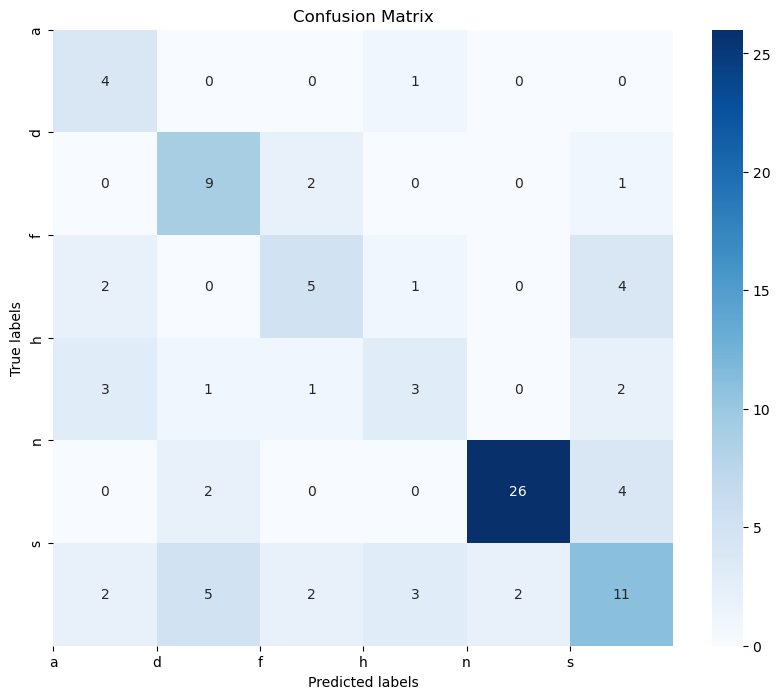

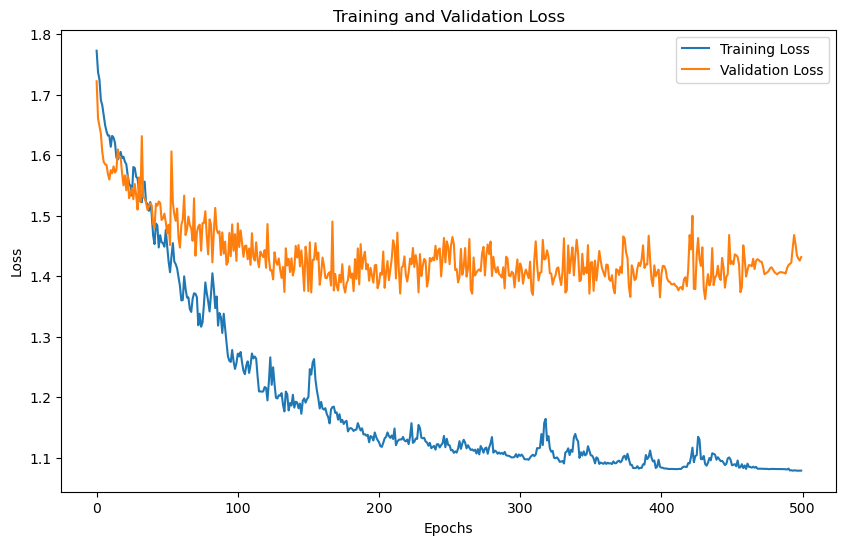

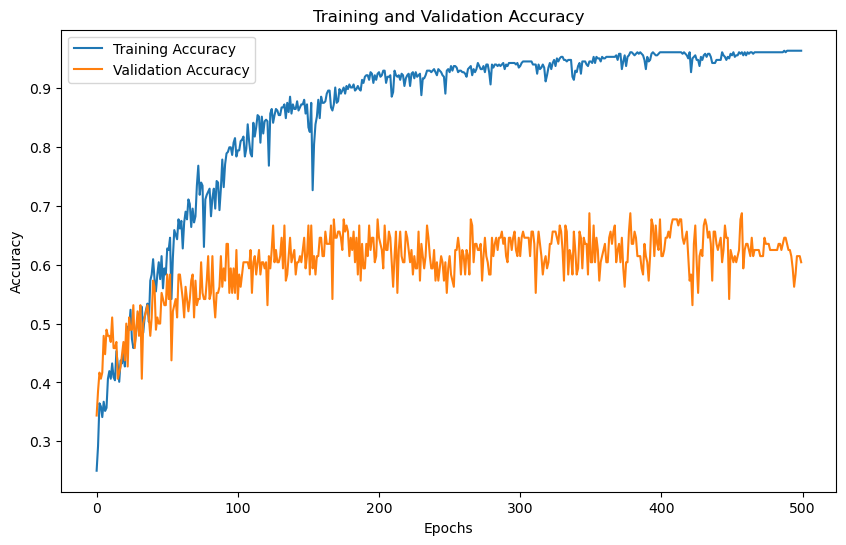

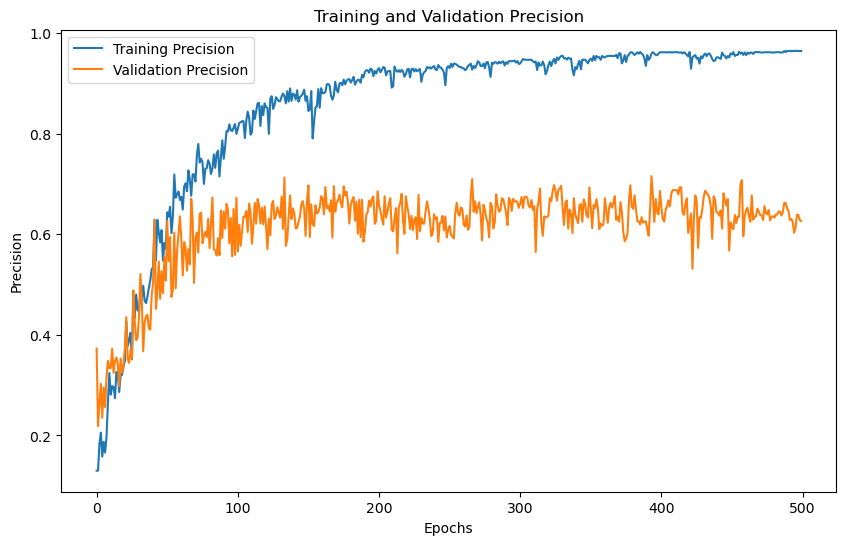

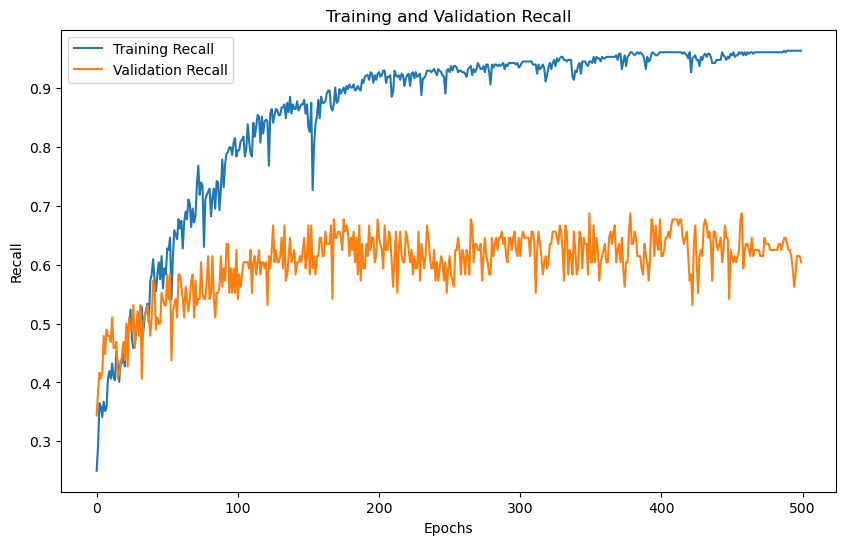

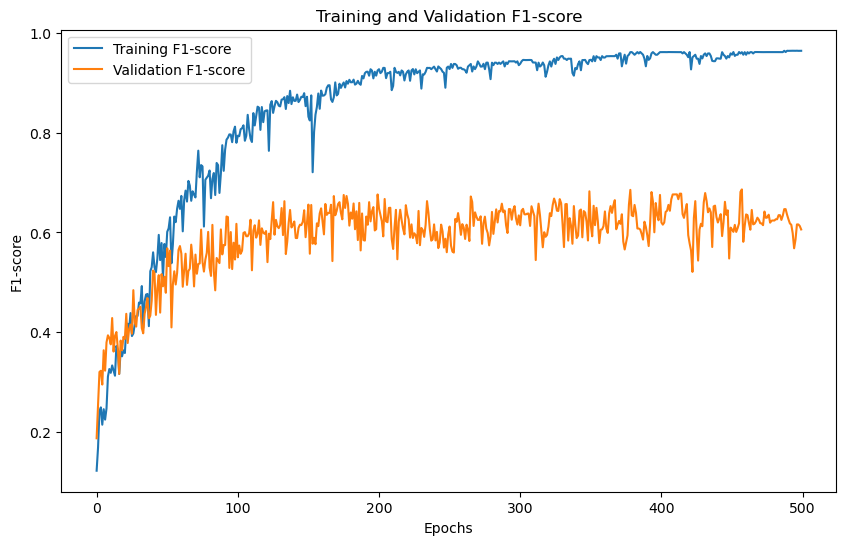

'Model Training and Evaluation Successfully completed'

In [34]:
train_model()

# N_MFCC 32

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  32
No. of classes 6
Input size : 32
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (480, 32)
Y Shape : (480, 6)
Training with N_MFCC: 32
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7807, Training Accuracy: 0.2474, Training Precision:0.0612,Training Recall:0.2474,Training F1-Score:0.0981
Validation Loss: 1.7479, Validation Accuracy: 0.2604, Validation Precision:0.0678,Validation Recall:0.2604,Validation F1-Score:0.1076
Epoch [2/500],
Training Loss: 1.7502, Training Accuracy: 0.2292, Training Precision:0.0525,Training Recall:0.2292,Training F1-Score:0.0855
Validation Loss: 1.6819, Validation Accuracy: 0.3333, Validation Precision:0.1111,Validation Recall:0.3333,Validation F1-Score:0.1667
Epoch [3/500],
Training Loss: 1.7482, Training Accuracy: 0.2474, Training Precision:0.0612,Training Recall:0.2474,Training F1-Score:0.0981
Validation Loss: 1.7027, Validation Accuracy: 0.2604, Validation Precision:

Epoch [31/500],
Training Loss: 1.4823, Training Accuracy: 0.5807, Training Precision:0.4405,Training Recall:0.5807,Training F1-Score:0.4946
Validation Loss: 1.5191, Validation Accuracy: 0.5208, Validation Precision:0.3816,Validation Recall:0.5208,Validation F1-Score:0.4332
Epoch [32/500],
Training Loss: 1.4931, Training Accuracy: 0.5495, Training Precision:0.4225,Training Recall:0.5495,Training F1-Score:0.4736
Validation Loss: 1.5302, Validation Accuracy: 0.5104, Validation Precision:0.4160,Validation Recall:0.5104,Validation F1-Score:0.4489
Epoch [33/500],
Training Loss: 1.5000, Training Accuracy: 0.5521, Training Precision:0.4134,Training Recall:0.5521,Training F1-Score:0.4690
Validation Loss: 1.5598, Validation Accuracy: 0.4479, Validation Precision:0.3119,Validation Recall:0.4479,Validation F1-Score:0.3648
Epoch [34/500],
Training Loss: 1.4990, Training Accuracy: 0.5625, Training Precision:0.4239,Training Recall:0.5625,Training F1-Score:0.4786
Validation Loss: 1.5421, Validation Ac

Epoch [61/500],
Training Loss: 1.4637, Training Accuracy: 0.5677, Training Precision:0.4427,Training Recall:0.5677,Training F1-Score:0.4850
Validation Loss: 1.5154, Validation Accuracy: 0.5208, Validation Precision:0.3805,Validation Recall:0.5208,Validation F1-Score:0.4343
Epoch [62/500],
Training Loss: 1.4663, Training Accuracy: 0.5964, Training Precision:0.4633,Training Recall:0.5964,Training F1-Score:0.5159
Validation Loss: 1.5196, Validation Accuracy: 0.5208, Validation Precision:0.4173,Validation Recall:0.5208,Validation F1-Score:0.4590
Epoch [63/500],
Training Loss: 1.4442, Training Accuracy: 0.6120, Training Precision:0.4595,Training Recall:0.6120,Training F1-Score:0.5233
Validation Loss: 1.5105, Validation Accuracy: 0.5312, Validation Precision:0.4109,Validation Recall:0.5312,Validation F1-Score:0.4612
Epoch [64/500],
Training Loss: 1.4357, Training Accuracy: 0.6198, Training Precision:0.4789,Training Recall:0.6198,Training F1-Score:0.5356
Validation Loss: 1.5324, Validation Ac

Epoch [91/500],
Training Loss: 1.3868, Training Accuracy: 0.6667, Training Precision:0.5755,Training Recall:0.6667,Training F1-Score:0.5945
Validation Loss: 1.4950, Validation Accuracy: 0.5417, Validation Precision:0.4185,Validation Recall:0.5417,Validation F1-Score:0.4669
Epoch [92/500],
Training Loss: 1.3858, Training Accuracy: 0.6771, Training Precision:0.5983,Training Recall:0.6771,Training F1-Score:0.6175
Validation Loss: 1.5003, Validation Accuracy: 0.5521, Validation Precision:0.5183,Validation Recall:0.5521,Validation F1-Score:0.5126
Epoch [93/500],
Training Loss: 1.4272, Training Accuracy: 0.6146, Training Precision:0.5272,Training Recall:0.6146,Training F1-Score:0.5284
Validation Loss: 1.5332, Validation Accuracy: 0.5208, Validation Precision:0.3845,Validation Recall:0.5208,Validation F1-Score:0.4344
Epoch [94/500],
Training Loss: 1.4728, Training Accuracy: 0.5521, Training Precision:0.4646,Training Recall:0.5521,Training F1-Score:0.4763
Validation Loss: 1.4957, Validation Ac

Epoch [121/500],
Training Loss: 1.3788, Training Accuracy: 0.7344, Training Precision:0.6594,Training Recall:0.7344,Training F1-Score:0.6745
Validation Loss: 1.4179, Validation Accuracy: 0.6458, Validation Precision:0.5619,Validation Recall:0.6458,Validation F1-Score:0.5849
Epoch [122/500],
Training Loss: 1.3168, Training Accuracy: 0.6979, Training Precision:0.6258,Training Recall:0.6979,Training F1-Score:0.6522
Validation Loss: 1.5094, Validation Accuracy: 0.5208, Validation Precision:0.5197,Validation Recall:0.5208,Validation F1-Score:0.5010
Epoch [123/500],
Training Loss: 1.3486, Training Accuracy: 0.7396, Training Precision:0.6553,Training Recall:0.7396,Training F1-Score:0.6865
Validation Loss: 1.4663, Validation Accuracy: 0.5625, Validation Precision:0.4846,Validation Recall:0.5625,Validation F1-Score:0.5040
Epoch [124/500],
Training Loss: 1.2993, Training Accuracy: 0.7292, Training Precision:0.6451,Training Recall:0.7292,Training F1-Score:0.6793
Validation Loss: 1.4827, Validatio

...

Epoch [361/500],
Training Loss: 1.1856, Training Accuracy: 0.8724, Training Precision:0.8918,Training Recall:0.8724,Training F1-Score:0.8484
Validation Loss: 1.4809, Validation Accuracy: 0.5521, Validation Precision:0.5683,Validation Recall:0.5521,Validation F1-Score:0.5481
Epoch [362/500],
Training Loss: 1.1733, Training Accuracy: 0.8698, Training Precision:0.8795,Training Recall:0.8698,Training F1-Score:0.8458
Validation Loss: 1.4377, Validation Accuracy: 0.6042, Validation Precision:0.6007,Validation Recall:0.6042,Validation F1-Score:0.5857
Epoch [363/500],
Training Loss: 1.1741, Training Accuracy: 0.8724, Training Precision:0.8886,Training Recall:0.8724,Training F1-Score:0.8495
Validation Loss: 1.4030, Validation Accuracy: 0.6354, Validation Precision:0.6505,Validation Recall:0.6354,Validation F1-Score:0.6147
Epoch [364/500],
Training Loss: 1.1798, Training Accuracy: 0.8620, Training Precision:0.8790,Training Recall:0.8620,Training F1-Score:0.8374
Validation Loss: 1.4114, Validatio

Epoch [391/500],
Training Loss: 1.1662, Training Accuracy: 0.8724, Training Precision:0.8888,Training Recall:0.8724,Training F1-Score:0.8495
Validation Loss: 1.4881, Validation Accuracy: 0.5521, Validation Precision:0.5742,Validation Recall:0.5521,Validation F1-Score:0.5373
Epoch [392/500],
Training Loss: 1.1684, Training Accuracy: 0.8776, Training Precision:0.8954,Training Recall:0.8776,Training F1-Score:0.8552
Validation Loss: 1.4637, Validation Accuracy: 0.5729, Validation Precision:0.5489,Validation Recall:0.5729,Validation F1-Score:0.5478
Epoch [393/500],
Training Loss: 1.1683, Training Accuracy: 0.8750, Training Precision:0.8917,Training Recall:0.8750,Training F1-Score:0.8523
Validation Loss: 1.4207, Validation Accuracy: 0.6250, Validation Precision:0.6178,Validation Recall:0.6250,Validation F1-Score:0.6018
Epoch [394/500],
Training Loss: 1.1660, Training Accuracy: 0.8776, Training Precision:0.8929,Training Recall:0.8776,Training F1-Score:0.8544
Validation Loss: 1.4592, Validatio

Epoch [421/500],
Training Loss: 1.1638, Training Accuracy: 0.8776, Training Precision:0.8971,Training Recall:0.8776,Training F1-Score:0.8557
Validation Loss: 1.4515, Validation Accuracy: 0.5833, Validation Precision:0.5693,Validation Recall:0.5833,Validation F1-Score:0.5610
Epoch [422/500],
Training Loss: 1.1638, Training Accuracy: 0.8776, Training Precision:0.8973,Training Recall:0.8776,Training F1-Score:0.8557
Validation Loss: 1.4485, Validation Accuracy: 0.6042, Validation Precision:0.5936,Validation Recall:0.6042,Validation F1-Score:0.5820
Epoch [423/500],
Training Loss: 1.1639, Training Accuracy: 0.8776, Training Precision:0.8926,Training Recall:0.8776,Training F1-Score:0.8543
Validation Loss: 1.4399, Validation Accuracy: 0.6042, Validation Precision:0.5633,Validation Recall:0.6042,Validation F1-Score:0.5729
Epoch [424/500],
Training Loss: 1.1639, Training Accuracy: 0.8776, Training Precision:0.8928,Training Recall:0.8776,Training F1-Score:0.8544
Validation Loss: 1.4400, Validatio

Epoch [451/500],
Training Loss: 1.1633, Training Accuracy: 0.8776, Training Precision:0.8958,Training Recall:0.8776,Training F1-Score:0.8554
Validation Loss: 1.4450, Validation Accuracy: 0.5938, Validation Precision:0.5964,Validation Recall:0.5938,Validation F1-Score:0.5752
Epoch [452/500],
Training Loss: 1.1630, Training Accuracy: 0.8776, Training Precision:0.8953,Training Recall:0.8776,Training F1-Score:0.8552
Validation Loss: 1.4468, Validation Accuracy: 0.5938, Validation Precision:0.5964,Validation Recall:0.5938,Validation F1-Score:0.5752
Epoch [453/500],
Training Loss: 1.1632, Training Accuracy: 0.8776, Training Precision:0.8958,Training Recall:0.8776,Training F1-Score:0.8553
Validation Loss: 1.4442, Validation Accuracy: 0.5938, Validation Precision:0.5964,Validation Recall:0.5938,Validation F1-Score:0.5752
Epoch [454/500],
Training Loss: 1.1631, Training Accuracy: 0.8776, Training Precision:0.8951,Training Recall:0.8776,Training F1-Score:0.8551
Validation Loss: 1.4443, Validatio

Epoch [481/500],
Training Loss: 1.1626, Training Accuracy: 0.8776, Training Precision:0.8976,Training Recall:0.8776,Training F1-Score:0.8557
Validation Loss: 1.4290, Validation Accuracy: 0.6250, Validation Precision:0.6174,Validation Recall:0.6250,Validation F1-Score:0.6051
Epoch [482/500],
Training Loss: 1.1635, Training Accuracy: 0.8776, Training Precision:0.8963,Training Recall:0.8776,Training F1-Score:0.8554
Validation Loss: 1.4350, Validation Accuracy: 0.5938, Validation Precision:0.5343,Validation Recall:0.5938,Validation F1-Score:0.5556
Epoch [483/500],
Training Loss: 1.1635, Training Accuracy: 0.8776, Training Precision:0.8930,Training Recall:0.8776,Training F1-Score:0.8545
Validation Loss: 1.4338, Validation Accuracy: 0.5938, Validation Precision:0.5410,Validation Recall:0.5938,Validation F1-Score:0.5604
Epoch [484/500],
Training Loss: 1.1633, Training Accuracy: 0.8776, Training Precision:0.8938,Training Recall:0.8776,Training F1-Score:0.8548
Validation Loss: 1.4352, Validatio

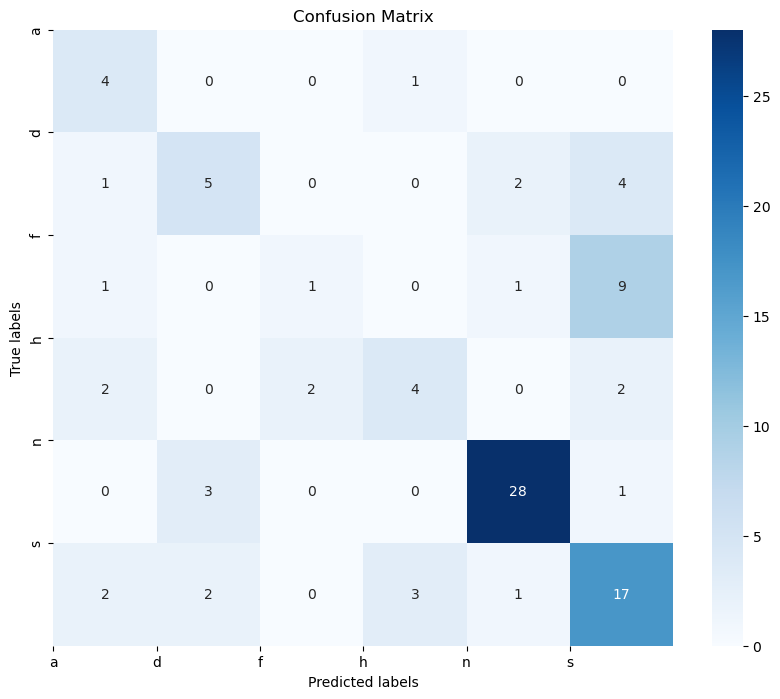

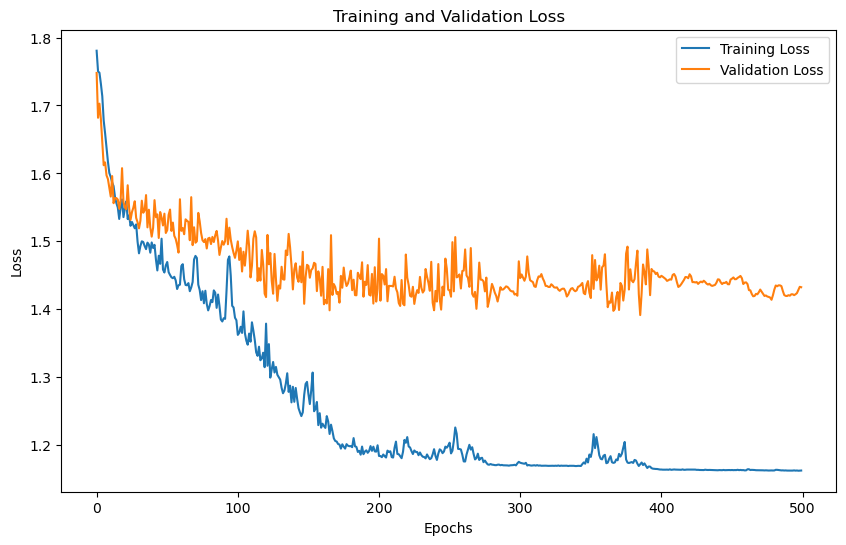

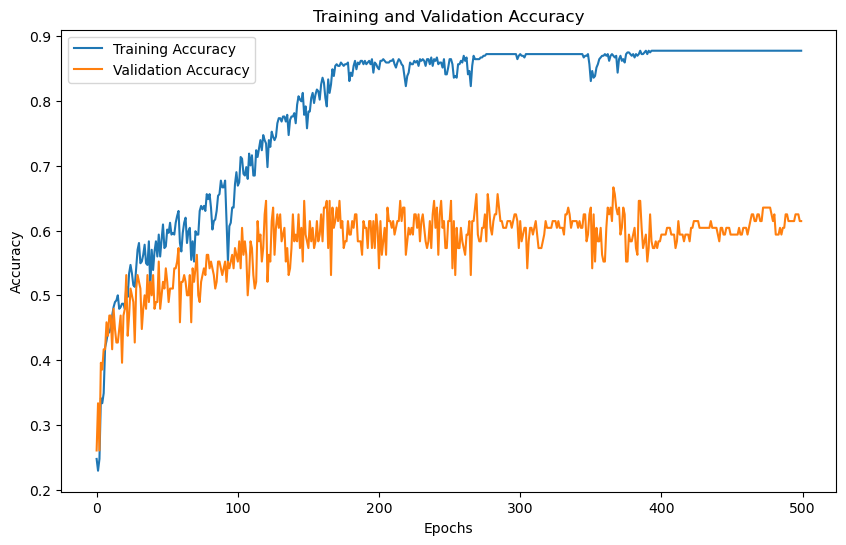

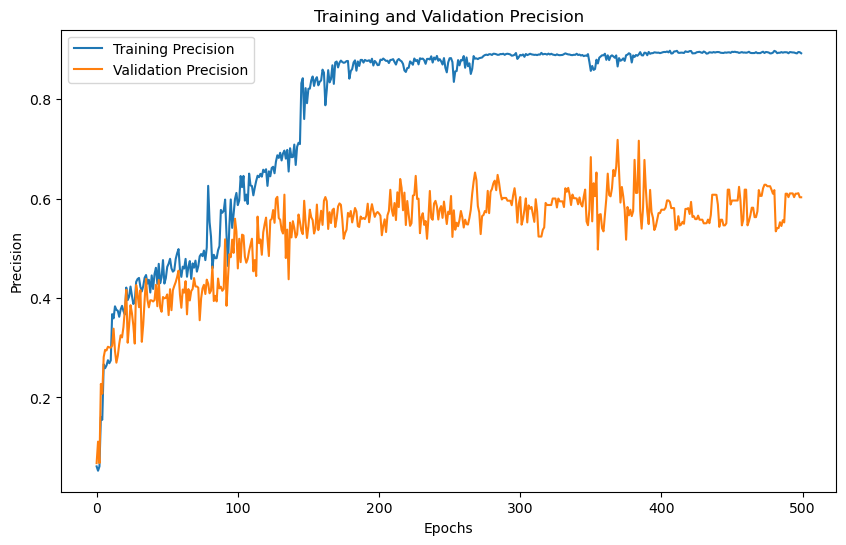

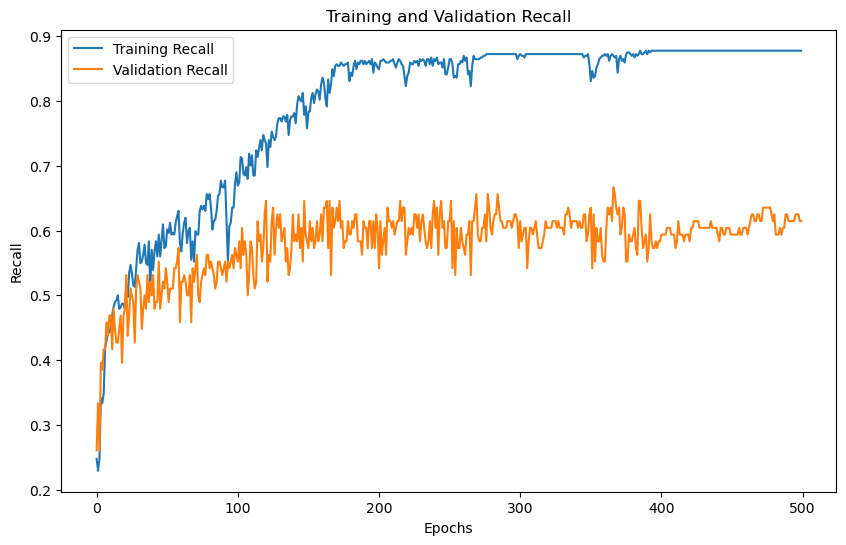

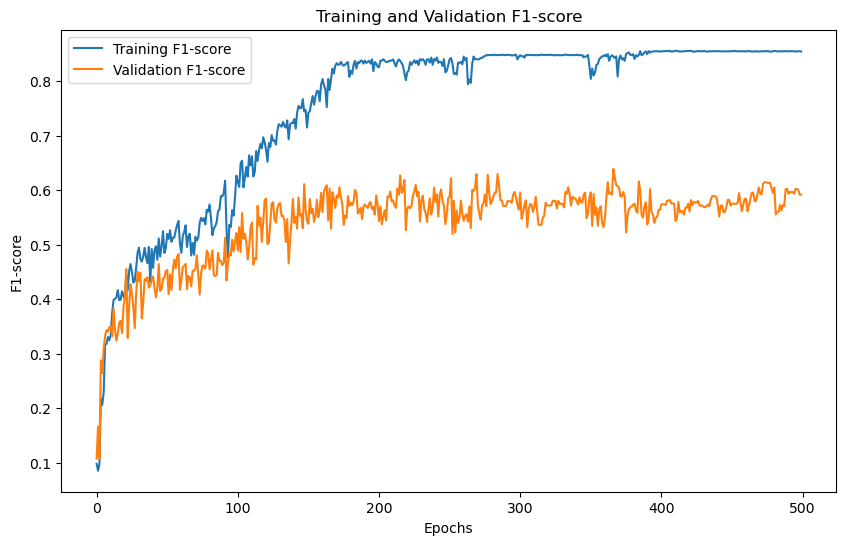

'Model Training and Evaluation Successfully completed'

In [35]:
train_model()

# N_MFCC 40

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  40
No. of classes 6
Input size : 40
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (480, 40)
Y Shape : (480, 6)
Training with N_MFCC: 40
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7771, Training Accuracy: 0.2474, Training Precision:0.0612,Training Recall:0.2474,Training F1-Score:0.0981
Validation Loss: 1.7435, Validation Accuracy: 0.2604, Validation Precision:0.0678,Validation Recall:0.2604,Validation F1-Score:0.1076
Epoch [2/500],
Training Loss: 1.7240, Training Accuracy: 0.3880, Training Precision:0.1862,Training Recall:0.3880,Training F1-Score:0.2482
Validation Loss: 1.6368, Validation Accuracy: 0.4271, Validation Precision:0.2619,Validation Recall:0.4271,Validation F1-Score:0.3023
Epoch [3/500],
Training Loss: 1.6970, Training Accuracy: 0.3724, Training Precision:0.1788,Training Recall:0.3724,Training F1-Score:0.2369
Validation Loss: 1.6023, Validation Accuracy: 0.4583, Validation Precision:

Epoch [31/500],
Training Loss: 1.4470, Training Accuracy: 0.6094, Training Precision:0.5401,Training Recall:0.6094,Training F1-Score:0.5572
Validation Loss: 1.4481, Validation Accuracy: 0.5938, Validation Precision:0.5129,Validation Recall:0.5938,Validation F1-Score:0.5394
Epoch [32/500],
Training Loss: 1.4506, Training Accuracy: 0.6068, Training Precision:0.5522,Training Recall:0.6068,Training F1-Score:0.5488
Validation Loss: 1.4452, Validation Accuracy: 0.6042, Validation Precision:0.5514,Validation Recall:0.6042,Validation F1-Score:0.5510
Epoch [33/500],
Training Loss: 1.4478, Training Accuracy: 0.6198, Training Precision:0.5474,Training Recall:0.6198,Training F1-Score:0.5672
Validation Loss: 1.4379, Validation Accuracy: 0.6042, Validation Precision:0.5274,Validation Recall:0.6042,Validation F1-Score:0.5480
Epoch [34/500],
Training Loss: 1.4413, Training Accuracy: 0.5964, Training Precision:0.5474,Training Recall:0.5964,Training F1-Score:0.5392
Validation Loss: 1.4434, Validation Ac

Epoch [61/500],
Training Loss: 1.3503, Training Accuracy: 0.7057, Training Precision:0.7200,Training Recall:0.7057,Training F1-Score:0.6881
Validation Loss: 1.3964, Validation Accuracy: 0.6458, Validation Precision:0.6448,Validation Recall:0.6458,Validation F1-Score:0.6250
Epoch [62/500],
Training Loss: 1.3629, Training Accuracy: 0.6979, Training Precision:0.7107,Training Recall:0.6979,Training F1-Score:0.6861
Validation Loss: 1.4239, Validation Accuracy: 0.6146, Validation Precision:0.6356,Validation Recall:0.6146,Validation F1-Score:0.6020
Epoch [63/500],
Training Loss: 1.3527, Training Accuracy: 0.6953, Training Precision:0.7263,Training Recall:0.6953,Training F1-Score:0.6756
Validation Loss: 1.4108, Validation Accuracy: 0.6354, Validation Precision:0.5736,Validation Recall:0.6354,Validation F1-Score:0.5820
Epoch [64/500],
Training Loss: 1.3560, Training Accuracy: 0.7214, Training Precision:0.7352,Training Recall:0.7214,Training F1-Score:0.7079
Validation Loss: 1.4000, Validation Ac

Epoch [91/500],
Training Loss: 1.3452, Training Accuracy: 0.7422, Training Precision:0.7561,Training Recall:0.7422,Training F1-Score:0.7318
Validation Loss: 1.3874, Validation Accuracy: 0.6562, Validation Precision:0.6874,Validation Recall:0.6562,Validation F1-Score:0.6358
Epoch [92/500],
Training Loss: 1.3098, Training Accuracy: 0.7370, Training Precision:0.7462,Training Recall:0.7370,Training F1-Score:0.7275
Validation Loss: 1.3883, Validation Accuracy: 0.6562, Validation Precision:0.6847,Validation Recall:0.6562,Validation F1-Score:0.6237
Epoch [93/500],
Training Loss: 1.3415, Training Accuracy: 0.6406, Training Precision:0.6743,Training Recall:0.6406,Training F1-Score:0.6388
Validation Loss: 1.4910, Validation Accuracy: 0.5417, Validation Precision:0.6175,Validation Recall:0.5417,Validation F1-Score:0.5329
Epoch [94/500],
Training Loss: 1.3622, Training Accuracy: 0.6589, Training Precision:0.6710,Training Recall:0.6589,Training F1-Score:0.6375
Validation Loss: 1.4341, Validation Ac

Epoch [121/500],
Training Loss: 1.3018, Training Accuracy: 0.7474, Training Precision:0.7622,Training Recall:0.7474,Training F1-Score:0.7387
Validation Loss: 1.4032, Validation Accuracy: 0.6562, Validation Precision:0.6783,Validation Recall:0.6562,Validation F1-Score:0.6475
Epoch [122/500],
Training Loss: 1.2945, Training Accuracy: 0.7786, Training Precision:0.7885,Training Recall:0.7786,Training F1-Score:0.7699
Validation Loss: 1.4000, Validation Accuracy: 0.6458, Validation Precision:0.6735,Validation Recall:0.6458,Validation F1-Score:0.6338
Epoch [123/500],
Training Loss: 1.2801, Training Accuracy: 0.7656, Training Precision:0.7750,Training Recall:0.7656,Training F1-Score:0.7581
Validation Loss: 1.3961, Validation Accuracy: 0.6354, Validation Precision:0.6436,Validation Recall:0.6354,Validation F1-Score:0.6220
Epoch [124/500],
Training Loss: 1.2781, Training Accuracy: 0.7812, Training Precision:0.7900,Training Recall:0.7812,Training F1-Score:0.7723
Validation Loss: 1.4042, Validatio

...

Epoch [361/500],
Training Loss: 1.1871, Training Accuracy: 0.8594, Training Precision:0.8716,Training Recall:0.8594,Training F1-Score:0.8553
Validation Loss: 1.3856, Validation Accuracy: 0.6562, Validation Precision:0.6854,Validation Recall:0.6562,Validation F1-Score:0.6385
Epoch [362/500],
Training Loss: 1.1861, Training Accuracy: 0.8594, Training Precision:0.8719,Training Recall:0.8594,Training F1-Score:0.8555
Validation Loss: 1.3833, Validation Accuracy: 0.6562, Validation Precision:0.6850,Validation Recall:0.6562,Validation F1-Score:0.6355
Epoch [363/500],
Training Loss: 1.1905, Training Accuracy: 0.8594, Training Precision:0.8733,Training Recall:0.8594,Training F1-Score:0.8556
Validation Loss: 1.3899, Validation Accuracy: 0.6458, Validation Precision:0.6842,Validation Recall:0.6458,Validation F1-Score:0.6271
Epoch [364/500],
Training Loss: 1.1832, Training Accuracy: 0.8464, Training Precision:0.8544,Training Recall:0.8464,Training F1-Score:0.8419
Validation Loss: 1.3842, Validatio

Epoch [391/500],
Training Loss: 1.1831, Training Accuracy: 0.8594, Training Precision:0.8724,Training Recall:0.8594,Training F1-Score:0.8552
Validation Loss: 1.3727, Validation Accuracy: 0.6667, Validation Precision:0.6892,Validation Recall:0.6667,Validation F1-Score:0.6505
Epoch [392/500],
Training Loss: 1.1828, Training Accuracy: 0.8594, Training Precision:0.8730,Training Recall:0.8594,Training F1-Score:0.8556
Validation Loss: 1.3710, Validation Accuracy: 0.6875, Validation Precision:0.7165,Validation Recall:0.6875,Validation F1-Score:0.6720
Epoch [393/500],
Training Loss: 1.1828, Training Accuracy: 0.8594, Training Precision:0.8742,Training Recall:0.8594,Training F1-Score:0.8554
Validation Loss: 1.3722, Validation Accuracy: 0.6771, Validation Precision:0.7075,Validation Recall:0.6771,Validation F1-Score:0.6620
Epoch [394/500],
Training Loss: 1.1831, Training Accuracy: 0.8594, Training Precision:0.8741,Training Recall:0.8594,Training F1-Score:0.8556
Validation Loss: 1.3727, Validatio

Epoch [421/500],
Training Loss: 1.2359, Training Accuracy: 0.8281, Training Precision:0.8388,Training Recall:0.8281,Training F1-Score:0.8229
Validation Loss: 1.4150, Validation Accuracy: 0.6146, Validation Precision:0.6129,Validation Recall:0.6146,Validation F1-Score:0.6001
Epoch [422/500],
Training Loss: 1.2472, Training Accuracy: 0.8359, Training Precision:0.8517,Training Recall:0.8359,Training F1-Score:0.8310
Validation Loss: 1.3641, Validation Accuracy: 0.6771, Validation Precision:0.7103,Validation Recall:0.6771,Validation F1-Score:0.6596
Epoch [423/500],
Training Loss: 1.2466, Training Accuracy: 0.8177, Training Precision:0.8430,Training Recall:0.8177,Training F1-Score:0.8134
Validation Loss: 1.3607, Validation Accuracy: 0.6771, Validation Precision:0.7052,Validation Recall:0.6771,Validation F1-Score:0.6568
Epoch [424/500],
Training Loss: 1.2136, Training Accuracy: 0.8411, Training Precision:0.8553,Training Recall:0.8411,Training F1-Score:0.8378
Validation Loss: 1.3804, Validatio

Epoch [451/500],
Training Loss: 1.1891, Training Accuracy: 0.8542, Training Precision:0.8684,Training Recall:0.8542,Training F1-Score:0.8504
Validation Loss: 1.4084, Validation Accuracy: 0.6250, Validation Precision:0.6569,Validation Recall:0.6250,Validation F1-Score:0.6074
Epoch [452/500],
Training Loss: 1.1888, Training Accuracy: 0.8542, Training Precision:0.8668,Training Recall:0.8542,Training F1-Score:0.8508
Validation Loss: 1.4202, Validation Accuracy: 0.6146, Validation Precision:0.6383,Validation Recall:0.6146,Validation F1-Score:0.5964
Epoch [453/500],
Training Loss: 1.1933, Training Accuracy: 0.8568, Training Precision:0.8686,Training Recall:0.8568,Training F1-Score:0.8530
Validation Loss: 1.3993, Validation Accuracy: 0.6354, Validation Precision:0.6726,Validation Recall:0.6354,Validation F1-Score:0.6184
Epoch [454/500],
Training Loss: 1.1859, Training Accuracy: 0.8568, Training Precision:0.8708,Training Recall:0.8568,Training F1-Score:0.8531
Validation Loss: 1.4080, Validatio

Epoch [481/500],
Training Loss: 1.1846, Training Accuracy: 0.8594, Training Precision:0.8704,Training Recall:0.8594,Training F1-Score:0.8552
Validation Loss: 1.3870, Validation Accuracy: 0.6562, Validation Precision:0.6843,Validation Recall:0.6562,Validation F1-Score:0.6354
Epoch [482/500],
Training Loss: 1.1829, Training Accuracy: 0.8594, Training Precision:0.8697,Training Recall:0.8594,Training F1-Score:0.8549
Validation Loss: 1.3961, Validation Accuracy: 0.6562, Validation Precision:0.6843,Validation Recall:0.6562,Validation F1-Score:0.6354
Epoch [483/500],
Training Loss: 1.1823, Training Accuracy: 0.8594, Training Precision:0.8698,Training Recall:0.8594,Training F1-Score:0.8550
Validation Loss: 1.3905, Validation Accuracy: 0.6562, Validation Precision:0.6843,Validation Recall:0.6562,Validation F1-Score:0.6354
Epoch [484/500],
Training Loss: 1.1823, Training Accuracy: 0.8594, Training Precision:0.8726,Training Recall:0.8594,Training F1-Score:0.8552
Validation Loss: 1.3824, Validatio

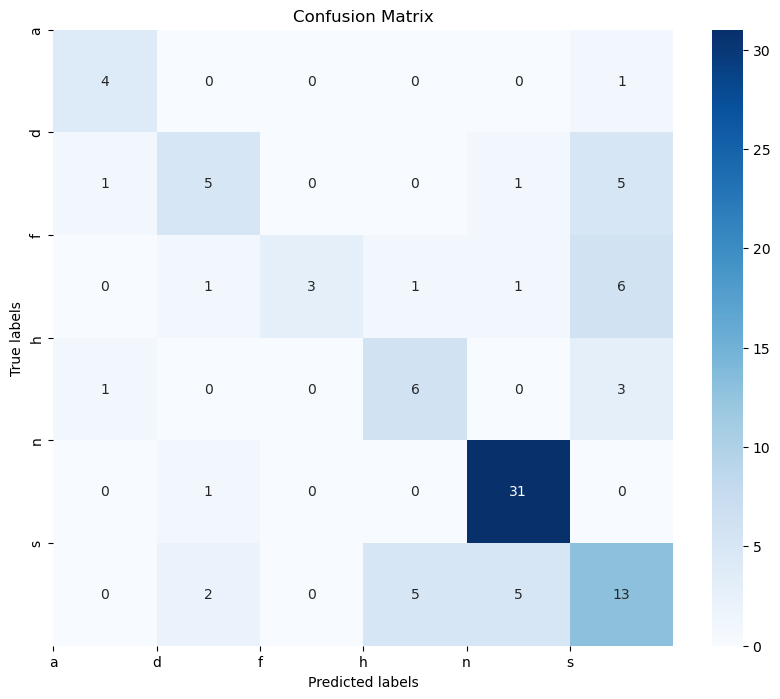

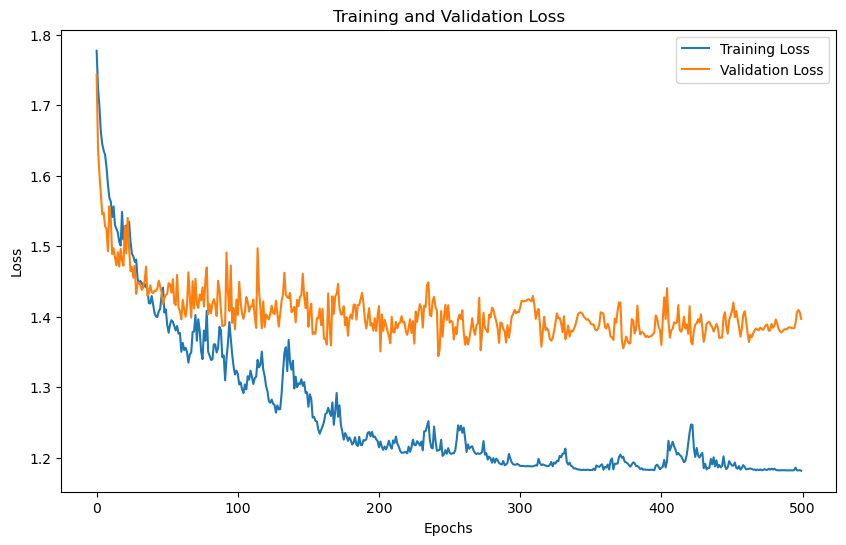

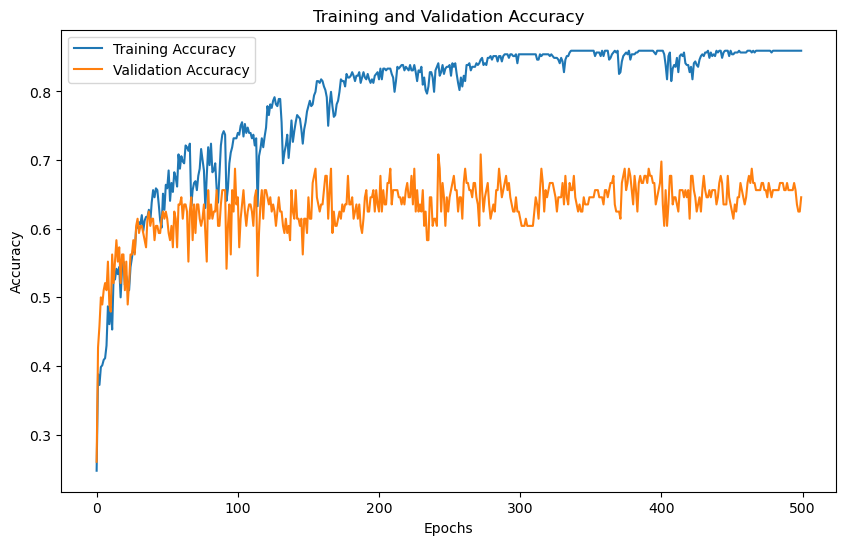

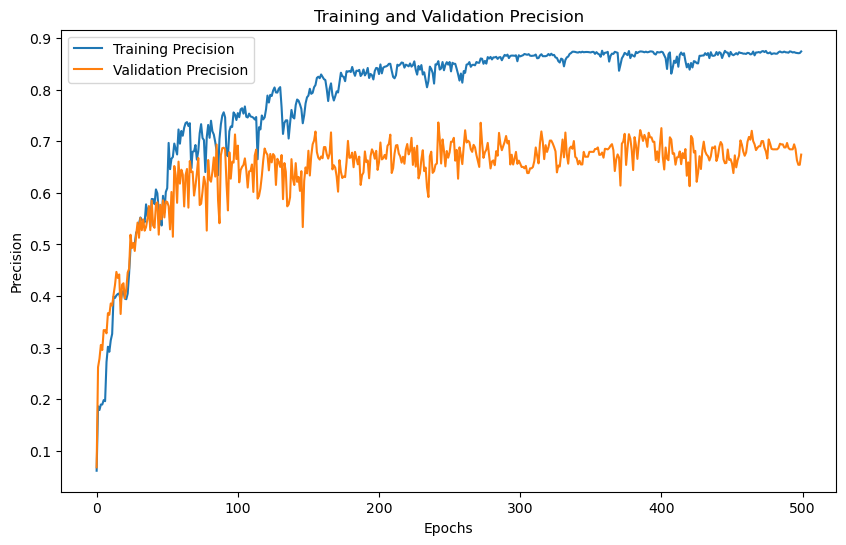

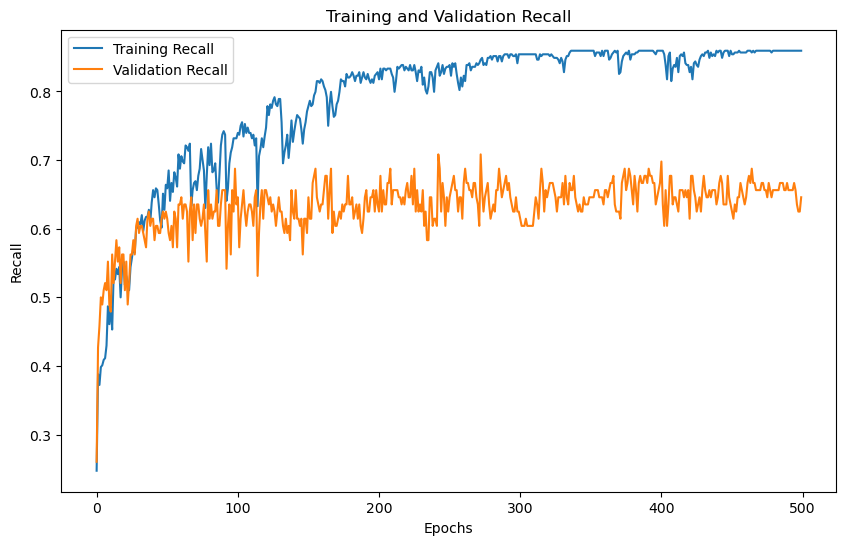

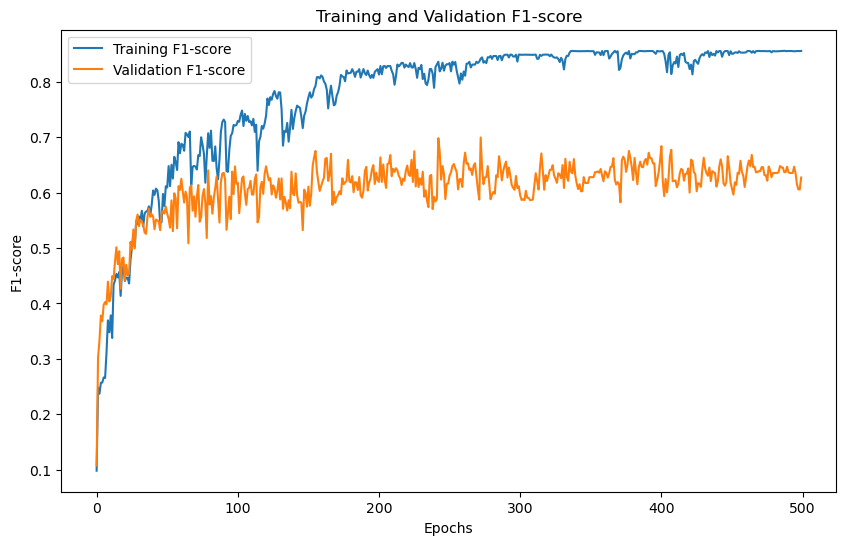

'Model Training and Evaluation Successfully completed'

In [36]:
train_model()

# RAVDESS

# N_MFCC 16

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  16
No. of classes 8
Input size : 16
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (1440, 16)
Y Shape : (1440, 8)
Training with N_MFCC: 16
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0686, Training Accuracy: 0.1875, Training Precision:0.1463,Training Recall:0.1875,Training F1-Score:0.1061
Validation Loss: 2.0414, Validation Accuracy: 0.2257, Validation Precision:0.2125,Validation Recall:0.2257,Validation F1-Score:0.1354
Epoch [2/500],
Training Loss: 2.0173, Training Accuracy: 0.2448, Training Precision:0.1335,Training Recall:0.2448,Training F1-Score:0.1383
Validation Loss: 1.9865, Validation Accuracy: 0.2500, Validation Precision:0.1072,Validation Recall:0.2500,Validation F1-Score:0.1499
Epoch [3/500],
Training Loss: 2.0087, Training Accuracy: 0.2648, Training Precision:0.1348,Training Recall:0.2648,Training F1-Score:0.1683
Validation Loss: 1.9798, Validation Accuracy: 0.2569, Validation Precis

Epoch [31/500],
Training Loss: 1.8980, Training Accuracy: 0.3984, Training Precision:0.4404,Training Recall:0.3984,Training F1-Score:0.3795
Validation Loss: 1.9012, Validation Accuracy: 0.3542, Validation Precision:0.3791,Validation Recall:0.3542,Validation F1-Score:0.3307
Epoch [32/500],
Training Loss: 1.8801, Training Accuracy: 0.4401, Training Precision:0.4448,Training Recall:0.4401,Training F1-Score:0.4251
Validation Loss: 1.8767, Validation Accuracy: 0.3958, Validation Precision:0.4000,Validation Recall:0.3958,Validation F1-Score:0.3746
Epoch [33/500],
Training Loss: 1.8566, Training Accuracy: 0.4418, Training Precision:0.4463,Training Recall:0.4418,Training F1-Score:0.4177
Validation Loss: 1.8604, Validation Accuracy: 0.4201, Validation Precision:0.4254,Validation Recall:0.4201,Validation F1-Score:0.3973
Epoch [34/500],
Training Loss: 1.8545, Training Accuracy: 0.4557, Training Precision:0.4352,Training Recall:0.4557,Training F1-Score:0.4310
Validation Loss: 1.8604, Validation Ac

Epoch [61/500],
Training Loss: 1.7145, Training Accuracy: 0.5920, Training Precision:0.5728,Training Recall:0.5920,Training F1-Score:0.5729
Validation Loss: 1.7964, Validation Accuracy: 0.4757, Validation Precision:0.4682,Validation Recall:0.4757,Validation F1-Score:0.4537
Epoch [62/500],
Training Loss: 1.7080, Training Accuracy: 0.5877, Training Precision:0.6346,Training Recall:0.5877,Training F1-Score:0.5682
Validation Loss: 1.8132, Validation Accuracy: 0.4514, Validation Precision:0.4065,Validation Recall:0.4514,Validation F1-Score:0.4054
Epoch [63/500],
Training Loss: 1.6981, Training Accuracy: 0.6111, Training Precision:0.6149,Training Recall:0.6111,Training F1-Score:0.5958
Validation Loss: 1.7973, Validation Accuracy: 0.4688, Validation Precision:0.4534,Validation Recall:0.4688,Validation F1-Score:0.4435
Epoch [64/500],
Training Loss: 1.6884, Training Accuracy: 0.5946, Training Precision:0.6180,Training Recall:0.5946,Training F1-Score:0.5779
Validation Loss: 1.8033, Validation Ac

Epoch [91/500],
Training Loss: 1.5757, Training Accuracy: 0.7326, Training Precision:0.7496,Training Recall:0.7326,Training F1-Score:0.7236
Validation Loss: 1.7515, Validation Accuracy: 0.5174, Validation Precision:0.5111,Validation Recall:0.5174,Validation F1-Score:0.4991
Epoch [92/500],
Training Loss: 1.5693, Training Accuracy: 0.7014, Training Precision:0.7147,Training Recall:0.7014,Training F1-Score:0.6945
Validation Loss: 1.7718, Validation Accuracy: 0.4931, Validation Precision:0.4875,Validation Recall:0.4931,Validation F1-Score:0.4760
Epoch [93/500],
Training Loss: 1.5697, Training Accuracy: 0.6979, Training Precision:0.7057,Training Recall:0.6979,Training F1-Score:0.6892
Validation Loss: 1.7755, Validation Accuracy: 0.5000, Validation Precision:0.4685,Validation Recall:0.5000,Validation F1-Score:0.4639
Epoch [94/500],
Training Loss: 1.5957, Training Accuracy: 0.6788, Training Precision:0.7243,Training Recall:0.6788,Training F1-Score:0.6625
Validation Loss: 1.7797, Validation Ac

Epoch [121/500],
Training Loss: 1.5247, Training Accuracy: 0.7648, Training Precision:0.7848,Training Recall:0.7648,Training F1-Score:0.7629
Validation Loss: 1.7618, Validation Accuracy: 0.4965, Validation Precision:0.5105,Validation Recall:0.4965,Validation F1-Score:0.4847
Epoch [122/500],
Training Loss: 1.5254, Training Accuracy: 0.7708, Training Precision:0.8009,Training Recall:0.7708,Training F1-Score:0.7631
Validation Loss: 1.7473, Validation Accuracy: 0.5312, Validation Precision:0.5405,Validation Recall:0.5312,Validation F1-Score:0.5116
Epoch [123/500],
Training Loss: 1.5104, Training Accuracy: 0.7969, Training Precision:0.8041,Training Recall:0.7969,Training F1-Score:0.7931
Validation Loss: 1.7433, Validation Accuracy: 0.5312, Validation Precision:0.5360,Validation Recall:0.5312,Validation F1-Score:0.5266
Epoch [124/500],
Training Loss: 1.4953, Training Accuracy: 0.7873, Training Precision:0.8013,Training Recall:0.7873,Training F1-Score:0.7813
Validation Loss: 1.7297, Validatio

...

Epoch [361/500],
Training Loss: 1.3633, Training Accuracy: 0.9115, Training Precision:0.9139,Training Recall:0.9115,Training F1-Score:0.9104
Validation Loss: 1.6662, Validation Accuracy: 0.5903, Validation Precision:0.5982,Validation Recall:0.5903,Validation F1-Score:0.5854
Epoch [362/500],
Training Loss: 1.3649, Training Accuracy: 0.9115, Training Precision:0.9143,Training Recall:0.9115,Training F1-Score:0.9107
Validation Loss: 1.6967, Validation Accuracy: 0.5729, Validation Precision:0.5756,Validation Recall:0.5729,Validation F1-Score:0.5654
Epoch [363/500],
Training Loss: 1.3638, Training Accuracy: 0.9106, Training Precision:0.9132,Training Recall:0.9106,Training F1-Score:0.9095
Validation Loss: 1.6618, Validation Accuracy: 0.6111, Validation Precision:0.6167,Validation Recall:0.6111,Validation F1-Score:0.6059
Epoch [364/500],
Training Loss: 1.3614, Training Accuracy: 0.9115, Training Precision:0.9147,Training Recall:0.9115,Training F1-Score:0.9108
Validation Loss: 1.6823, Validatio

Epoch [391/500],
Training Loss: 1.3657, Training Accuracy: 0.9106, Training Precision:0.9125,Training Recall:0.9106,Training F1-Score:0.9094
Validation Loss: 1.7095, Validation Accuracy: 0.5521, Validation Precision:0.5603,Validation Recall:0.5521,Validation F1-Score:0.5471
Epoch [392/500],
Training Loss: 1.3638, Training Accuracy: 0.9141, Training Precision:0.9158,Training Recall:0.9141,Training F1-Score:0.9134
Validation Loss: 1.6944, Validation Accuracy: 0.5833, Validation Precision:0.5868,Validation Recall:0.5833,Validation F1-Score:0.5772
Epoch [393/500],
Training Loss: 1.3587, Training Accuracy: 0.9158, Training Precision:0.9170,Training Recall:0.9158,Training F1-Score:0.9150
Validation Loss: 1.7061, Validation Accuracy: 0.5556, Validation Precision:0.5640,Validation Recall:0.5556,Validation F1-Score:0.5575
Epoch [394/500],
Training Loss: 1.3580, Training Accuracy: 0.9167, Training Precision:0.9186,Training Recall:0.9167,Training F1-Score:0.9158
Validation Loss: 1.6811, Validatio

Epoch [421/500],
Training Loss: 1.3578, Training Accuracy: 0.9175, Training Precision:0.9186,Training Recall:0.9175,Training F1-Score:0.9164
Validation Loss: 1.6906, Validation Accuracy: 0.5729, Validation Precision:0.5873,Validation Recall:0.5729,Validation F1-Score:0.5757
Epoch [422/500],
Training Loss: 1.3643, Training Accuracy: 0.9149, Training Precision:0.9160,Training Recall:0.9149,Training F1-Score:0.9135
Validation Loss: 1.6886, Validation Accuracy: 0.5694, Validation Precision:0.5772,Validation Recall:0.5694,Validation F1-Score:0.5683
Epoch [423/500],
Training Loss: 1.3640, Training Accuracy: 0.9141, Training Precision:0.9159,Training Recall:0.9141,Training F1-Score:0.9132
Validation Loss: 1.6887, Validation Accuracy: 0.5868, Validation Precision:0.6010,Validation Recall:0.5868,Validation F1-Score:0.5884
Epoch [424/500],
Training Loss: 1.3674, Training Accuracy: 0.9158, Training Precision:0.9171,Training Recall:0.9158,Training F1-Score:0.9148
Validation Loss: 1.6763, Validatio

Epoch [451/500],
Training Loss: 1.3477, Training Accuracy: 0.9245, Training Precision:0.9251,Training Recall:0.9245,Training F1-Score:0.9235
Validation Loss: 1.6639, Validation Accuracy: 0.5972, Validation Precision:0.6093,Validation Recall:0.5972,Validation F1-Score:0.5912
Epoch [452/500],
Training Loss: 1.3494, Training Accuracy: 0.9245, Training Precision:0.9267,Training Recall:0.9245,Training F1-Score:0.9236
Validation Loss: 1.6678, Validation Accuracy: 0.6076, Validation Precision:0.6202,Validation Recall:0.6076,Validation F1-Score:0.6029
Epoch [453/500],
Training Loss: 1.3488, Training Accuracy: 0.9245, Training Precision:0.9253,Training Recall:0.9245,Training F1-Score:0.9234
Validation Loss: 1.6558, Validation Accuracy: 0.6181, Validation Precision:0.6252,Validation Recall:0.6181,Validation F1-Score:0.6131
Epoch [454/500],
Training Loss: 1.3480, Training Accuracy: 0.9245, Training Precision:0.9257,Training Recall:0.9245,Training F1-Score:0.9234
Validation Loss: 1.6663, Validatio

Epoch [481/500],
Training Loss: 1.3472, Training Accuracy: 0.9253, Training Precision:0.9275,Training Recall:0.9253,Training F1-Score:0.9244
Validation Loss: 1.6634, Validation Accuracy: 0.6007, Validation Precision:0.6099,Validation Recall:0.6007,Validation F1-Score:0.5948
Epoch [482/500],
Training Loss: 1.3470, Training Accuracy: 0.9253, Training Precision:0.9265,Training Recall:0.9253,Training F1-Score:0.9243
Validation Loss: 1.6726, Validation Accuracy: 0.5938, Validation Precision:0.6041,Validation Recall:0.5938,Validation F1-Score:0.5890
Epoch [483/500],
Training Loss: 1.3462, Training Accuracy: 0.9253, Training Precision:0.9264,Training Recall:0.9253,Training F1-Score:0.9243
Validation Loss: 1.6740, Validation Accuracy: 0.5903, Validation Precision:0.6004,Validation Recall:0.5903,Validation F1-Score:0.5849
Epoch [484/500],
Training Loss: 1.3461, Training Accuracy: 0.9253, Training Precision:0.9262,Training Recall:0.9253,Training F1-Score:0.9243
Validation Loss: 1.6694, Validatio

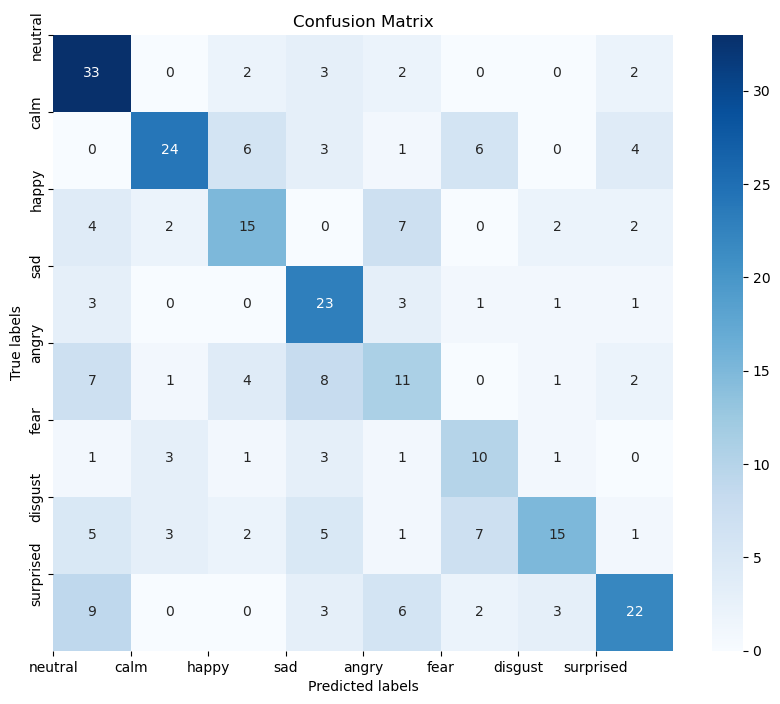

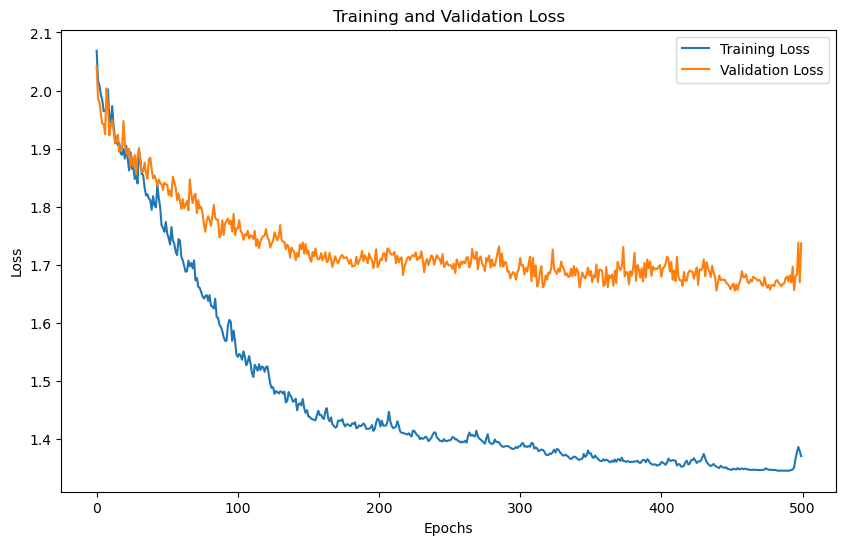

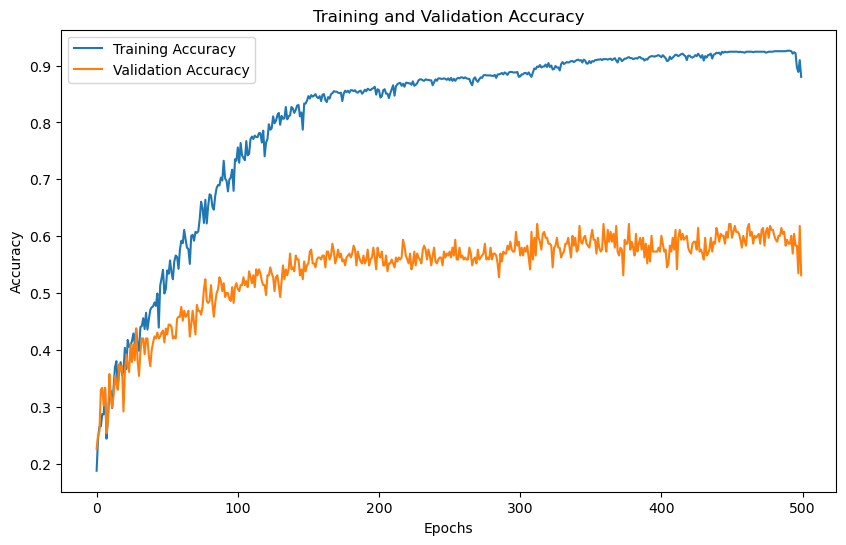

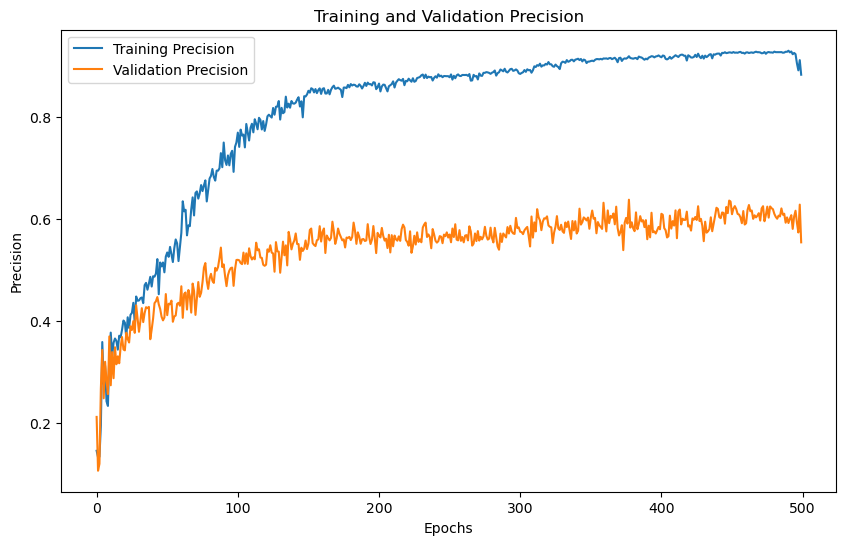

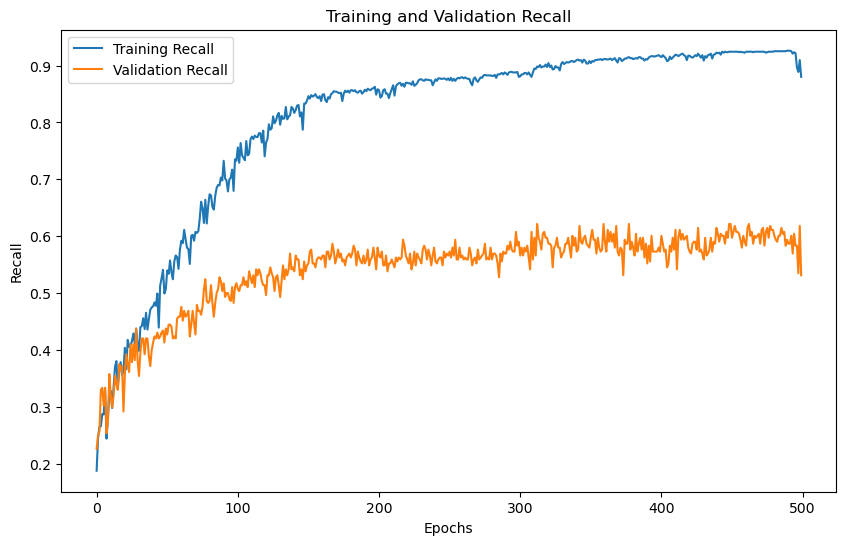

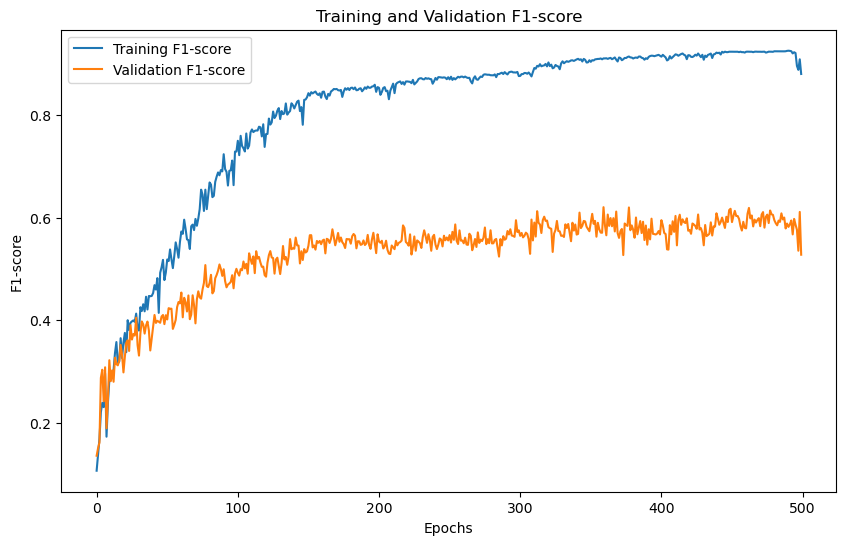

'Model Training and Evaluation Successfully completed'

In [37]:
train_model()

# N_MFCC 24

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  24
No. of classes 8
Input size : 24
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (1440, 24)
Y Shape : (1440, 8)
Training with N_MFCC: 24
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0650, Training Accuracy: 0.1962, Training Precision:0.1106,Training Recall:0.1962,Training F1-Score:0.0918
Validation Loss: 2.0374, Validation Accuracy: 0.2153, Validation Precision:0.0671,Validation Recall:0.2153,Validation F1-Score:0.0958
Epoch [2/500],
Training Loss: 2.0167, Training Accuracy: 0.2448, Training Precision:0.2091,Training Recall:0.2448,Training F1-Score:0.1747
Validation Loss: 1.9733, Validation Accuracy: 0.3056, Validation Precision:0.2604,Validation Recall:0.3056,Validation F1-Score:0.2312
Epoch [3/500],
Training Loss: 1.9810, Training Accuracy: 0.3273, Training Precision:0.3354,Training Recall:0.3273,Training F1-Score:0.2798
Validation Loss: 1.9350, Validation Accuracy: 0.3576, Validation Precis

Epoch [31/500],
Training Loss: 1.7915, Training Accuracy: 0.5260, Training Precision:0.5102,Training Recall:0.5260,Training F1-Score:0.5029
Validation Loss: 1.8277, Validation Accuracy: 0.4479, Validation Precision:0.4210,Validation Recall:0.4479,Validation F1-Score:0.4171
Epoch [32/500],
Training Loss: 1.7733, Training Accuracy: 0.5234, Training Precision:0.5365,Training Recall:0.5234,Training F1-Score:0.5039
Validation Loss: 1.8296, Validation Accuracy: 0.4340, Validation Precision:0.4424,Validation Recall:0.4340,Validation F1-Score:0.4141
Epoch [33/500],
Training Loss: 1.7553, Training Accuracy: 0.5026, Training Precision:0.5206,Training Recall:0.5026,Training F1-Score:0.4613
Validation Loss: 1.8384, Validation Accuracy: 0.4306, Validation Precision:0.4303,Validation Recall:0.4306,Validation F1-Score:0.3837
Epoch [34/500],
Training Loss: 1.7533, Training Accuracy: 0.5434, Training Precision:0.5565,Training Recall:0.5434,Training F1-Score:0.5206
Validation Loss: 1.8299, Validation Ac

Epoch [61/500],
Training Loss: 1.6718, Training Accuracy: 0.6398, Training Precision:0.6184,Training Recall:0.6398,Training F1-Score:0.6172
Validation Loss: 1.7715, Validation Accuracy: 0.5104, Validation Precision:0.5007,Validation Recall:0.5104,Validation F1-Score:0.4952
Epoch [62/500],
Training Loss: 1.6527, Training Accuracy: 0.6181, Training Precision:0.5964,Training Recall:0.6181,Training F1-Score:0.5940
Validation Loss: 1.7842, Validation Accuracy: 0.4688, Validation Precision:0.4449,Validation Recall:0.4688,Validation F1-Score:0.4433
Epoch [63/500],
Training Loss: 1.6978, Training Accuracy: 0.6241, Training Precision:0.6150,Training Recall:0.6241,Training F1-Score:0.6040
Validation Loss: 1.7681, Validation Accuracy: 0.5104, Validation Precision:0.5009,Validation Recall:0.5104,Validation F1-Score:0.4948
Epoch [64/500],
Training Loss: 1.6666, Training Accuracy: 0.6250, Training Precision:0.5916,Training Recall:0.6250,Training F1-Score:0.5990
Validation Loss: 1.7967, Validation Ac

Epoch [91/500],
Training Loss: 1.5780, Training Accuracy: 0.7170, Training Precision:0.6811,Training Recall:0.7170,Training F1-Score:0.6929
Validation Loss: 1.7290, Validation Accuracy: 0.5590, Validation Precision:0.5300,Validation Recall:0.5590,Validation F1-Score:0.5372
Epoch [92/500],
Training Loss: 1.5632, Training Accuracy: 0.7352, Training Precision:0.7009,Training Recall:0.7352,Training F1-Score:0.7086
Validation Loss: 1.7146, Validation Accuracy: 0.5590, Validation Precision:0.5210,Validation Recall:0.5590,Validation F1-Score:0.5346
Epoch [93/500],
Training Loss: 1.5664, Training Accuracy: 0.7335, Training Precision:0.7672,Training Recall:0.7335,Training F1-Score:0.7103
Validation Loss: 1.7278, Validation Accuracy: 0.5347, Validation Precision:0.5105,Validation Recall:0.5347,Validation F1-Score:0.5112
Epoch [94/500],
Training Loss: 1.5604, Training Accuracy: 0.7422, Training Precision:0.7810,Training Recall:0.7422,Training F1-Score:0.7185
Validation Loss: 1.7092, Validation Ac

Epoch [121/500],
Training Loss: 1.5011, Training Accuracy: 0.7465, Training Precision:0.7904,Training Recall:0.7465,Training F1-Score:0.7268
Validation Loss: 1.7392, Validation Accuracy: 0.5208, Validation Precision:0.5247,Validation Recall:0.5208,Validation F1-Score:0.4935
Epoch [122/500],
Training Loss: 1.5193, Training Accuracy: 0.7700, Training Precision:0.8021,Training Recall:0.7700,Training F1-Score:0.7504
Validation Loss: 1.7241, Validation Accuracy: 0.5451, Validation Precision:0.5166,Validation Recall:0.5451,Validation F1-Score:0.5224
Epoch [123/500],
Training Loss: 1.4983, Training Accuracy: 0.7899, Training Precision:0.7995,Training Recall:0.7899,Training F1-Score:0.7686
Validation Loss: 1.6959, Validation Accuracy: 0.5868, Validation Precision:0.5739,Validation Recall:0.5868,Validation F1-Score:0.5689
Epoch [124/500],
Training Loss: 1.4956, Training Accuracy: 0.7839, Training Precision:0.8156,Training Recall:0.7839,Training F1-Score:0.7647
Validation Loss: 1.6847, Validatio

...

Epoch [361/500],
Training Loss: 1.3234, Training Accuracy: 0.9557, Training Precision:0.9561,Training Recall:0.9557,Training F1-Score:0.9555
Validation Loss: 1.6557, Validation Accuracy: 0.6215, Validation Precision:0.6304,Validation Recall:0.6215,Validation F1-Score:0.6192
Epoch [362/500],
Training Loss: 1.3226, Training Accuracy: 0.9575, Training Precision:0.9579,Training Recall:0.9575,Training F1-Score:0.9573
Validation Loss: 1.6638, Validation Accuracy: 0.6007, Validation Precision:0.6188,Validation Recall:0.6007,Validation F1-Score:0.6025
Epoch [363/500],
Training Loss: 1.3213, Training Accuracy: 0.9531, Training Precision:0.9534,Training Recall:0.9531,Training F1-Score:0.9527
Validation Loss: 1.6539, Validation Accuracy: 0.6215, Validation Precision:0.6320,Validation Recall:0.6215,Validation F1-Score:0.6159
Epoch [364/500],
Training Loss: 1.3225, Training Accuracy: 0.9557, Training Precision:0.9562,Training Recall:0.9557,Training F1-Score:0.9554
Validation Loss: 1.6625, Validatio

Epoch [391/500],
Training Loss: 1.3151, Training Accuracy: 0.9592, Training Precision:0.9595,Training Recall:0.9592,Training F1-Score:0.9589
Validation Loss: 1.6521, Validation Accuracy: 0.6250, Validation Precision:0.6422,Validation Recall:0.6250,Validation F1-Score:0.6210
Epoch [392/500],
Training Loss: 1.3142, Training Accuracy: 0.9592, Training Precision:0.9592,Training Recall:0.9592,Training F1-Score:0.9589
Validation Loss: 1.6580, Validation Accuracy: 0.6215, Validation Precision:0.6399,Validation Recall:0.6215,Validation F1-Score:0.6182
Epoch [393/500],
Training Loss: 1.3143, Training Accuracy: 0.9549, Training Precision:0.9547,Training Recall:0.9549,Training F1-Score:0.9546
Validation Loss: 1.6713, Validation Accuracy: 0.5938, Validation Precision:0.6318,Validation Recall:0.5938,Validation F1-Score:0.5993
Epoch [394/500],
Training Loss: 1.3165, Training Accuracy: 0.9583, Training Precision:0.9588,Training Recall:0.9583,Training F1-Score:0.9581
Validation Loss: 1.6364, Validatio

Epoch [421/500],
Training Loss: 1.3156, Training Accuracy: 0.9601, Training Precision:0.9602,Training Recall:0.9601,Training F1-Score:0.9598
Validation Loss: 1.6248, Validation Accuracy: 0.6424, Validation Precision:0.6566,Validation Recall:0.6424,Validation F1-Score:0.6374
Epoch [422/500],
Training Loss: 1.3139, Training Accuracy: 0.9583, Training Precision:0.9591,Training Recall:0.9583,Training F1-Score:0.9582
Validation Loss: 1.6275, Validation Accuracy: 0.6424, Validation Precision:0.6503,Validation Recall:0.6424,Validation F1-Score:0.6389
Epoch [423/500],
Training Loss: 1.3160, Training Accuracy: 0.9497, Training Precision:0.9508,Training Recall:0.9497,Training F1-Score:0.9493
Validation Loss: 1.6807, Validation Accuracy: 0.5938, Validation Precision:0.6248,Validation Recall:0.5938,Validation F1-Score:0.5901
Epoch [424/500],
Training Loss: 1.3258, Training Accuracy: 0.9540, Training Precision:0.9541,Training Recall:0.9540,Training F1-Score:0.9539
Validation Loss: 1.6195, Validatio

Epoch [451/500],
Training Loss: 1.3117, Training Accuracy: 0.9609, Training Precision:0.9615,Training Recall:0.9609,Training F1-Score:0.9607
Validation Loss: 1.6255, Validation Accuracy: 0.6562, Validation Precision:0.6680,Validation Recall:0.6562,Validation F1-Score:0.6528
Epoch [452/500],
Training Loss: 1.3116, Training Accuracy: 0.9609, Training Precision:0.9611,Training Recall:0.9609,Training F1-Score:0.9607
Validation Loss: 1.6291, Validation Accuracy: 0.6458, Validation Precision:0.6569,Validation Recall:0.6458,Validation F1-Score:0.6427
Epoch [453/500],
Training Loss: 1.3114, Training Accuracy: 0.9618, Training Precision:0.9620,Training Recall:0.9618,Training F1-Score:0.9616
Validation Loss: 1.6289, Validation Accuracy: 0.6458, Validation Precision:0.6539,Validation Recall:0.6458,Validation F1-Score:0.6430
Epoch [454/500],
Training Loss: 1.3107, Training Accuracy: 0.9627, Training Precision:0.9629,Training Recall:0.9627,Training F1-Score:0.9624
Validation Loss: 1.6351, Validatio

Epoch [481/500],
Training Loss: 1.3059, Training Accuracy: 0.9670, Training Precision:0.9675,Training Recall:0.9670,Training F1-Score:0.9668
Validation Loss: 1.6349, Validation Accuracy: 0.6424, Validation Precision:0.6566,Validation Recall:0.6424,Validation F1-Score:0.6401
Epoch [482/500],
Training Loss: 1.3059, Training Accuracy: 0.9670, Training Precision:0.9672,Training Recall:0.9670,Training F1-Score:0.9668
Validation Loss: 1.6377, Validation Accuracy: 0.6389, Validation Precision:0.6519,Validation Recall:0.6389,Validation F1-Score:0.6368
Epoch [483/500],
Training Loss: 1.3058, Training Accuracy: 0.9670, Training Precision:0.9670,Training Recall:0.9670,Training F1-Score:0.9667
Validation Loss: 1.6388, Validation Accuracy: 0.6424, Validation Precision:0.6561,Validation Recall:0.6424,Validation F1-Score:0.6400
Epoch [484/500],
Training Loss: 1.3058, Training Accuracy: 0.9670, Training Precision:0.9673,Training Recall:0.9670,Training F1-Score:0.9668
Validation Loss: 1.6370, Validatio

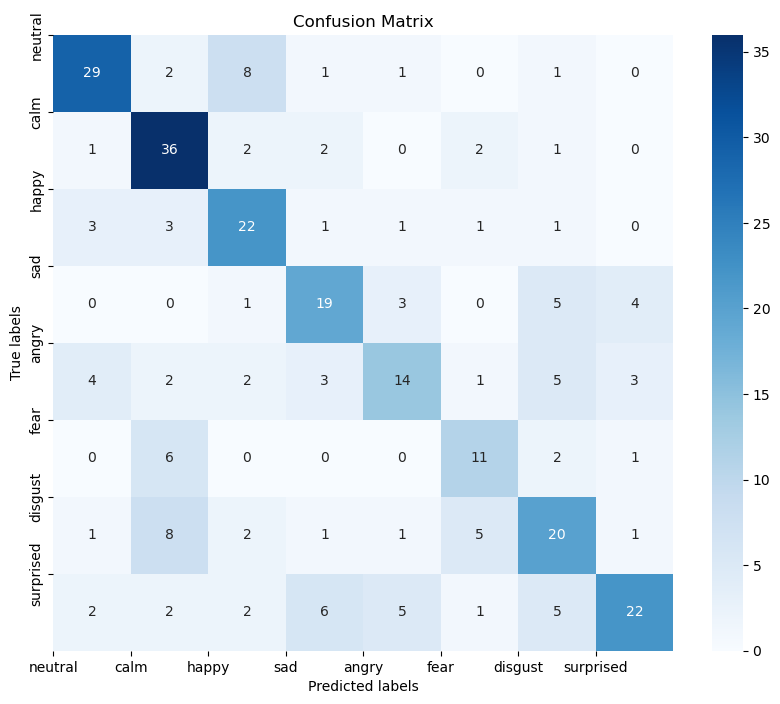

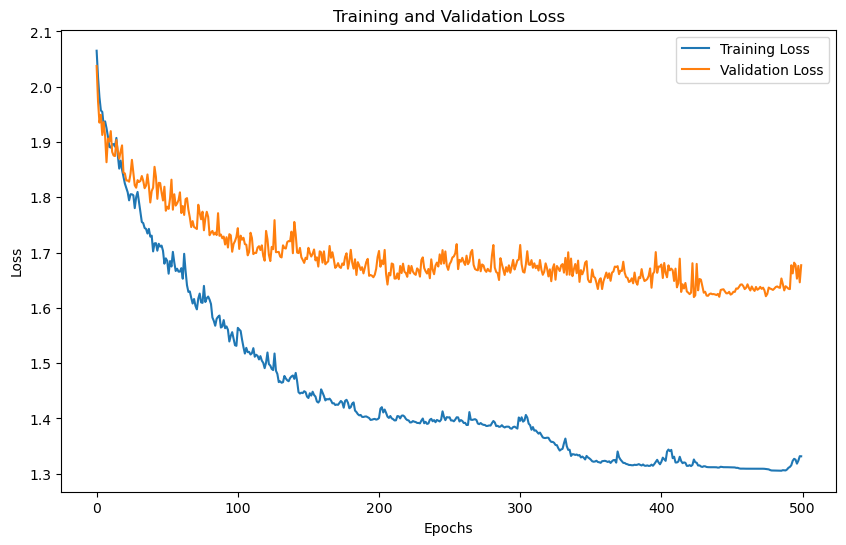

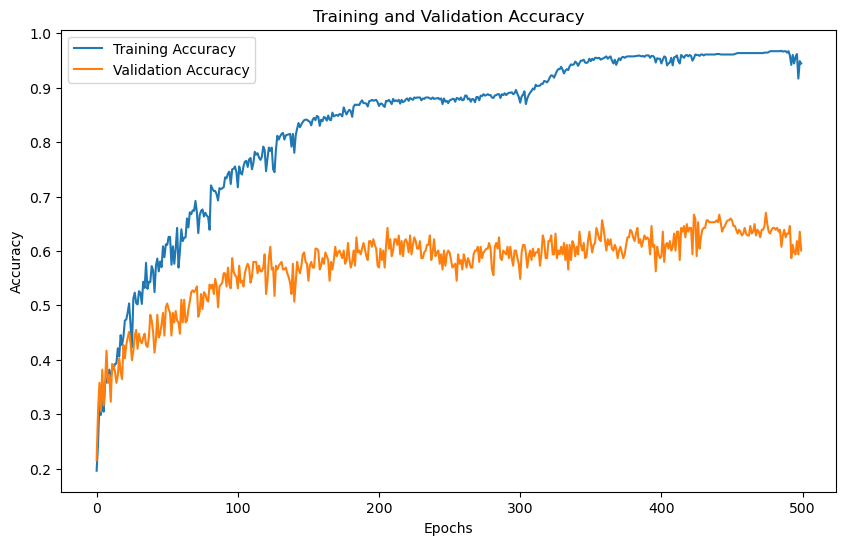

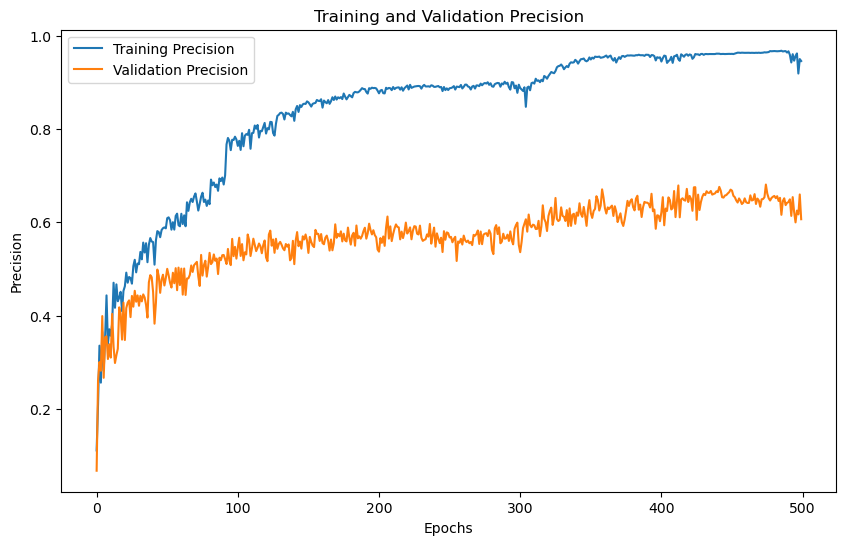

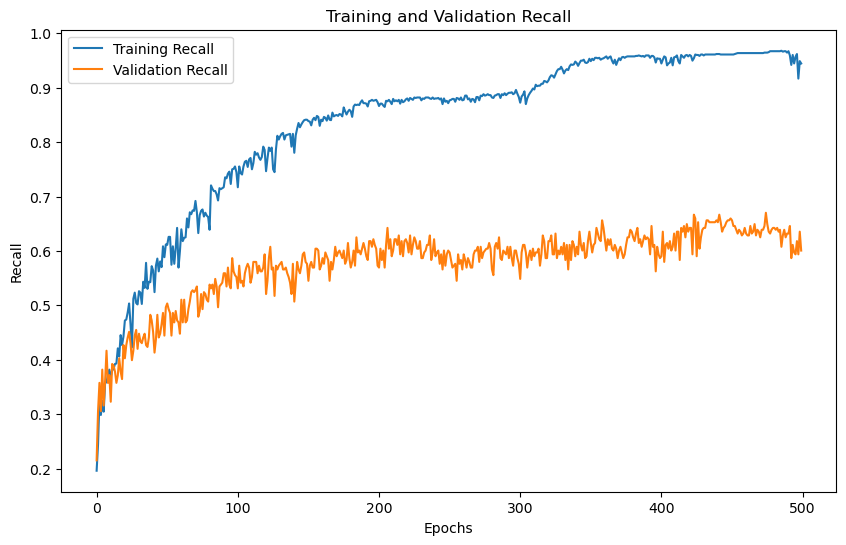

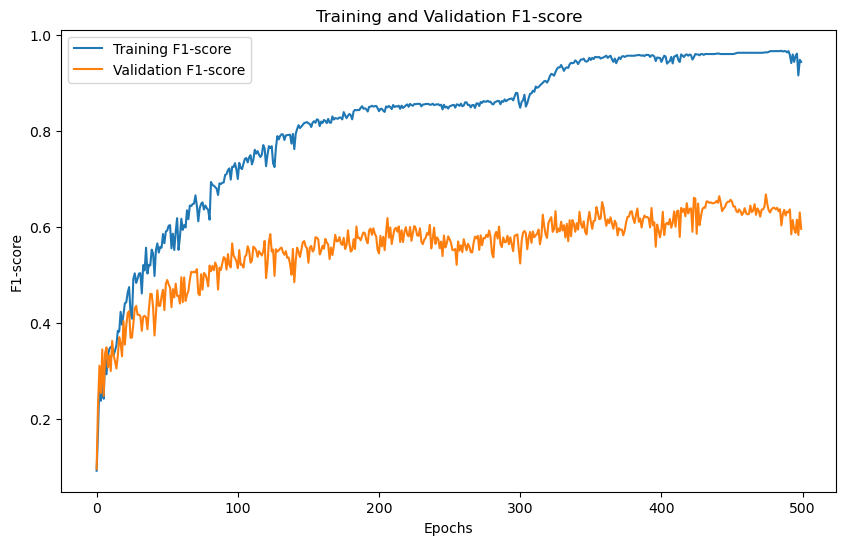

'Model Training and Evaluation Successfully completed'

In [38]:
train_model()

# N_MFCC 32

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  32
No. of classes 8
Input size : 32
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (1440, 32)
Y Shape : (1440, 8)
Training with N_MFCC: 32
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0740, Training Accuracy: 0.2257, Training Precision:0.0917,Training Recall:0.2257,Training F1-Score:0.1301
Validation Loss: 2.0629, Validation Accuracy: 0.2222, Validation Precision:0.0854,Validation Recall:0.2222,Validation F1-Score:0.1225
Epoch [2/500],
Training Loss: 2.0257, Training Accuracy: 0.2491, Training Precision:0.2836,Training Recall:0.2491,Training F1-Score:0.2072
Validation Loss: 1.9922, Validation Accuracy: 0.2639, Validation Precision:0.2998,Validation Recall:0.2639,Validation F1-Score:0.2257
Epoch [3/500],
Training Loss: 1.9988, Training Accuracy: 0.2613, Training Precision:0.2770,Training Recall:0.2613,Training F1-Score:0.2007
Validation Loss: 1.9784, Validation Accuracy: 0.2882, Validation Precis

Epoch [31/500],
Training Loss: 1.8050, Training Accuracy: 0.4757, Training Precision:0.4742,Training Recall:0.4757,Training F1-Score:0.4579
Validation Loss: 1.8463, Validation Accuracy: 0.4201, Validation Precision:0.4250,Validation Recall:0.4201,Validation F1-Score:0.4010
Epoch [32/500],
Training Loss: 1.7984, Training Accuracy: 0.4913, Training Precision:0.4656,Training Recall:0.4913,Training F1-Score:0.4594
Validation Loss: 1.8318, Validation Accuracy: 0.4306, Validation Precision:0.3768,Validation Recall:0.4306,Validation F1-Score:0.3955
Epoch [33/500],
Training Loss: 1.7883, Training Accuracy: 0.4774, Training Precision:0.4542,Training Recall:0.4774,Training F1-Score:0.4546
Validation Loss: 1.8600, Validation Accuracy: 0.4062, Validation Precision:0.3638,Validation Recall:0.4062,Validation F1-Score:0.3667
Epoch [34/500],
Training Loss: 1.8020, Training Accuracy: 0.4332, Training Precision:0.4935,Training Recall:0.4332,Training F1-Score:0.4264
Validation Loss: 1.8790, Validation Ac

Epoch [61/500],
Training Loss: 1.7029, Training Accuracy: 0.5564, Training Precision:0.5581,Training Recall:0.5564,Training F1-Score:0.5299
Validation Loss: 1.8114, Validation Accuracy: 0.4549, Validation Precision:0.4167,Validation Recall:0.4549,Validation F1-Score:0.3955
Epoch [62/500],
Training Loss: 1.7150, Training Accuracy: 0.5729, Training Precision:0.5589,Training Recall:0.5729,Training F1-Score:0.5521
Validation Loss: 1.7813, Validation Accuracy: 0.4896, Validation Precision:0.4720,Validation Recall:0.4896,Validation F1-Score:0.4574
Epoch [63/500],
Training Loss: 1.7040, Training Accuracy: 0.5877, Training Precision:0.5718,Training Recall:0.5877,Training F1-Score:0.5670
Validation Loss: 1.7917, Validation Accuracy: 0.4792, Validation Precision:0.4740,Validation Recall:0.4792,Validation F1-Score:0.4555
Epoch [64/500],
Training Loss: 1.6901, Training Accuracy: 0.5573, Training Precision:0.5596,Training Recall:0.5573,Training F1-Score:0.5384
Validation Loss: 1.8230, Validation Ac

Epoch [91/500],
Training Loss: 1.6351, Training Accuracy: 0.6372, Training Precision:0.6153,Training Recall:0.6372,Training F1-Score:0.6188
Validation Loss: 1.7718, Validation Accuracy: 0.4931, Validation Precision:0.4914,Validation Recall:0.4931,Validation F1-Score:0.4774
Epoch [92/500],
Training Loss: 1.6469, Training Accuracy: 0.6536, Training Precision:0.6432,Training Recall:0.6536,Training F1-Score:0.6336
Validation Loss: 1.7566, Validation Accuracy: 0.5208, Validation Precision:0.5397,Validation Recall:0.5208,Validation F1-Score:0.4998
Epoch [93/500],
Training Loss: 1.6281, Training Accuracy: 0.6345, Training Precision:0.6309,Training Recall:0.6345,Training F1-Score:0.6162
Validation Loss: 1.7540, Validation Accuracy: 0.5139, Validation Precision:0.5336,Validation Recall:0.5139,Validation F1-Score:0.5001
Epoch [94/500],
Training Loss: 1.6231, Training Accuracy: 0.6554, Training Precision:0.6460,Training Recall:0.6554,Training F1-Score:0.6395
Validation Loss: 1.7483, Validation Ac

Epoch [121/500],
Training Loss: 1.5567, Training Accuracy: 0.7257, Training Precision:0.7167,Training Recall:0.7257,Training F1-Score:0.7077
Validation Loss: 1.7437, Validation Accuracy: 0.5312, Validation Precision:0.5431,Validation Recall:0.5312,Validation F1-Score:0.5063
Epoch [122/500],
Training Loss: 1.5600, Training Accuracy: 0.7483, Training Precision:0.7190,Training Recall:0.7483,Training F1-Score:0.7253
Validation Loss: 1.7243, Validation Accuracy: 0.5347, Validation Precision:0.5274,Validation Recall:0.5347,Validation F1-Score:0.5095
Epoch [123/500],
Training Loss: 1.5554, Training Accuracy: 0.6979, Training Precision:0.6718,Training Recall:0.6979,Training F1-Score:0.6711
Validation Loss: 1.7346, Validation Accuracy: 0.5451, Validation Precision:0.5207,Validation Recall:0.5451,Validation F1-Score:0.5082
Epoch [124/500],
Training Loss: 1.5489, Training Accuracy: 0.7543, Training Precision:0.7270,Training Recall:0.7543,Training F1-Score:0.7323
Validation Loss: 1.7220, Validatio

...

Epoch [361/500],
Training Loss: 1.3842, Training Accuracy: 0.8967, Training Precision:0.9033,Training Recall:0.8967,Training F1-Score:0.8867
Validation Loss: 1.6675, Validation Accuracy: 0.6111, Validation Precision:0.6058,Validation Recall:0.6111,Validation F1-Score:0.5969
Epoch [362/500],
Training Loss: 1.3766, Training Accuracy: 0.8941, Training Precision:0.8987,Training Recall:0.8941,Training F1-Score:0.8830
Validation Loss: 1.6738, Validation Accuracy: 0.6007, Validation Precision:0.5943,Validation Recall:0.6007,Validation F1-Score:0.5896
Epoch [363/500],
Training Loss: 1.3791, Training Accuracy: 0.8950, Training Precision:0.8971,Training Recall:0.8950,Training F1-Score:0.8831
Validation Loss: 1.7027, Validation Accuracy: 0.5625, Validation Precision:0.5659,Validation Recall:0.5625,Validation F1-Score:0.5520
Epoch [364/500],
Training Loss: 1.3828, Training Accuracy: 0.8958, Training Precision:0.9051,Training Recall:0.8958,Training F1-Score:0.8846
Validation Loss: 1.6836, Validatio

Epoch [391/500],
Training Loss: 1.3686, Training Accuracy: 0.9045, Training Precision:0.9097,Training Recall:0.9045,Training F1-Score:0.8953
Validation Loss: 1.6726, Validation Accuracy: 0.6042, Validation Precision:0.6017,Validation Recall:0.6042,Validation F1-Score:0.5944
Epoch [392/500],
Training Loss: 1.3663, Training Accuracy: 0.9089, Training Precision:0.9115,Training Recall:0.9089,Training F1-Score:0.8988
Validation Loss: 1.6699, Validation Accuracy: 0.5903, Validation Precision:0.5897,Validation Recall:0.5903,Validation F1-Score:0.5746
Epoch [393/500],
Training Loss: 1.3641, Training Accuracy: 0.9097, Training Precision:0.9157,Training Recall:0.9097,Training F1-Score:0.8999
Validation Loss: 1.6611, Validation Accuracy: 0.6076, Validation Precision:0.6027,Validation Recall:0.6076,Validation F1-Score:0.5923
Epoch [394/500],
Training Loss: 1.3656, Training Accuracy: 0.9080, Training Precision:0.9096,Training Recall:0.9080,Training F1-Score:0.8977
Validation Loss: 1.6580, Validatio

Epoch [421/500],
Training Loss: 1.3608, Training Accuracy: 0.9115, Training Precision:0.9085,Training Recall:0.9115,Training F1-Score:0.9014
Validation Loss: 1.6808, Validation Accuracy: 0.5833, Validation Precision:0.5789,Validation Recall:0.5833,Validation F1-Score:0.5736
Epoch [422/500],
Training Loss: 1.3594, Training Accuracy: 0.9141, Training Precision:0.9189,Training Recall:0.9141,Training F1-Score:0.9034
Validation Loss: 1.6639, Validation Accuracy: 0.6146, Validation Precision:0.5994,Validation Recall:0.6146,Validation F1-Score:0.6007
Epoch [423/500],
Training Loss: 1.3593, Training Accuracy: 0.9141, Training Precision:0.9183,Training Recall:0.9141,Training F1-Score:0.9039
Validation Loss: 1.6678, Validation Accuracy: 0.5972, Validation Precision:0.5830,Validation Recall:0.5972,Validation F1-Score:0.5797
Epoch [424/500],
Training Loss: 1.3582, Training Accuracy: 0.9141, Training Precision:0.9146,Training Recall:0.9141,Training F1-Score:0.9035
Validation Loss: 1.6617, Validatio

Epoch [451/500],
Training Loss: 1.3741, Training Accuracy: 0.8958, Training Precision:0.8976,Training Recall:0.8958,Training F1-Score:0.8856
Validation Loss: 1.6984, Validation Accuracy: 0.5694, Validation Precision:0.5669,Validation Recall:0.5694,Validation F1-Score:0.5516
Epoch [452/500],
Training Loss: 1.3884, Training Accuracy: 0.8967, Training Precision:0.9005,Training Recall:0.8967,Training F1-Score:0.8868
Validation Loss: 1.6816, Validation Accuracy: 0.5938, Validation Precision:0.5945,Validation Recall:0.5938,Validation F1-Score:0.5874
Epoch [453/500],
Training Loss: 1.3773, Training Accuracy: 0.9019, Training Precision:0.9062,Training Recall:0.9019,Training F1-Score:0.8907
Validation Loss: 1.6797, Validation Accuracy: 0.6007, Validation Precision:0.6161,Validation Recall:0.6007,Validation F1-Score:0.5900
Epoch [454/500],
Training Loss: 1.3713, Training Accuracy: 0.9062, Training Precision:0.9066,Training Recall:0.9062,Training F1-Score:0.8957
Validation Loss: 1.6616, Validatio

Epoch [481/500],
Training Loss: 1.3554, Training Accuracy: 0.9184, Training Precision:0.9229,Training Recall:0.9184,Training F1-Score:0.9093
Validation Loss: 1.6494, Validation Accuracy: 0.6319, Validation Precision:0.6352,Validation Recall:0.6319,Validation F1-Score:0.6186
Epoch [482/500],
Training Loss: 1.3535, Training Accuracy: 0.9210, Training Precision:0.9220,Training Recall:0.9210,Training F1-Score:0.9129
Validation Loss: 1.6517, Validation Accuracy: 0.6146, Validation Precision:0.6136,Validation Recall:0.6146,Validation F1-Score:0.6012
Epoch [483/500],
Training Loss: 1.3527, Training Accuracy: 0.9219, Training Precision:0.9203,Training Recall:0.9219,Training F1-Score:0.9146
Validation Loss: 1.6438, Validation Accuracy: 0.6319, Validation Precision:0.6409,Validation Recall:0.6319,Validation F1-Score:0.6211
Epoch [484/500],
Training Loss: 1.3503, Training Accuracy: 0.9219, Training Precision:0.9270,Training Recall:0.9219,Training F1-Score:0.9144
Validation Loss: 1.6469, Validatio

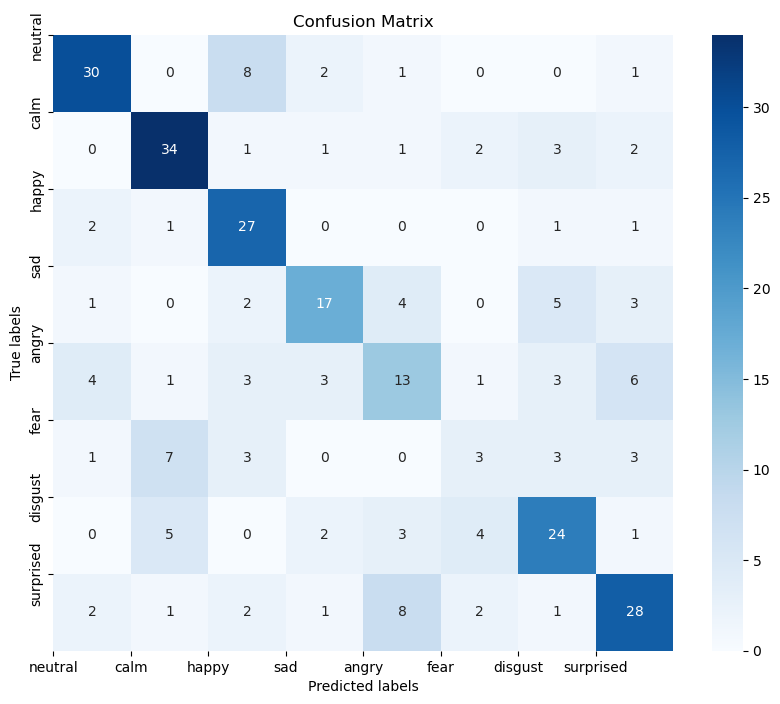

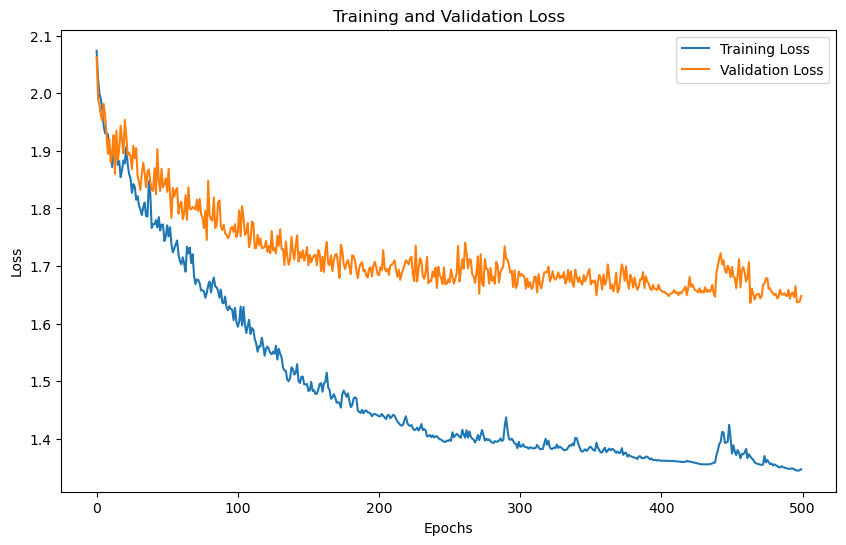

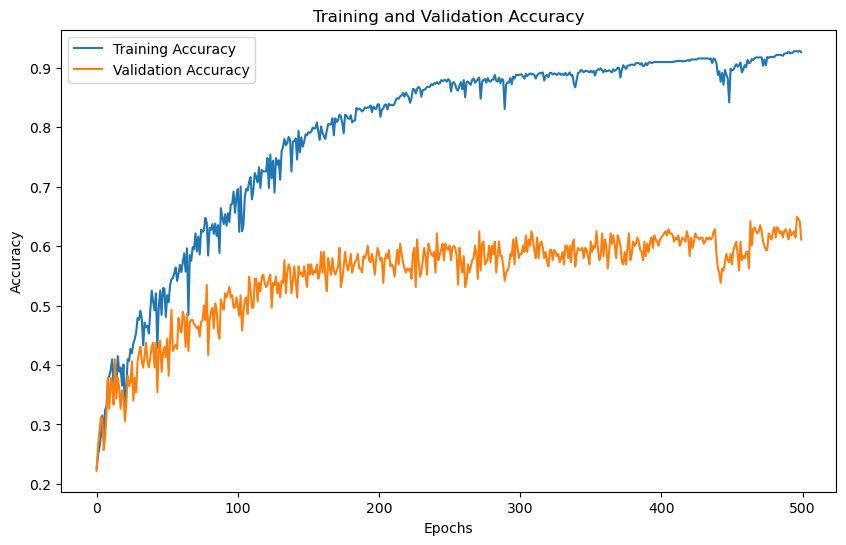

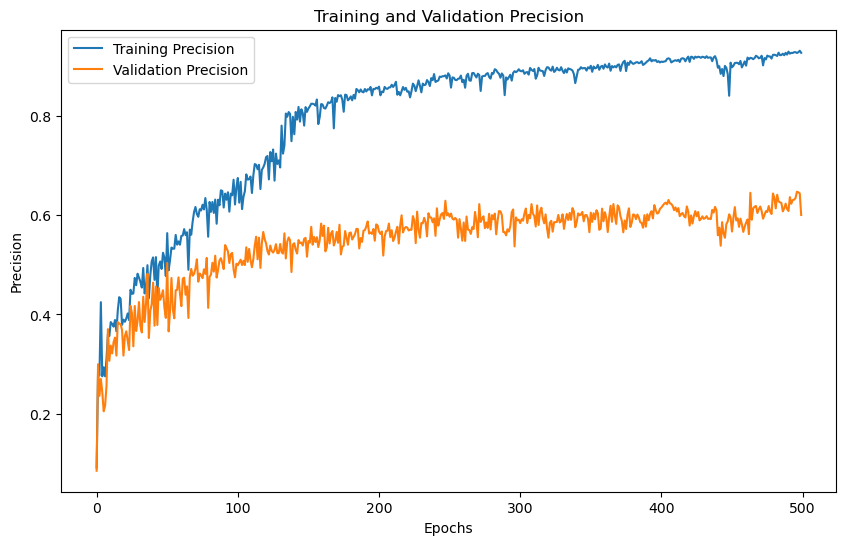

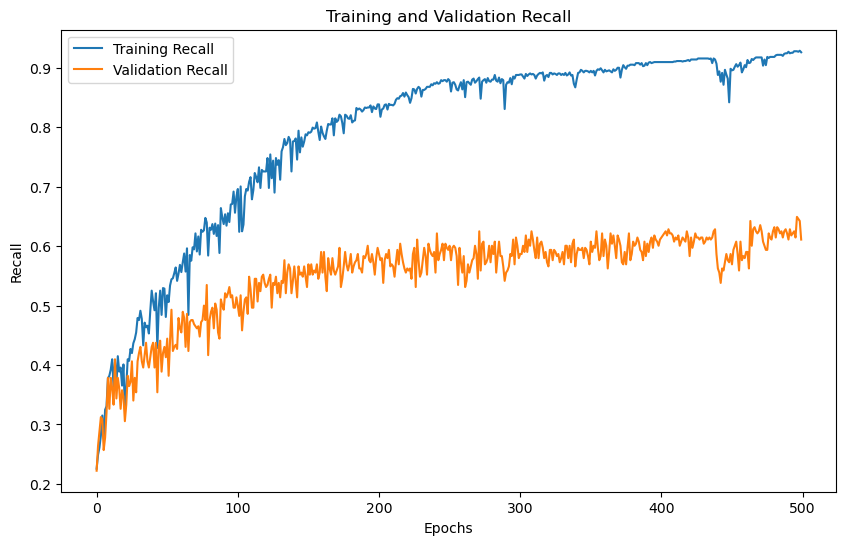

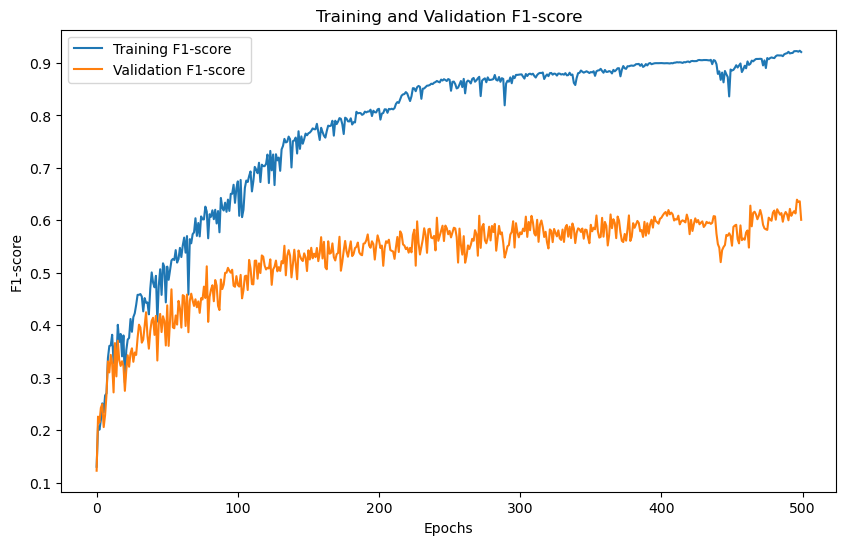

'Model Training and Evaluation Successfully completed'

In [39]:
train_model()

# N_MFCC 40

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  40
No. of classes 8
Input size : 40
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (1440, 40)
Y Shape : (1440, 8)
Training with N_MFCC: 40
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0756, Training Accuracy: 0.1606, Training Precision:0.0462,Training Recall:0.1606,Training F1-Score:0.0688
Validation Loss: 2.0744, Validation Accuracy: 0.1215, Validation Precision:0.0268,Validation Recall:0.1215,Validation F1-Score:0.0434
Epoch [2/500],
Training Loss: 2.0427, Training Accuracy: 0.2326, Training Precision:0.1510,Training Recall:0.2326,Training F1-Score:0.1462
Validation Loss: 2.0109, Validation Accuracy: 0.2188, Validation Precision:0.1051,Validation Recall:0.2188,Validation F1-Score:0.1266
Epoch [3/500],
Training Loss: 2.0153, Training Accuracy: 0.2613, Training Precision:0.1825,Training Recall:0.2613,Training F1-Score:0.1789
Validation Loss: 1.9652, Validation Accuracy: 0.3090, Validation Precis

Epoch [31/500],
Training Loss: 1.8083, Training Accuracy: 0.4861, Training Precision:0.4904,Training Recall:0.4861,Training F1-Score:0.4615
Validation Loss: 1.8029, Validation Accuracy: 0.4653, Validation Precision:0.4715,Validation Recall:0.4653,Validation F1-Score:0.4393
Epoch [32/500],
Training Loss: 1.8085, Training Accuracy: 0.4722, Training Precision:0.4584,Training Recall:0.4722,Training F1-Score:0.4443
Validation Loss: 1.8480, Validation Accuracy: 0.4132, Validation Precision:0.3876,Validation Recall:0.4132,Validation F1-Score:0.3766
Epoch [33/500],
Training Loss: 1.7909, Training Accuracy: 0.4974, Training Precision:0.4861,Training Recall:0.4974,Training F1-Score:0.4736
Validation Loss: 1.8382, Validation Accuracy: 0.4375, Validation Precision:0.4098,Validation Recall:0.4375,Validation F1-Score:0.3980
Epoch [34/500],
Training Loss: 1.7767, Training Accuracy: 0.5260, Training Precision:0.5149,Training Recall:0.5260,Training F1-Score:0.5030
Validation Loss: 1.7956, Validation Ac

Epoch [61/500],
Training Loss: 1.6662, Training Accuracy: 0.6293, Training Precision:0.6433,Training Recall:0.6293,Training F1-Score:0.6083
Validation Loss: 1.7727, Validation Accuracy: 0.4931, Validation Precision:0.4703,Validation Recall:0.4931,Validation F1-Score:0.4644
Epoch [62/500],
Training Loss: 1.6743, Training Accuracy: 0.6094, Training Precision:0.6139,Training Recall:0.6094,Training F1-Score:0.6004
Validation Loss: 1.7926, Validation Accuracy: 0.4931, Validation Precision:0.5161,Validation Recall:0.4931,Validation F1-Score:0.4880
Epoch [63/500],
Training Loss: 1.6555, Training Accuracy: 0.6033, Training Precision:0.6384,Training Recall:0.6033,Training F1-Score:0.6007
Validation Loss: 1.8037, Validation Accuracy: 0.4618, Validation Precision:0.5019,Validation Recall:0.4618,Validation F1-Score:0.4592
Epoch [64/500],
Training Loss: 1.6573, Training Accuracy: 0.6250, Training Precision:0.6635,Training Recall:0.6250,Training F1-Score:0.6120
Validation Loss: 1.8073, Validation Ac

Epoch [91/500],
Training Loss: 1.5342, Training Accuracy: 0.7604, Training Precision:0.7774,Training Recall:0.7604,Training F1-Score:0.7546
Validation Loss: 1.7279, Validation Accuracy: 0.5451, Validation Precision:0.5493,Validation Recall:0.5451,Validation F1-Score:0.5290
Epoch [92/500],
Training Loss: 1.5428, Training Accuracy: 0.7526, Training Precision:0.7603,Training Recall:0.7526,Training F1-Score:0.7479
Validation Loss: 1.7365, Validation Accuracy: 0.5243, Validation Precision:0.5559,Validation Recall:0.5243,Validation F1-Score:0.5248
Epoch [93/500],
Training Loss: 1.5414, Training Accuracy: 0.7396, Training Precision:0.7553,Training Recall:0.7396,Training F1-Score:0.7350
Validation Loss: 1.7106, Validation Accuracy: 0.5660, Validation Precision:0.5945,Validation Recall:0.5660,Validation F1-Score:0.5647
Epoch [94/500],
Training Loss: 1.5328, Training Accuracy: 0.7708, Training Precision:0.7775,Training Recall:0.7708,Training F1-Score:0.7677
Validation Loss: 1.7289, Validation Ac

Epoch [121/500],
Training Loss: 1.4587, Training Accuracy: 0.8255, Training Precision:0.8263,Training Recall:0.8255,Training F1-Score:0.8245
Validation Loss: 1.7125, Validation Accuracy: 0.5556, Validation Precision:0.5804,Validation Recall:0.5556,Validation F1-Score:0.5583
Epoch [122/500],
Training Loss: 1.4621, Training Accuracy: 0.8220, Training Precision:0.8285,Training Recall:0.8220,Training F1-Score:0.8213
Validation Loss: 1.7001, Validation Accuracy: 0.5694, Validation Precision:0.5850,Validation Recall:0.5694,Validation F1-Score:0.5607
Epoch [123/500],
Training Loss: 1.4679, Training Accuracy: 0.8255, Training Precision:0.8318,Training Recall:0.8255,Training F1-Score:0.8249
Validation Loss: 1.7216, Validation Accuracy: 0.5486, Validation Precision:0.5816,Validation Recall:0.5486,Validation F1-Score:0.5504
Epoch [124/500],
Training Loss: 1.4587, Training Accuracy: 0.8229, Training Precision:0.8289,Training Recall:0.8229,Training F1-Score:0.8219
Validation Loss: 1.7035, Validatio

...

Epoch [361/500],
Training Loss: 1.3468, Training Accuracy: 0.9323, Training Precision:0.9333,Training Recall:0.9323,Training F1-Score:0.9318
Validation Loss: 1.6838, Validation Accuracy: 0.5764, Validation Precision:0.5965,Validation Recall:0.5764,Validation F1-Score:0.5790
Epoch [362/500],
Training Loss: 1.3396, Training Accuracy: 0.9314, Training Precision:0.9341,Training Recall:0.9314,Training F1-Score:0.9310
Validation Loss: 1.6787, Validation Accuracy: 0.6042, Validation Precision:0.6218,Validation Recall:0.6042,Validation F1-Score:0.6009
Epoch [363/500],
Training Loss: 1.3397, Training Accuracy: 0.9340, Training Precision:0.9352,Training Recall:0.9340,Training F1-Score:0.9335
Validation Loss: 1.6708, Validation Accuracy: 0.5972, Validation Precision:0.6118,Validation Recall:0.5972,Validation F1-Score:0.5999
Epoch [364/500],
Training Loss: 1.3422, Training Accuracy: 0.9349, Training Precision:0.9365,Training Recall:0.9349,Training F1-Score:0.9345
Validation Loss: 1.6758, Validatio

Epoch [391/500],
Training Loss: 1.3247, Training Accuracy: 0.9488, Training Precision:0.9496,Training Recall:0.9488,Training F1-Score:0.9483
Validation Loss: 1.6496, Validation Accuracy: 0.6181, Validation Precision:0.6230,Validation Recall:0.6181,Validation F1-Score:0.6136
Epoch [392/500],
Training Loss: 1.3234, Training Accuracy: 0.9505, Training Precision:0.9511,Training Recall:0.9505,Training F1-Score:0.9501
Validation Loss: 1.6511, Validation Accuracy: 0.6146, Validation Precision:0.6149,Validation Recall:0.6146,Validation F1-Score:0.6089
Epoch [393/500],
Training Loss: 1.3226, Training Accuracy: 0.9505, Training Precision:0.9522,Training Recall:0.9505,Training F1-Score:0.9502
Validation Loss: 1.6486, Validation Accuracy: 0.6285, Validation Precision:0.6292,Validation Recall:0.6285,Validation F1-Score:0.6215
Epoch [394/500],
Training Loss: 1.3213, Training Accuracy: 0.9523, Training Precision:0.9534,Training Recall:0.9523,Training F1-Score:0.9519
Validation Loss: 1.6613, Validatio

Epoch [421/500],
Training Loss: 1.3578, Training Accuracy: 0.9401, Training Precision:0.9403,Training Recall:0.9401,Training F1-Score:0.9395
Validation Loss: 1.7062, Validation Accuracy: 0.5590, Validation Precision:0.5624,Validation Recall:0.5590,Validation F1-Score:0.5513
Epoch [422/500],
Training Loss: 1.3433, Training Accuracy: 0.9349, Training Precision:0.9369,Training Recall:0.9349,Training F1-Score:0.9343
Validation Loss: 1.6633, Validation Accuracy: 0.6007, Validation Precision:0.6014,Validation Recall:0.6007,Validation F1-Score:0.5904
Epoch [423/500],
Training Loss: 1.3389, Training Accuracy: 0.9436, Training Precision:0.9444,Training Recall:0.9436,Training F1-Score:0.9431
Validation Loss: 1.6854, Validation Accuracy: 0.5799, Validation Precision:0.5844,Validation Recall:0.5799,Validation F1-Score:0.5738
Epoch [424/500],
Training Loss: 1.3330, Training Accuracy: 0.9531, Training Precision:0.9532,Training Recall:0.9531,Training F1-Score:0.9527
Validation Loss: 1.6918, Validatio

Epoch [451/500],
Training Loss: 1.3141, Training Accuracy: 0.9618, Training Precision:0.9628,Training Recall:0.9618,Training F1-Score:0.9616
Validation Loss: 1.6428, Validation Accuracy: 0.6319, Validation Precision:0.6348,Validation Recall:0.6319,Validation F1-Score:0.6306
Epoch [452/500],
Training Loss: 1.3122, Training Accuracy: 0.9601, Training Precision:0.9610,Training Recall:0.9601,Training F1-Score:0.9599
Validation Loss: 1.6471, Validation Accuracy: 0.6250, Validation Precision:0.6312,Validation Recall:0.6250,Validation F1-Score:0.6269
Epoch [453/500],
Training Loss: 1.3119, Training Accuracy: 0.9618, Training Precision:0.9625,Training Recall:0.9618,Training F1-Score:0.9617
Validation Loss: 1.6482, Validation Accuracy: 0.6319, Validation Precision:0.6382,Validation Recall:0.6319,Validation F1-Score:0.6325
Epoch [454/500],
Training Loss: 1.3127, Training Accuracy: 0.9618, Training Precision:0.9622,Training Recall:0.9618,Training F1-Score:0.9616
Validation Loss: 1.6529, Validatio

Epoch [481/500],
Training Loss: 1.3107, Training Accuracy: 0.9627, Training Precision:0.9636,Training Recall:0.9627,Training F1-Score:0.9625
Validation Loss: 1.6613, Validation Accuracy: 0.6111, Validation Precision:0.6224,Validation Recall:0.6111,Validation F1-Score:0.6137
Epoch [482/500],
Training Loss: 1.3123, Training Accuracy: 0.9523, Training Precision:0.9537,Training Recall:0.9523,Training F1-Score:0.9521
Validation Loss: 1.6532, Validation Accuracy: 0.6250, Validation Precision:0.6329,Validation Recall:0.6250,Validation F1-Score:0.6254
Epoch [483/500],
Training Loss: 1.3136, Training Accuracy: 0.9601, Training Precision:0.9610,Training Recall:0.9601,Training F1-Score:0.9600
Validation Loss: 1.6366, Validation Accuracy: 0.6458, Validation Precision:0.6495,Validation Recall:0.6458,Validation F1-Score:0.6437
Epoch [484/500],
Training Loss: 1.3139, Training Accuracy: 0.9575, Training Precision:0.9594,Training Recall:0.9575,Training F1-Score:0.9576
Validation Loss: 1.6423, Validatio

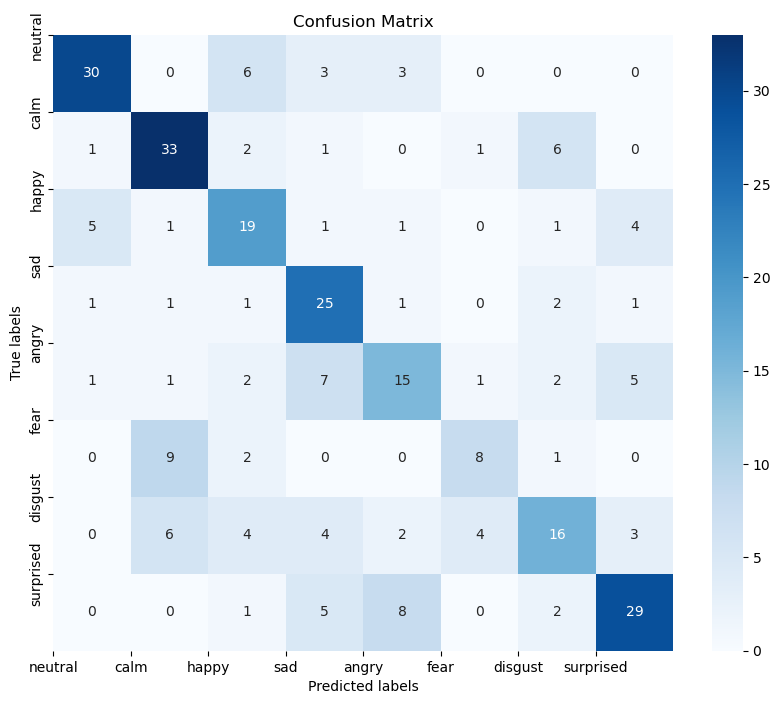

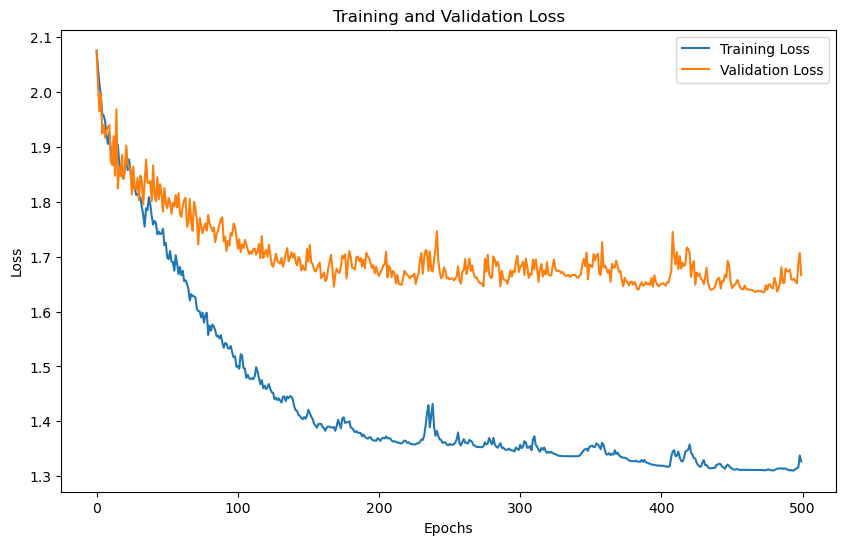

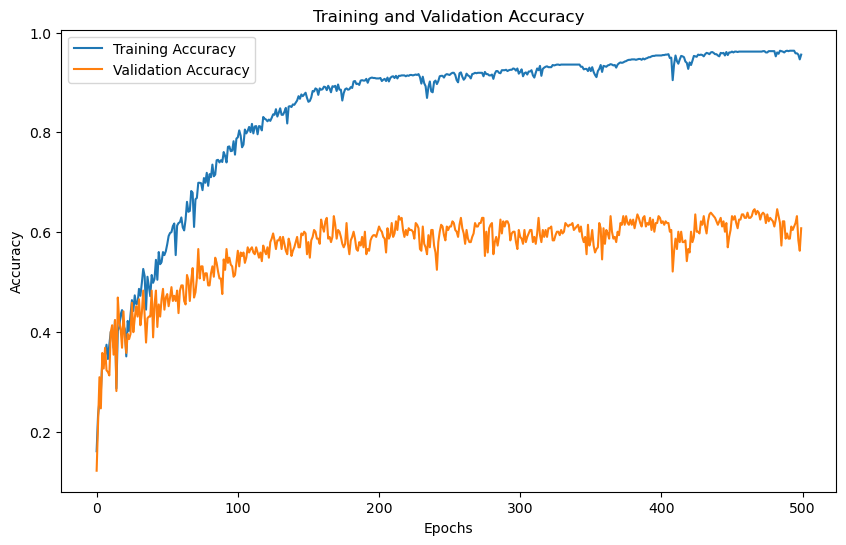

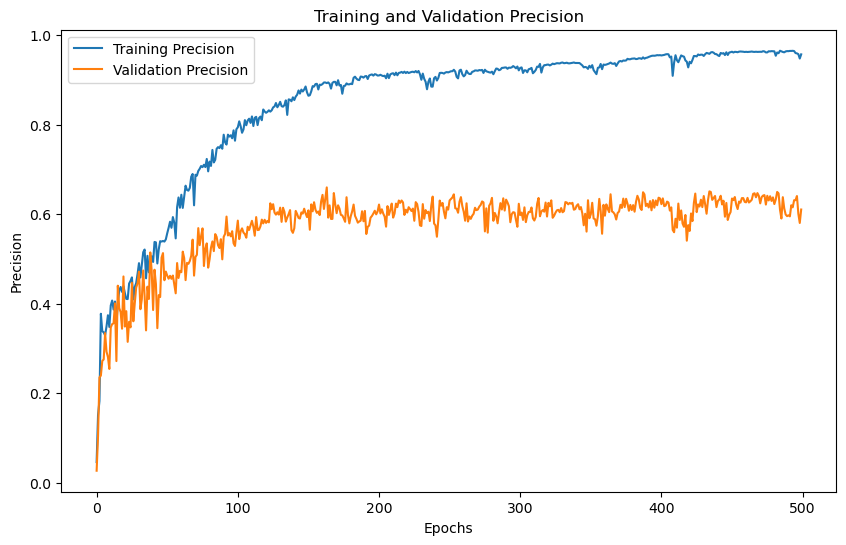

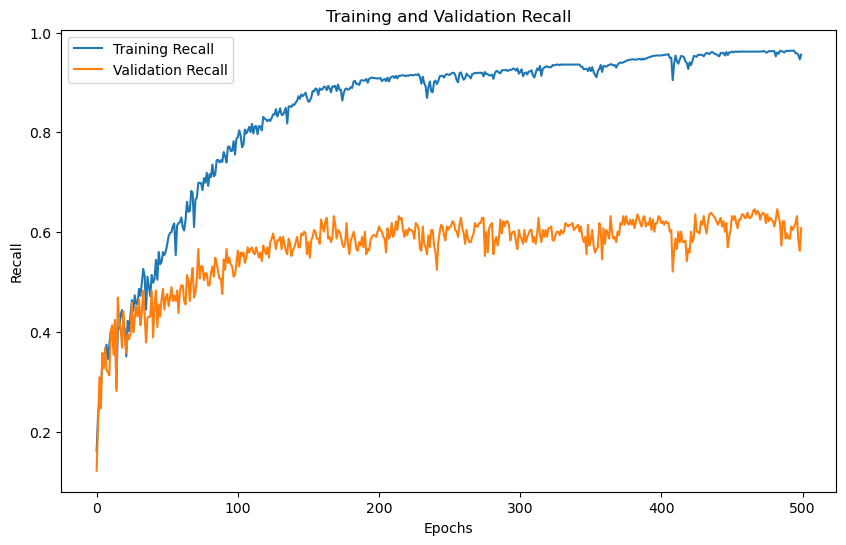

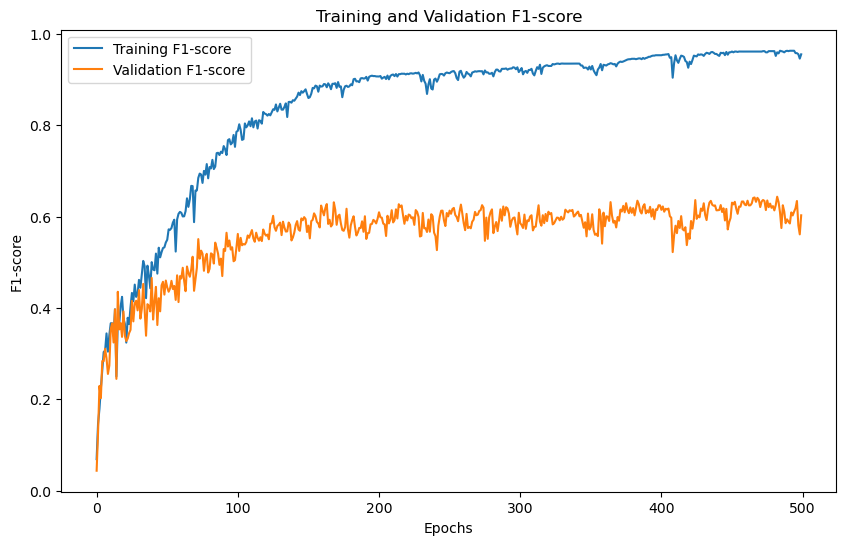

'Model Training and Evaluation Successfully completed'

In [40]:
train_model()

# CREMA

# N_MFCC 16

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  16
No. of classes 6
Input size : 16
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (7442, 16)
Y Shape : (7442, 6)
Training with N_MFCC: 16
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7008, Training Accuracy: 0.3387, Training Precision:0.2191,Training Recall:0.3387,Training F1-Score:0.2452
Validation Loss: 1.6616, Validation Accuracy: 0.3539, Validation Precision:0.2340,Validation Recall:0.3539,Validation F1-Score:0.2617
Epoch [2/500],
Training Loss: 1.6853, Training Accuracy: 0.3511, Training Precision:0.2391,Training Recall:0.3511,Training F1-Score:0.2836
Validation Loss: 1.6660, Validation Accuracy: 0.3593, Validation Precision:0.2463,Validation Recall:0.3593,Validation F1-Score:0.2907
Epoch [3/500],
Training Loss: 1.6636, Training Accuracy: 0.3763, Training Precision:0.4276,Training Recall:0.3763,Training F1-Score:0.3018
Validation Loss: 1.6393, Validation Accuracy: 0.3801, Validation Precisio

Epoch [31/500],
Training Loss: 1.6032, Training Accuracy: 0.4250, Training Precision:0.4073,Training Recall:0.4250,Training F1-Score:0.4020
Validation Loss: 1.6309, Validation Accuracy: 0.3922, Validation Precision:0.3963,Validation Recall:0.3922,Validation F1-Score:0.3639
Epoch [32/500],
Training Loss: 1.5950, Training Accuracy: 0.4566, Training Precision:0.4442,Training Recall:0.4566,Training F1-Score:0.4449
Validation Loss: 1.5863, Validation Accuracy: 0.4520, Validation Precision:0.4446,Validation Recall:0.4520,Validation F1-Score:0.4412
Epoch [33/500],
Training Loss: 1.5897, Training Accuracy: 0.4458, Training Precision:0.4289,Training Recall:0.4458,Training F1-Score:0.4280
Validation Loss: 1.5932, Validation Accuracy: 0.4453, Validation Precision:0.4407,Validation Recall:0.4453,Validation F1-Score:0.4294
Epoch [34/500],
Training Loss: 1.6208, Training Accuracy: 0.4391, Training Precision:0.4374,Training Recall:0.4391,Training F1-Score:0.4067
Validation Loss: 1.5790, Validation Ac

Epoch [61/500],
Training Loss: 1.5878, Training Accuracy: 0.4769, Training Precision:0.4818,Training Recall:0.4769,Training F1-Score:0.4704
Validation Loss: 1.5797, Validation Accuracy: 0.4486, Validation Precision:0.4480,Validation Recall:0.4486,Validation F1-Score:0.4433
Epoch [62/500],
Training Loss: 1.5687, Training Accuracy: 0.4845, Training Precision:0.4864,Training Recall:0.4845,Training F1-Score:0.4756
Validation Loss: 1.5849, Validation Accuracy: 0.4446, Validation Precision:0.4525,Validation Recall:0.4446,Validation F1-Score:0.4339
Epoch [63/500],
Training Loss: 1.5798, Training Accuracy: 0.4782, Training Precision:0.4733,Training Recall:0.4782,Training F1-Score:0.4683
Validation Loss: 1.5686, Validation Accuracy: 0.4694, Validation Precision:0.4599,Validation Recall:0.4694,Validation F1-Score:0.4600
Epoch [64/500],
Training Loss: 1.5620, Training Accuracy: 0.4942, Training Precision:0.4887,Training Recall:0.4942,Training F1-Score:0.4853
Validation Loss: 1.5811, Validation Ac

Epoch [91/500],
Training Loss: 1.5003, Training Accuracy: 0.5545, Training Precision:0.5529,Training Recall:0.5545,Training F1-Score:0.5492
Validation Loss: 1.5699, Validation Accuracy: 0.4621, Validation Precision:0.4525,Validation Recall:0.4621,Validation F1-Score:0.4530
Epoch [92/500],
Training Loss: 1.5022, Training Accuracy: 0.5599, Training Precision:0.5610,Training Recall:0.5599,Training F1-Score:0.5561
Validation Loss: 1.5709, Validation Accuracy: 0.4594, Validation Precision:0.4520,Validation Recall:0.4594,Validation F1-Score:0.4511
Epoch [93/500],
Training Loss: 1.4926, Training Accuracy: 0.5648, Training Precision:0.5731,Training Recall:0.5648,Training F1-Score:0.5587
Validation Loss: 1.5615, Validation Accuracy: 0.4668, Validation Precision:0.4602,Validation Recall:0.4668,Validation F1-Score:0.4551
Epoch [94/500],
Training Loss: 1.4891, Training Accuracy: 0.5698, Training Precision:0.5806,Training Recall:0.5698,Training F1-Score:0.5624
Validation Loss: 1.5646, Validation Ac

Epoch [121/500],
Training Loss: 1.4391, Training Accuracy: 0.6262, Training Precision:0.6325,Training Recall:0.6262,Training F1-Score:0.6238
Validation Loss: 1.5890, Validation Accuracy: 0.4446, Validation Precision:0.4426,Validation Recall:0.4446,Validation F1-Score:0.4381
Epoch [122/500],
Training Loss: 1.4244, Training Accuracy: 0.6187, Training Precision:0.6387,Training Recall:0.6187,Training F1-Score:0.6167
Validation Loss: 1.5698, Validation Accuracy: 0.4600, Validation Precision:0.4523,Validation Recall:0.4600,Validation F1-Score:0.4482
Epoch [123/500],
Training Loss: 1.4267, Training Accuracy: 0.6449, Training Precision:0.6473,Training Recall:0.6449,Training F1-Score:0.6430
Validation Loss: 1.5879, Validation Accuracy: 0.4439, Validation Precision:0.4412,Validation Recall:0.4439,Validation F1-Score:0.4383
Epoch [124/500],
Training Loss: 1.4100, Training Accuracy: 0.6395, Training Precision:0.6501,Training Recall:0.6395,Training F1-Score:0.6347
Validation Loss: 1.5705, Validatio

...

Epoch [361/500],
Training Loss: 1.1728, Training Accuracy: 0.8791, Training Precision:0.8804,Training Recall:0.8791,Training F1-Score:0.8786
Validation Loss: 1.6211, Validation Accuracy: 0.4063, Validation Precision:0.4015,Validation Recall:0.4063,Validation F1-Score:0.3981
Epoch [362/500],
Training Loss: 1.1658, Training Accuracy: 0.8811, Training Precision:0.8814,Training Recall:0.8811,Training F1-Score:0.8806
Validation Loss: 1.6245, Validation Accuracy: 0.4103, Validation Precision:0.4064,Validation Recall:0.4103,Validation F1-Score:0.4036
Epoch [363/500],
Training Loss: 1.1711, Training Accuracy: 0.8829, Training Precision:0.8832,Training Recall:0.8829,Training F1-Score:0.8825
Validation Loss: 1.6166, Validation Accuracy: 0.4144, Validation Precision:0.4086,Validation Recall:0.4144,Validation F1-Score:0.4082
Epoch [364/500],
Training Loss: 1.1615, Training Accuracy: 0.8858, Training Precision:0.8868,Training Recall:0.8858,Training F1-Score:0.8854
Validation Loss: 1.6158, Validatio

Epoch [391/500],
Training Loss: 1.1513, Training Accuracy: 0.8928, Training Precision:0.8932,Training Recall:0.8928,Training F1-Score:0.8925
Validation Loss: 1.6300, Validation Accuracy: 0.4090, Validation Precision:0.4081,Validation Recall:0.4090,Validation F1-Score:0.4061
Epoch [392/500],
Training Loss: 1.1505, Training Accuracy: 0.8932, Training Precision:0.8933,Training Recall:0.8932,Training F1-Score:0.8928
Validation Loss: 1.6248, Validation Accuracy: 0.4070, Validation Precision:0.4026,Validation Recall:0.4070,Validation F1-Score:0.4025
Epoch [393/500],
Training Loss: 1.1982, Training Accuracy: 0.8757, Training Precision:0.8757,Training Recall:0.8757,Training F1-Score:0.8754
Validation Loss: 1.6378, Validation Accuracy: 0.3922, Validation Precision:0.3891,Validation Recall:0.3922,Validation F1-Score:0.3837
Epoch [394/500],
Training Loss: 1.1941, Training Accuracy: 0.8841, Training Precision:0.8841,Training Recall:0.8841,Training F1-Score:0.8837
Validation Loss: 1.6327, Validatio

Epoch [421/500],
Training Loss: 1.1761, Training Accuracy: 0.8864, Training Precision:0.8864,Training Recall:0.8864,Training F1-Score:0.8862
Validation Loss: 1.6388, Validation Accuracy: 0.3929, Validation Precision:0.3939,Validation Recall:0.3929,Validation F1-Score:0.3906
Epoch [422/500],
Training Loss: 1.1526, Training Accuracy: 0.8876, Training Precision:0.8877,Training Recall:0.8876,Training F1-Score:0.8873
Validation Loss: 1.6286, Validation Accuracy: 0.4036, Validation Precision:0.3989,Validation Recall:0.4036,Validation F1-Score:0.3988
Epoch [423/500],
Training Loss: 1.2077, Training Accuracy: 0.8854, Training Precision:0.8862,Training Recall:0.8854,Training F1-Score:0.8851
Validation Loss: 1.6249, Validation Accuracy: 0.4083, Validation Precision:0.4004,Validation Recall:0.4083,Validation F1-Score:0.4012
Epoch [424/500],
Training Loss: 1.2238, Training Accuracy: 0.8799, Training Precision:0.8811,Training Recall:0.8799,Training F1-Score:0.8794
Validation Loss: 1.6227, Validatio

Epoch [451/500],
Training Loss: 1.1534, Training Accuracy: 0.8994, Training Precision:0.8998,Training Recall:0.8994,Training F1-Score:0.8991
Validation Loss: 1.6300, Validation Accuracy: 0.4056, Validation Precision:0.3949,Validation Recall:0.4056,Validation F1-Score:0.3978
Epoch [452/500],
Training Loss: 1.1438, Training Accuracy: 0.9012, Training Precision:0.9016,Training Recall:0.9012,Training F1-Score:0.9009
Validation Loss: 1.6380, Validation Accuracy: 0.3902, Validation Precision:0.3815,Validation Recall:0.3902,Validation F1-Score:0.3828
Epoch [453/500],
Training Loss: 1.1421, Training Accuracy: 0.9016, Training Precision:0.9016,Training Recall:0.9016,Training F1-Score:0.9012
Validation Loss: 1.6356, Validation Accuracy: 0.3969, Validation Precision:0.3909,Validation Recall:0.3969,Validation F1-Score:0.3922
Epoch [454/500],
Training Loss: 1.1413, Training Accuracy: 0.9021, Training Precision:0.9024,Training Recall:0.9021,Training F1-Score:0.9018
Validation Loss: 1.6330, Validatio

Epoch [481/500],
Training Loss: 1.2312, Training Accuracy: 0.8733, Training Precision:0.8753,Training Recall:0.8733,Training F1-Score:0.8731
Validation Loss: 1.6316, Validation Accuracy: 0.4036, Validation Precision:0.3950,Validation Recall:0.4036,Validation F1-Score:0.3973
Epoch [482/500],
Training Loss: 1.1980, Training Accuracy: 0.8812, Training Precision:0.8829,Training Recall:0.8812,Training F1-Score:0.8810
Validation Loss: 1.6289, Validation Accuracy: 0.3983, Validation Precision:0.3893,Validation Recall:0.3983,Validation F1-Score:0.3896
Epoch [483/500],
Training Loss: 1.1580, Training Accuracy: 0.8952, Training Precision:0.8959,Training Recall:0.8952,Training F1-Score:0.8949
Validation Loss: 1.6267, Validation Accuracy: 0.4050, Validation Precision:0.3966,Validation Recall:0.4050,Validation F1-Score:0.3989
Epoch [484/500],
Training Loss: 1.1504, Training Accuracy: 0.8950, Training Precision:0.8961,Training Recall:0.8950,Training F1-Score:0.8948
Validation Loss: 1.6336, Validatio

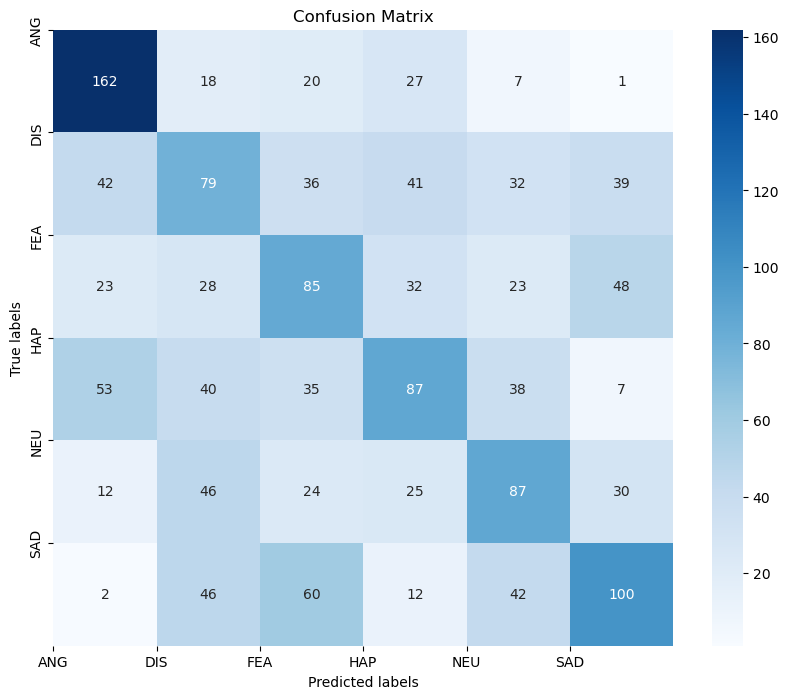

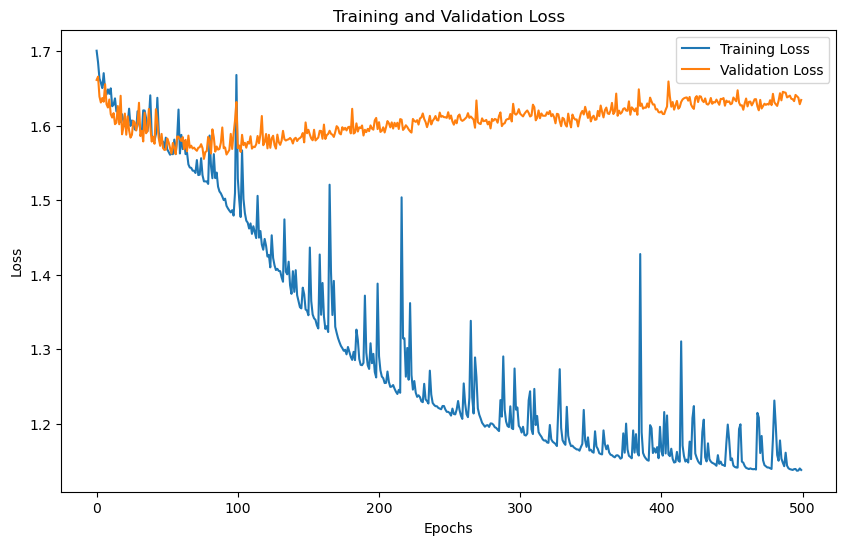

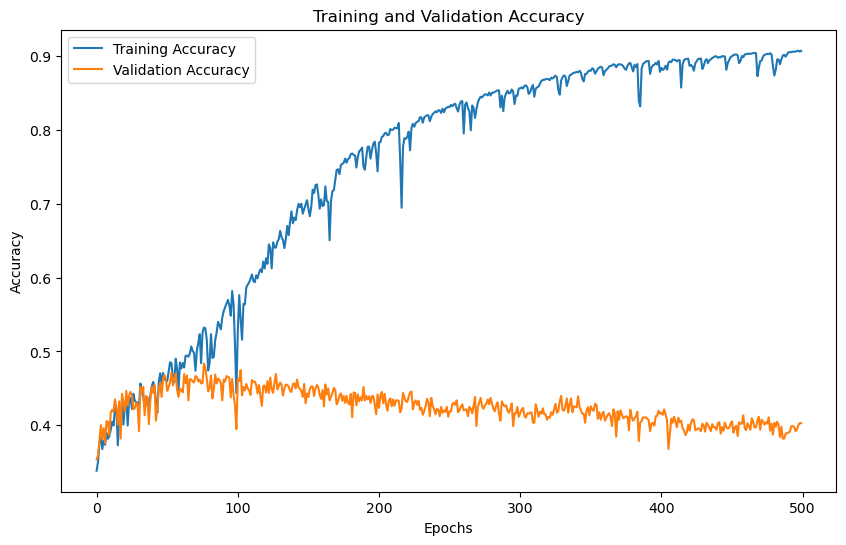

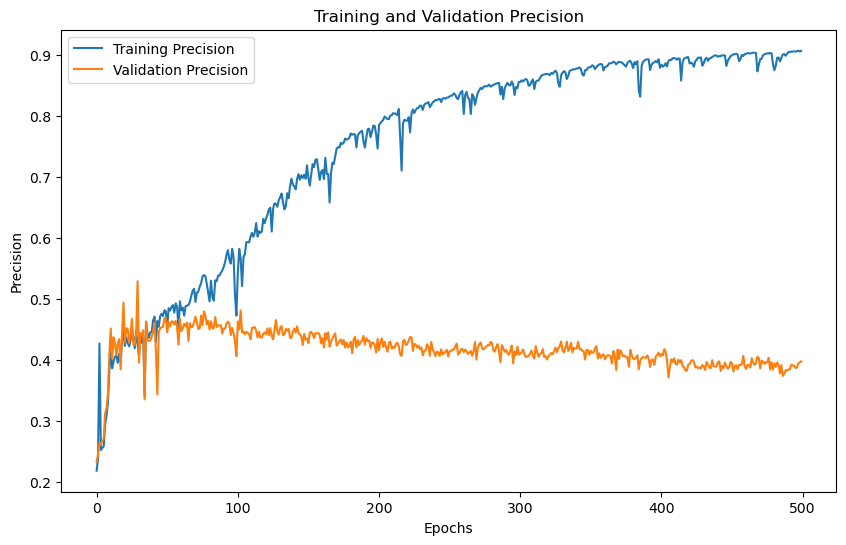

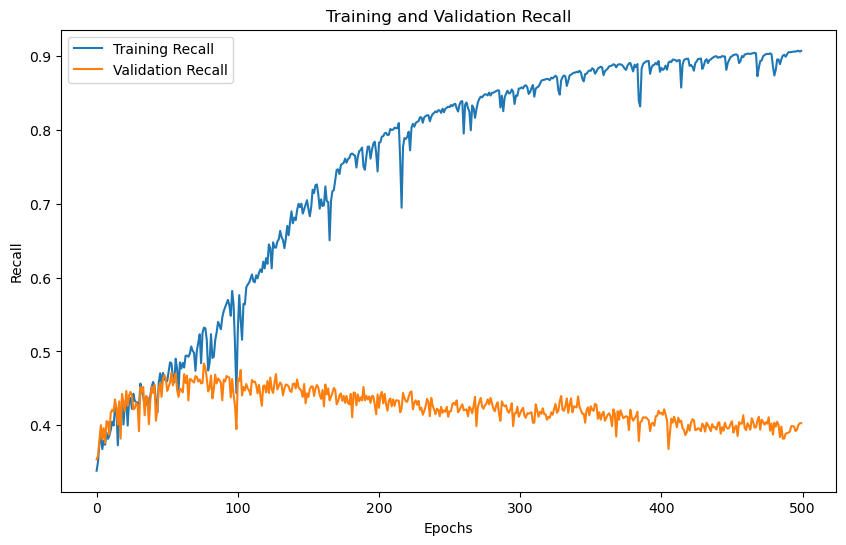

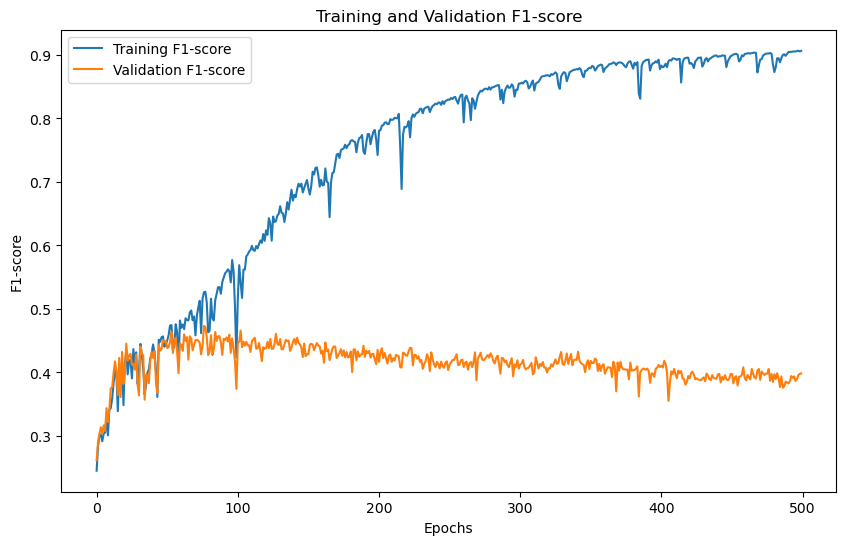

'Model Training and Evaluation Successfully completed'

In [41]:
train_model()

# N_MFCC 24

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  24
No. of classes 6
Input size : 24
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (7442, 24)
Y Shape : (7442, 6)
Training with N_MFCC: 24
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7133, Training Accuracy: 0.3764, Training Precision:0.2835,Training Recall:0.3764,Training F1-Score:0.3027
Validation Loss: 1.6588, Validation Accuracy: 0.3842, Validation Precision:0.3822,Validation Recall:0.3842,Validation F1-Score:0.3120
Epoch [2/500],
Training Loss: 1.6689, Training Accuracy: 0.3568, Training Precision:0.2710,Training Recall:0.3568,Training F1-Score:0.2935
Validation Loss: 1.6579, Validation Accuracy: 0.3633, Validation Precision:0.2790,Validation Recall:0.3633,Validation F1-Score:0.2988
Epoch [3/500],
Training Loss: 1.6640, Training Accuracy: 0.3281, Training Precision:0.2945,Training Recall:0.3281,Training F1-Score:0.2773
Validation Loss: 1.6700, Validation Accuracy: 0.3405, Validation Precisio

Epoch [31/500],
Training Loss: 1.6269, Training Accuracy: 0.4193, Training Precision:0.4280,Training Recall:0.4193,Training F1-Score:0.4020
Validation Loss: 1.6013, Validation Accuracy: 0.4352, Validation Precision:0.4394,Validation Recall:0.4352,Validation F1-Score:0.4221
Epoch [32/500],
Training Loss: 1.6170, Training Accuracy: 0.4304, Training Precision:0.4147,Training Recall:0.4304,Training F1-Score:0.4081
Validation Loss: 1.5916, Validation Accuracy: 0.4379, Validation Precision:0.4290,Validation Recall:0.4379,Validation F1-Score:0.4169
Epoch [33/500],
Training Loss: 1.6248, Training Accuracy: 0.4275, Training Precision:0.4179,Training Recall:0.4275,Training F1-Score:0.3974
Validation Loss: 1.5991, Validation Accuracy: 0.4372, Validation Precision:0.4484,Validation Recall:0.4372,Validation F1-Score:0.4098
Epoch [34/500],
Training Loss: 1.6072, Training Accuracy: 0.4178, Training Precision:0.4029,Training Recall:0.4178,Training F1-Score:0.3831
Validation Loss: 1.6105, Validation Ac

Epoch [61/500],
Training Loss: 1.5998, Training Accuracy: 0.4436, Training Precision:0.4432,Training Recall:0.4436,Training F1-Score:0.4141
Validation Loss: 1.5929, Validation Accuracy: 0.4379, Validation Precision:0.4411,Validation Recall:0.4379,Validation F1-Score:0.4004
Epoch [62/500],
Training Loss: 1.5830, Training Accuracy: 0.4688, Training Precision:0.4724,Training Recall:0.4688,Training F1-Score:0.4528
Validation Loss: 1.5707, Validation Accuracy: 0.4600, Validation Precision:0.4558,Validation Recall:0.4600,Validation F1-Score:0.4450
Epoch [63/500],
Training Loss: 1.5756, Training Accuracy: 0.4675, Training Precision:0.4882,Training Recall:0.4675,Training F1-Score:0.4613
Validation Loss: 1.5762, Validation Accuracy: 0.4627, Validation Precision:0.4732,Validation Recall:0.4627,Validation F1-Score:0.4551
Epoch [64/500],
Training Loss: 1.5688, Training Accuracy: 0.4482, Training Precision:0.4766,Training Recall:0.4482,Training F1-Score:0.4213
Validation Loss: 1.5821, Validation Ac

Epoch [91/500],
Training Loss: 1.5618, Training Accuracy: 0.4840, Training Precision:0.4935,Training Recall:0.4840,Training F1-Score:0.4807
Validation Loss: 1.5762, Validation Accuracy: 0.4567, Validation Precision:0.4657,Validation Recall:0.4567,Validation F1-Score:0.4552
Epoch [92/500],
Training Loss: 1.5542, Training Accuracy: 0.5031, Training Precision:0.5081,Training Recall:0.5031,Training F1-Score:0.4948
Validation Loss: 1.5753, Validation Accuracy: 0.4600, Validation Precision:0.4642,Validation Recall:0.4600,Validation F1-Score:0.4528
Epoch [93/500],
Training Loss: 1.5472, Training Accuracy: 0.4900, Training Precision:0.5079,Training Recall:0.4900,Training F1-Score:0.4796
Validation Loss: 1.5668, Validation Accuracy: 0.4621, Validation Precision:0.4607,Validation Recall:0.4621,Validation F1-Score:0.4486
Epoch [94/500],
Training Loss: 1.5442, Training Accuracy: 0.5053, Training Precision:0.5081,Training Recall:0.5053,Training F1-Score:0.4964
Validation Loss: 1.5717, Validation Ac

Epoch [121/500],
Training Loss: 1.4866, Training Accuracy: 0.5548, Training Precision:0.5560,Training Recall:0.5548,Training F1-Score:0.5493
Validation Loss: 1.5903, Validation Accuracy: 0.4406, Validation Precision:0.4376,Validation Recall:0.4406,Validation F1-Score:0.4268
Epoch [122/500],
Training Loss: 1.4794, Training Accuracy: 0.5733, Training Precision:0.5814,Training Recall:0.5733,Training F1-Score:0.5685
Validation Loss: 1.5707, Validation Accuracy: 0.4634, Validation Precision:0.4592,Validation Recall:0.4634,Validation F1-Score:0.4542
Epoch [123/500],
Training Loss: 1.4753, Training Accuracy: 0.5674, Training Precision:0.5905,Training Recall:0.5674,Training F1-Score:0.5563
Validation Loss: 1.5826, Validation Accuracy: 0.4466, Validation Precision:0.4427,Validation Recall:0.4466,Validation F1-Score:0.4269
Epoch [124/500],
Training Loss: 1.4724, Training Accuracy: 0.5903, Training Precision:0.6050,Training Recall:0.5903,Training F1-Score:0.5876
Validation Loss: 1.5679, Validatio

...

Epoch [361/500],
Training Loss: 1.1650, Training Accuracy: 0.8824, Training Precision:0.8835,Training Recall:0.8824,Training F1-Score:0.8819
Validation Loss: 1.6188, Validation Accuracy: 0.4184, Validation Precision:0.4109,Validation Recall:0.4184,Validation F1-Score:0.4128
Epoch [362/500],
Training Loss: 1.1607, Training Accuracy: 0.8826, Training Precision:0.8829,Training Recall:0.8826,Training F1-Score:0.8821
Validation Loss: 1.6085, Validation Accuracy: 0.4278, Validation Precision:0.4231,Validation Recall:0.4278,Validation F1-Score:0.4250
Epoch [363/500],
Training Loss: 1.1604, Training Accuracy: 0.8834, Training Precision:0.8840,Training Recall:0.8834,Training F1-Score:0.8830
Validation Loss: 1.6159, Validation Accuracy: 0.4171, Validation Precision:0.4139,Validation Recall:0.4171,Validation F1-Score:0.4146
Epoch [364/500],
Training Loss: 1.1603, Training Accuracy: 0.8841, Training Precision:0.8844,Training Recall:0.8841,Training F1-Score:0.8836
Validation Loss: 1.6138, Validatio

Epoch [391/500],
Training Loss: 1.1532, Training Accuracy: 0.8891, Training Precision:0.8895,Training Recall:0.8891,Training F1-Score:0.8888
Validation Loss: 1.6170, Validation Accuracy: 0.4157, Validation Precision:0.4117,Validation Recall:0.4157,Validation F1-Score:0.4092
Epoch [392/500],
Training Loss: 1.1531, Training Accuracy: 0.8896, Training Precision:0.8903,Training Recall:0.8896,Training F1-Score:0.8893
Validation Loss: 1.6085, Validation Accuracy: 0.4312, Validation Precision:0.4242,Validation Recall:0.4312,Validation F1-Score:0.4252
Epoch [393/500],
Training Loss: 1.1532, Training Accuracy: 0.8896, Training Precision:0.8905,Training Recall:0.8896,Training F1-Score:0.8893
Validation Loss: 1.6085, Validation Accuracy: 0.4244, Validation Precision:0.4198,Validation Recall:0.4244,Validation F1-Score:0.4206
Epoch [394/500],
Training Loss: 1.1526, Training Accuracy: 0.8903, Training Precision:0.8907,Training Recall:0.8903,Training F1-Score:0.8899
Validation Loss: 1.6097, Validatio

Epoch [421/500],
Training Loss: 1.1518, Training Accuracy: 0.8923, Training Precision:0.8925,Training Recall:0.8923,Training F1-Score:0.8920
Validation Loss: 1.6244, Validation Accuracy: 0.4090, Validation Precision:0.4062,Validation Recall:0.4090,Validation F1-Score:0.4055
Epoch [422/500],
Training Loss: 1.1513, Training Accuracy: 0.8945, Training Precision:0.8954,Training Recall:0.8945,Training F1-Score:0.8942
Validation Loss: 1.6187, Validation Accuracy: 0.4184, Validation Precision:0.4141,Validation Recall:0.4184,Validation F1-Score:0.4153
Epoch [423/500],
Training Loss: 1.1512, Training Accuracy: 0.8948, Training Precision:0.8952,Training Recall:0.8948,Training F1-Score:0.8945
Validation Loss: 1.6169, Validation Accuracy: 0.4224, Validation Precision:0.4127,Validation Recall:0.4224,Validation F1-Score:0.4148
Epoch [424/500],
Training Loss: 1.1488, Training Accuracy: 0.8962, Training Precision:0.8970,Training Recall:0.8962,Training F1-Score:0.8958
Validation Loss: 1.6090, Validatio

Epoch [451/500],
Training Loss: 1.1410, Training Accuracy: 0.9017, Training Precision:0.9019,Training Recall:0.9017,Training F1-Score:0.9015
Validation Loss: 1.6254, Validation Accuracy: 0.4036, Validation Precision:0.3960,Validation Recall:0.4036,Validation F1-Score:0.3977
Epoch [452/500],
Training Loss: 1.1434, Training Accuracy: 0.8982, Training Precision:0.8982,Training Recall:0.8982,Training F1-Score:0.8979
Validation Loss: 1.6264, Validation Accuracy: 0.4077, Validation Precision:0.4030,Validation Recall:0.4077,Validation F1-Score:0.4026
Epoch [453/500],
Training Loss: 1.1925, Training Accuracy: 0.8888, Training Precision:0.8894,Training Recall:0.8888,Training F1-Score:0.8885
Validation Loss: 1.6152, Validation Accuracy: 0.4231, Validation Precision:0.4174,Validation Recall:0.4231,Validation F1-Score:0.4183
Epoch [454/500],
Training Loss: 1.1519, Training Accuracy: 0.8985, Training Precision:0.8994,Training Recall:0.8985,Training F1-Score:0.8983
Validation Loss: 1.6134, Validatio

Epoch [481/500],
Training Loss: 1.1448, Training Accuracy: 0.9049, Training Precision:0.9054,Training Recall:0.9049,Training F1-Score:0.9047
Validation Loss: 1.6175, Validation Accuracy: 0.4157, Validation Precision:0.4092,Validation Recall:0.4157,Validation F1-Score:0.4112
Epoch [482/500],
Training Loss: 1.1388, Training Accuracy: 0.9058, Training Precision:0.9060,Training Recall:0.9058,Training F1-Score:0.9055
Validation Loss: 1.6128, Validation Accuracy: 0.4177, Validation Precision:0.4132,Validation Recall:0.4177,Validation F1-Score:0.4150
Epoch [483/500],
Training Loss: 1.1368, Training Accuracy: 0.9078, Training Precision:0.9079,Training Recall:0.9078,Training F1-Score:0.9075
Validation Loss: 1.6219, Validation Accuracy: 0.4110, Validation Precision:0.4068,Validation Recall:0.4110,Validation F1-Score:0.4078
Epoch [484/500],
Training Loss: 1.1363, Training Accuracy: 0.9081, Training Precision:0.9082,Training Recall:0.9081,Training F1-Score:0.9079
Validation Loss: 1.6260, Validatio

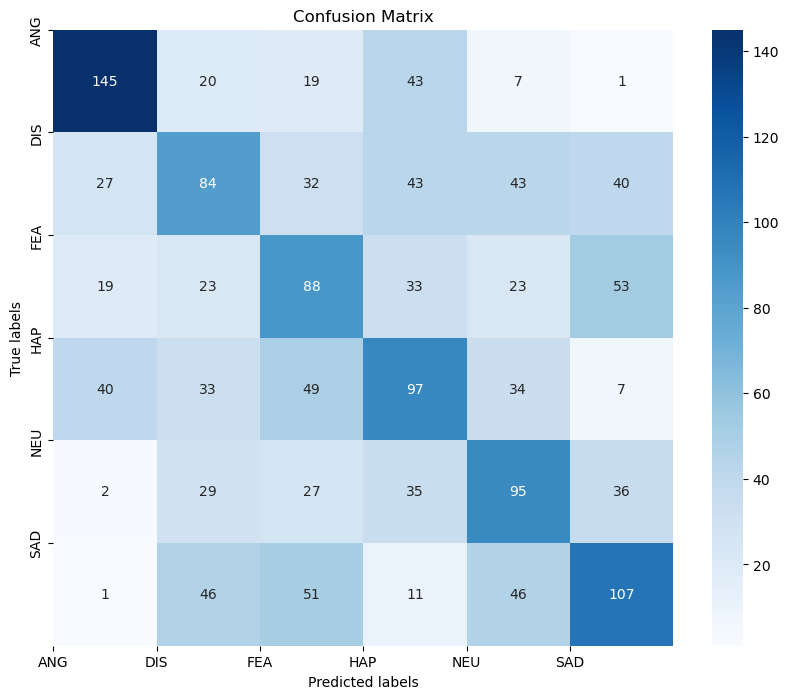

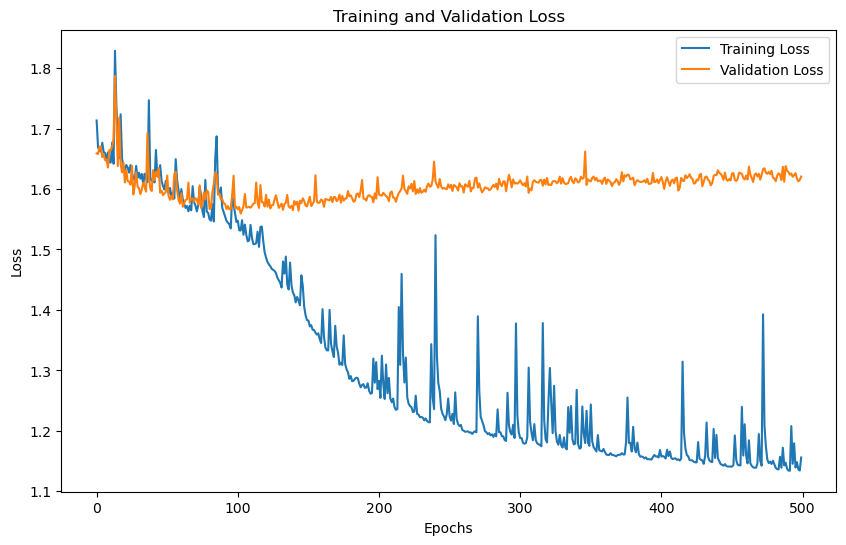

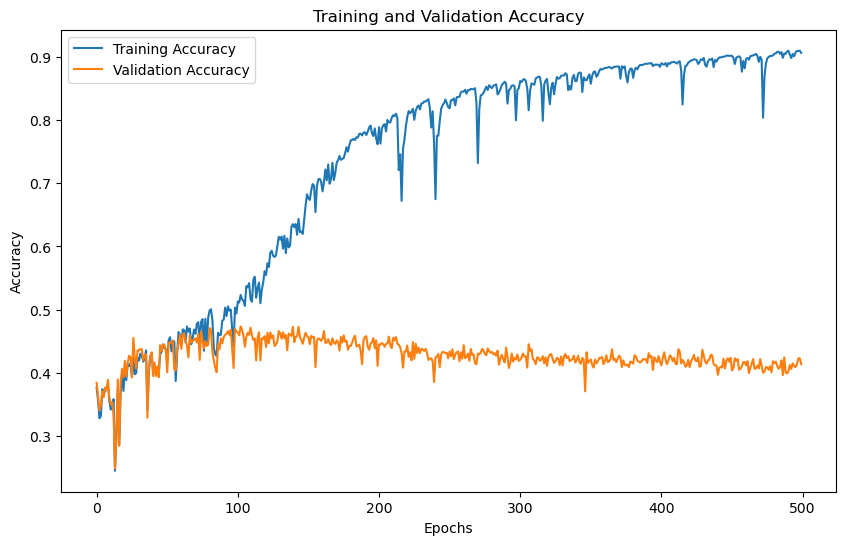

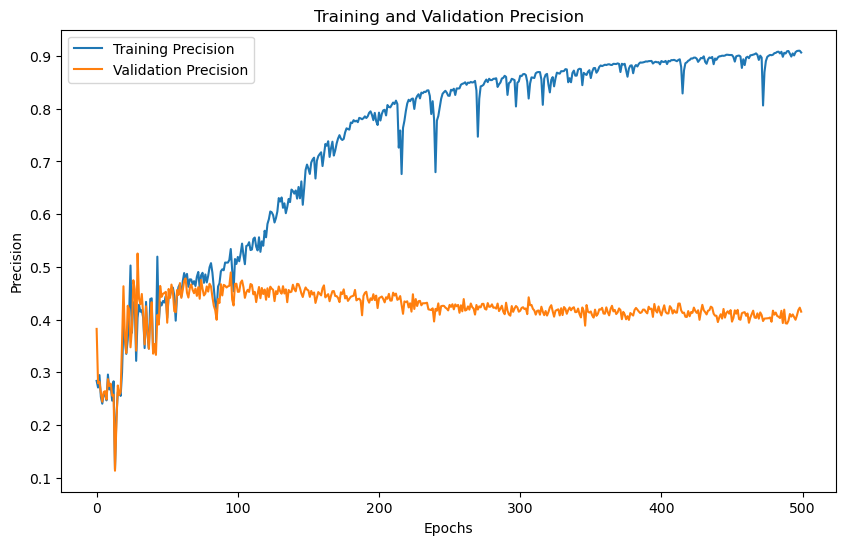

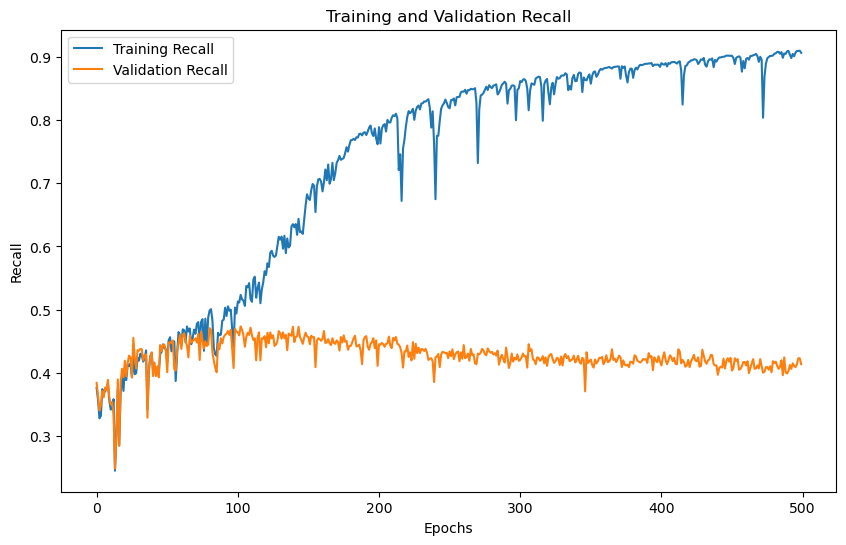

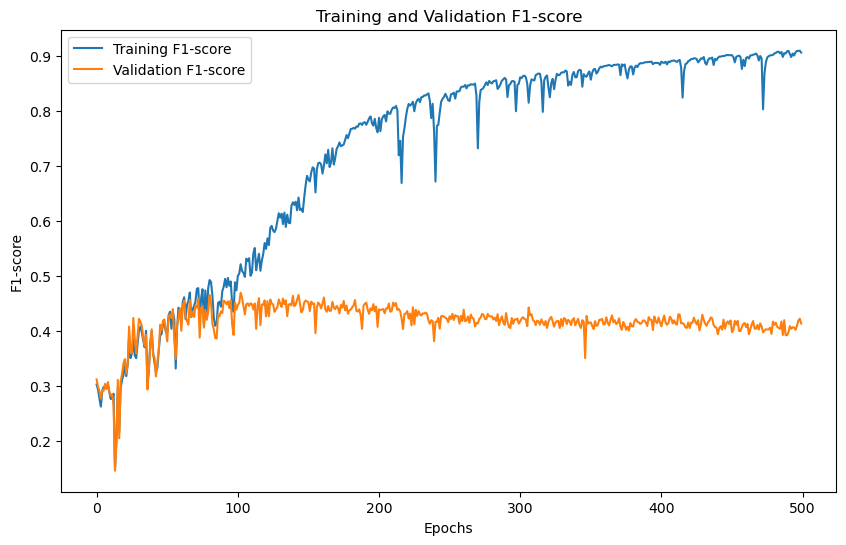

'Model Training and Evaluation Successfully completed'

In [42]:
train_model()

# N_MFCC 32

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  32
No. of classes 6
Input size : 32
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (7442, 32)
Y Shape : (7442, 6)
Training with N_MFCC: 32
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7080, Training Accuracy: 0.2780, Training Precision:0.2179,Training Recall:0.2780,Training F1-Score:0.2030
Validation Loss: 1.7309, Validation Accuracy: 0.2901, Validation Precision:0.2216,Validation Recall:0.2901,Validation F1-Score:0.2123
Epoch [2/500],
Training Loss: 1.7305, Training Accuracy: 0.3316, Training Precision:0.2216,Training Recall:0.3316,Training F1-Score:0.2436
Validation Loss: 1.6727, Validation Accuracy: 0.3486, Validation Precision:0.2374,Validation Recall:0.3486,Validation F1-Score:0.2607
Epoch [3/500],
Training Loss: 1.6788, Training Accuracy: 0.3664, Training Precision:0.3248,Training Recall:0.3664,Training F1-Score:0.2959
Validation Loss: 1.6447, Validation Accuracy: 0.3868, Validation Precisio

Epoch [31/500],
Training Loss: 1.6579, Training Accuracy: 0.3669, Training Precision:0.3514,Training Recall:0.3669,Training F1-Score:0.3353
Validation Loss: 1.6431, Validation Accuracy: 0.3882, Validation Precision:0.3560,Validation Recall:0.3882,Validation F1-Score:0.3508
Epoch [32/500],
Training Loss: 1.6264, Training Accuracy: 0.3790, Training Precision:0.3652,Training Recall:0.3790,Training F1-Score:0.3229
Validation Loss: 1.6360, Validation Accuracy: 0.3889, Validation Precision:0.3575,Validation Recall:0.3889,Validation F1-Score:0.3250
Epoch [33/500],
Training Loss: 1.6485, Training Accuracy: 0.3620, Training Precision:0.3407,Training Recall:0.3620,Training F1-Score:0.3220
Validation Loss: 1.6516, Validation Accuracy: 0.3747, Validation Precision:0.3509,Validation Recall:0.3747,Validation F1-Score:0.3302
Epoch [34/500],
Training Loss: 1.6838, Training Accuracy: 0.3486, Training Precision:0.2809,Training Recall:0.3486,Training F1-Score:0.2961
Validation Loss: 1.6623, Validation Ac

Epoch [61/500],
Training Loss: 1.6004, Training Accuracy: 0.4638, Training Precision:0.4712,Training Recall:0.4638,Training F1-Score:0.4536
Validation Loss: 1.5799, Validation Accuracy: 0.4574, Validation Precision:0.4626,Validation Recall:0.4574,Validation F1-Score:0.4454
Epoch [62/500],
Training Loss: 1.5720, Training Accuracy: 0.4482, Training Precision:0.4443,Training Recall:0.4482,Training F1-Score:0.4190
Validation Loss: 1.6052, Validation Accuracy: 0.4251, Validation Precision:0.4169,Validation Recall:0.4251,Validation F1-Score:0.3883
Epoch [63/500],
Training Loss: 1.5688, Training Accuracy: 0.4645, Training Precision:0.4783,Training Recall:0.4645,Training F1-Score:0.4651
Validation Loss: 1.5832, Validation Accuracy: 0.4486, Validation Precision:0.4555,Validation Recall:0.4486,Validation F1-Score:0.4471
Epoch [64/500],
Training Loss: 1.5634, Training Accuracy: 0.4643, Training Precision:0.4663,Training Recall:0.4643,Training F1-Score:0.4513
Validation Loss: 1.6085, Validation Ac

Epoch [91/500],
Training Loss: 1.5241, Training Accuracy: 0.5024, Training Precision:0.5383,Training Recall:0.5024,Training F1-Score:0.4923
Validation Loss: 1.5804, Validation Accuracy: 0.4527, Validation Precision:0.4614,Validation Recall:0.4527,Validation F1-Score:0.4296
Epoch [92/500],
Training Loss: 1.5305, Training Accuracy: 0.5149, Training Precision:0.5409,Training Recall:0.5149,Training F1-Score:0.5069
Validation Loss: 1.5726, Validation Accuracy: 0.4607, Validation Precision:0.4613,Validation Recall:0.4607,Validation F1-Score:0.4480
Epoch [93/500],
Training Loss: 1.5127, Training Accuracy: 0.5375, Training Precision:0.5396,Training Recall:0.5375,Training F1-Score:0.5316
Validation Loss: 1.5559, Validation Accuracy: 0.4721, Validation Precision:0.4616,Validation Recall:0.4721,Validation F1-Score:0.4637
Epoch [94/500],
Training Loss: 1.5115, Training Accuracy: 0.5090, Training Precision:0.5182,Training Recall:0.5090,Training F1-Score:0.5028
Validation Loss: 1.5920, Validation Ac

Epoch [121/500],
Training Loss: 1.5291, Training Accuracy: 0.5337, Training Precision:0.5364,Training Recall:0.5337,Training F1-Score:0.5284
Validation Loss: 1.5764, Validation Accuracy: 0.4540, Validation Precision:0.4500,Validation Recall:0.4540,Validation F1-Score:0.4467
Epoch [122/500],
Training Loss: 1.4970, Training Accuracy: 0.5244, Training Precision:0.5477,Training Recall:0.5244,Training F1-Score:0.5195
Validation Loss: 1.5915, Validation Accuracy: 0.4412, Validation Precision:0.4435,Validation Recall:0.4412,Validation F1-Score:0.4244
Epoch [123/500],
Training Loss: 1.6299, Training Accuracy: 0.4279, Training Precision:0.4773,Training Recall:0.4279,Training F1-Score:0.3966
Validation Loss: 1.6280, Validation Accuracy: 0.4030, Validation Precision:0.3827,Validation Recall:0.4030,Validation F1-Score:0.3702
Epoch [124/500],
Training Loss: 1.5802, Training Accuracy: 0.4913, Training Precision:0.4960,Training Recall:0.4913,Training F1-Score:0.4728
Validation Loss: 1.5885, Validatio

...

Epoch [361/500],
Training Loss: 1.1777, Training Accuracy: 0.8700, Training Precision:0.8724,Training Recall:0.8700,Training F1-Score:0.8694
Validation Loss: 1.6040, Validation Accuracy: 0.4325, Validation Precision:0.4309,Validation Recall:0.4325,Validation F1-Score:0.4297
Epoch [362/500],
Training Loss: 1.1735, Training Accuracy: 0.8715, Training Precision:0.8726,Training Recall:0.8715,Training F1-Score:0.8709
Validation Loss: 1.6160, Validation Accuracy: 0.4164, Validation Precision:0.4129,Validation Recall:0.4164,Validation F1-Score:0.4117
Epoch [363/500],
Training Loss: 1.1720, Training Accuracy: 0.8732, Training Precision:0.8748,Training Recall:0.8732,Training F1-Score:0.8726
Validation Loss: 1.6090, Validation Accuracy: 0.4184, Validation Precision:0.4137,Validation Recall:0.4184,Validation F1-Score:0.4137
Epoch [364/500],
Training Loss: 1.1740, Training Accuracy: 0.8735, Training Precision:0.8750,Training Recall:0.8735,Training F1-Score:0.8729
Validation Loss: 1.6116, Validatio

Epoch [391/500],
Training Loss: 1.1625, Training Accuracy: 0.8683, Training Precision:0.8712,Training Recall:0.8683,Training F1-Score:0.8680
Validation Loss: 1.6192, Validation Accuracy: 0.4137, Validation Precision:0.4150,Validation Recall:0.4137,Validation F1-Score:0.4128
Epoch [392/500],
Training Loss: 1.2330, Training Accuracy: 0.8690, Training Precision:0.8700,Training Recall:0.8690,Training F1-Score:0.8685
Validation Loss: 1.6207, Validation Accuracy: 0.4171, Validation Precision:0.4180,Validation Recall:0.4171,Validation F1-Score:0.4161
Epoch [393/500],
Training Loss: 1.1797, Training Accuracy: 0.8675, Training Precision:0.8697,Training Recall:0.8675,Training F1-Score:0.8673
Validation Loss: 1.6252, Validation Accuracy: 0.4070, Validation Precision:0.4070,Validation Recall:0.4070,Validation F1-Score:0.4046
Epoch [394/500],
Training Loss: 1.1683, Training Accuracy: 0.8791, Training Precision:0.8805,Training Recall:0.8791,Training F1-Score:0.8785
Validation Loss: 1.6128, Validatio

Epoch [421/500],
Training Loss: 1.1511, Training Accuracy: 0.8947, Training Precision:0.8958,Training Recall:0.8947,Training F1-Score:0.8944
Validation Loss: 1.6128, Validation Accuracy: 0.4211, Validation Precision:0.4181,Validation Recall:0.4211,Validation F1-Score:0.4180
Epoch [422/500],
Training Loss: 1.1491, Training Accuracy: 0.8962, Training Precision:0.8971,Training Recall:0.8962,Training F1-Score:0.8959
Validation Loss: 1.6229, Validation Accuracy: 0.4097, Validation Precision:0.4066,Validation Recall:0.4097,Validation F1-Score:0.4076
Epoch [423/500],
Training Loss: 1.1521, Training Accuracy: 0.8851, Training Precision:0.8877,Training Recall:0.8851,Training F1-Score:0.8850
Validation Loss: 1.6191, Validation Accuracy: 0.4137, Validation Precision:0.4149,Validation Recall:0.4137,Validation F1-Score:0.4131
Epoch [424/500],
Training Loss: 1.2486, Training Accuracy: 0.8700, Training Precision:0.8705,Training Recall:0.8700,Training F1-Score:0.8696
Validation Loss: 1.5959, Validatio

Epoch [451/500],
Training Loss: 1.1699, Training Accuracy: 0.8985, Training Precision:0.8995,Training Recall:0.8985,Training F1-Score:0.8983
Validation Loss: 1.6046, Validation Accuracy: 0.4265, Validation Precision:0.4247,Validation Recall:0.4265,Validation F1-Score:0.4234
Epoch [452/500],
Training Loss: 1.1465, Training Accuracy: 0.9048, Training Precision:0.9053,Training Recall:0.9048,Training F1-Score:0.9046
Validation Loss: 1.5987, Validation Accuracy: 0.4352, Validation Precision:0.4343,Validation Recall:0.4352,Validation F1-Score:0.4331
Epoch [453/500],
Training Loss: 1.1419, Training Accuracy: 0.9012, Training Precision:0.9025,Training Recall:0.9012,Training F1-Score:0.9011
Validation Loss: 1.5983, Validation Accuracy: 0.4379, Validation Precision:0.4360,Validation Recall:0.4379,Validation F1-Score:0.4360
Epoch [454/500],
Training Loss: 1.1424, Training Accuracy: 0.9014, Training Precision:0.9027,Training Recall:0.9014,Training F1-Score:0.9013
Validation Loss: 1.6061, Validatio

Epoch [481/500],
Training Loss: 1.1416, Training Accuracy: 0.9074, Training Precision:0.9079,Training Recall:0.9074,Training F1-Score:0.9073
Validation Loss: 1.6190, Validation Accuracy: 0.4124, Validation Precision:0.4111,Validation Recall:0.4124,Validation F1-Score:0.4104
Epoch [482/500],
Training Loss: 1.1382, Training Accuracy: 0.9061, Training Precision:0.9063,Training Recall:0.9061,Training F1-Score:0.9059
Validation Loss: 1.6161, Validation Accuracy: 0.4204, Validation Precision:0.4176,Validation Recall:0.4204,Validation F1-Score:0.4166
Epoch [483/500],
Training Loss: 1.1359, Training Accuracy: 0.9084, Training Precision:0.9090,Training Recall:0.9084,Training F1-Score:0.9083
Validation Loss: 1.6122, Validation Accuracy: 0.4211, Validation Precision:0.4189,Validation Recall:0.4211,Validation F1-Score:0.4193
Epoch [484/500],
Training Loss: 1.1344, Training Accuracy: 0.9111, Training Precision:0.9115,Training Recall:0.9111,Training F1-Score:0.9109
Validation Loss: 1.6082, Validatio

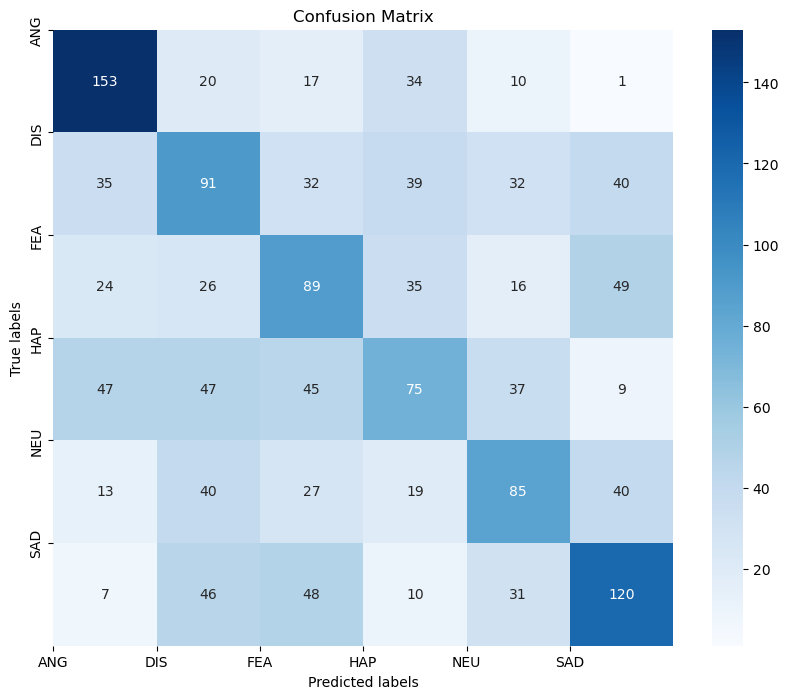

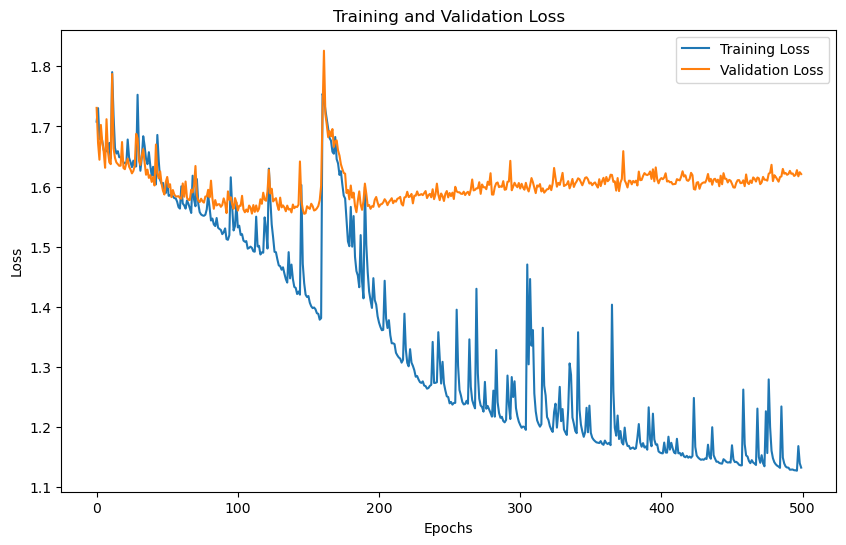

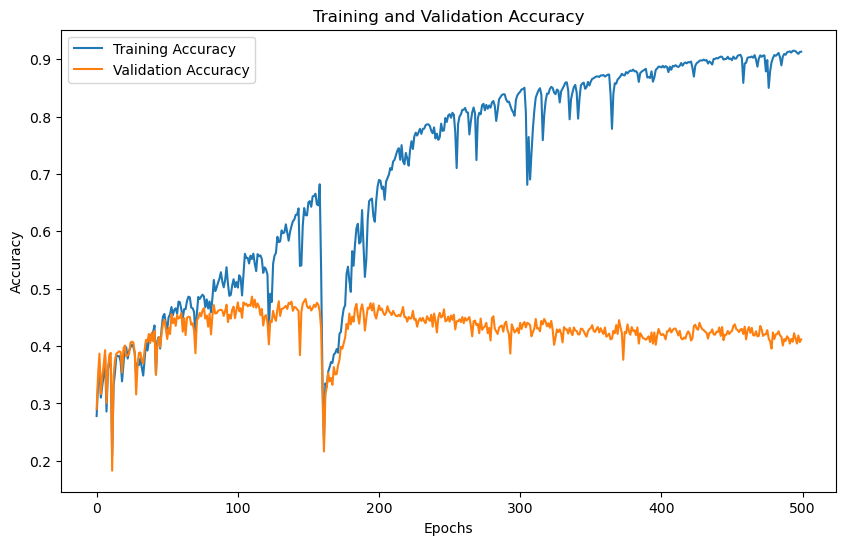

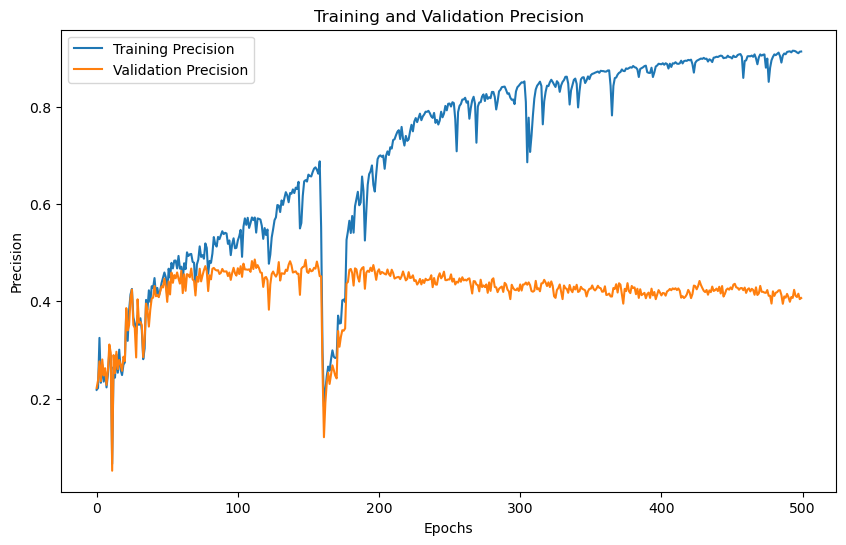

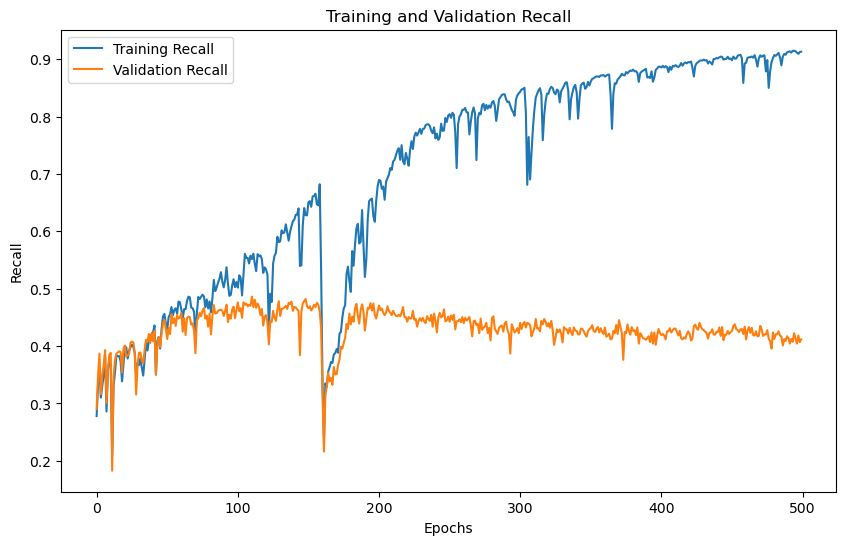

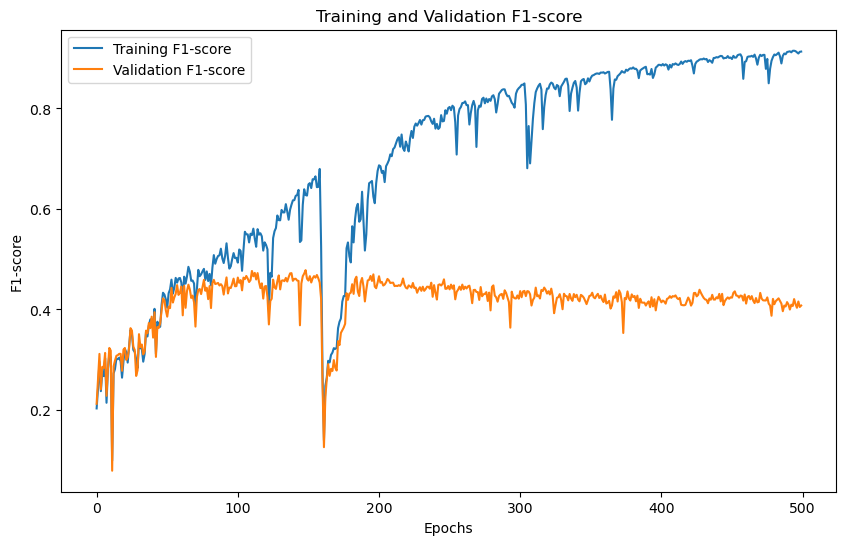

'Model Training and Evaluation Successfully completed'

In [43]:
train_model()

# N_MFCC 40

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  40
No. of classes 6
Input size : 40
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (7442, 40)
Y Shape : (7442, 6)
Training with N_MFCC: 40
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7258, Training Accuracy: 0.3200, Training Precision:0.2309,Training Recall:0.3200,Training F1-Score:0.2369
Validation Loss: 1.6925, Validation Accuracy: 0.3291, Validation Precision:0.2736,Validation Recall:0.3291,Validation F1-Score:0.2467
Epoch [2/500],
Training Loss: 1.6778, Training Accuracy: 0.2323, Training Precision:0.2365,Training Recall:0.2323,Training F1-Score:0.1585
Validation Loss: 1.7767, Validation Accuracy: 0.2015, Validation Precision:0.2399,Validation Recall:0.2015,Validation F1-Score:0.1178
Epoch [3/500],
Training Loss: 1.7204, Training Accuracy: 0.3560, Training Precision:0.2733,Training Recall:0.3560,Training F1-Score:0.3047
Validation Loss: 1.6577, Validation Accuracy: 0.3727, Validation Precisio

Epoch [31/500],
Training Loss: 1.6715, Training Accuracy: 0.3363, Training Precision:0.2576,Training Recall:0.3363,Training F1-Score:0.2675
Validation Loss: 1.6895, Validation Accuracy: 0.3257, Validation Precision:0.2494,Validation Recall:0.3257,Validation F1-Score:0.2545
Epoch [32/500],
Training Loss: 1.6561, Training Accuracy: 0.3800, Training Precision:0.2708,Training Recall:0.3800,Training F1-Score:0.3110
Validation Loss: 1.6327, Validation Accuracy: 0.3929, Validation Precision:0.2787,Validation Recall:0.3929,Validation F1-Score:0.3218
Epoch [33/500],
Training Loss: 1.6458, Training Accuracy: 0.3739, Training Precision:0.2480,Training Recall:0.3739,Training F1-Score:0.2923
Validation Loss: 1.6399, Validation Accuracy: 0.3882, Validation Precision:0.2540,Validation Recall:0.3882,Validation F1-Score:0.3036
Epoch [34/500],
Training Loss: 1.6447, Training Accuracy: 0.3961, Training Precision:0.2783,Training Recall:0.3961,Training F1-Score:0.3209
Validation Loss: 1.6268, Validation Ac

Epoch [61/500],
Training Loss: 1.6193, Training Accuracy: 0.4364, Training Precision:0.3610,Training Recall:0.4364,Training F1-Score:0.3893
Validation Loss: 1.5916, Validation Accuracy: 0.4480, Validation Precision:0.3776,Validation Recall:0.4480,Validation F1-Score:0.4006
Epoch [62/500],
Training Loss: 1.6005, Training Accuracy: 0.4374, Training Precision:0.4550,Training Recall:0.4374,Training F1-Score:0.3906
Validation Loss: 1.5895, Validation Accuracy: 0.4459, Validation Precision:0.4464,Validation Recall:0.4459,Validation F1-Score:0.4024
Epoch [63/500],
Training Loss: 1.6005, Training Accuracy: 0.4433, Training Precision:0.4374,Training Recall:0.4433,Training F1-Score:0.4203
Validation Loss: 1.5886, Validation Accuracy: 0.4453, Validation Precision:0.4343,Validation Recall:0.4453,Validation F1-Score:0.4232
Epoch [64/500],
Training Loss: 1.5968, Training Accuracy: 0.4423, Training Precision:0.4459,Training Recall:0.4423,Training F1-Score:0.4150
Validation Loss: 1.5936, Validation Ac

Epoch [91/500],
Training Loss: 1.5640, Training Accuracy: 0.4818, Training Precision:0.4833,Training Recall:0.4818,Training F1-Score:0.4737
Validation Loss: 1.5799, Validation Accuracy: 0.4433, Validation Precision:0.4368,Validation Recall:0.4433,Validation F1-Score:0.4340
Epoch [92/500],
Training Loss: 1.5621, Training Accuracy: 0.4364, Training Precision:0.4418,Training Recall:0.4364,Training F1-Score:0.4210
Validation Loss: 1.6368, Validation Accuracy: 0.3922, Validation Precision:0.4076,Validation Recall:0.3922,Validation F1-Score:0.3714
Epoch [93/500],
Training Loss: 1.5650, Training Accuracy: 0.5120, Training Precision:0.5187,Training Recall:0.5120,Training F1-Score:0.5064
Validation Loss: 1.5763, Validation Accuracy: 0.4574, Validation Precision:0.4488,Validation Recall:0.4574,Validation F1-Score:0.4494
Epoch [94/500],
Training Loss: 1.5347, Training Accuracy: 0.4860, Training Precision:0.4971,Training Recall:0.4860,Training F1-Score:0.4759
Validation Loss: 1.5975, Validation Ac

Epoch [121/500],
Training Loss: 1.5087, Training Accuracy: 0.5066, Training Precision:0.5641,Training Recall:0.5066,Training F1-Score:0.4887
Validation Loss: 1.5864, Validation Accuracy: 0.4412, Validation Precision:0.4484,Validation Recall:0.4412,Validation F1-Score:0.4135
Epoch [122/500],
Training Loss: 1.5597, Training Accuracy: 0.5112, Training Precision:0.5388,Training Recall:0.5112,Training F1-Score:0.4951
Validation Loss: 1.5964, Validation Accuracy: 0.4318, Validation Precision:0.4264,Validation Recall:0.4318,Validation F1-Score:0.4101
Epoch [123/500],
Training Loss: 1.5474, Training Accuracy: 0.5140, Training Precision:0.5564,Training Recall:0.5140,Training F1-Score:0.5058
Validation Loss: 1.5789, Validation Accuracy: 0.4540, Validation Precision:0.4662,Validation Recall:0.4540,Validation F1-Score:0.4388
Epoch [124/500],
Training Loss: 1.5388, Training Accuracy: 0.5113, Training Precision:0.5457,Training Recall:0.5113,Training F1-Score:0.5080
Validation Loss: 1.5971, Validatio

...

Epoch [361/500],
Training Loss: 1.1886, Training Accuracy: 0.8589, Training Precision:0.8604,Training Recall:0.8589,Training F1-Score:0.8585
Validation Loss: 1.5709, Validation Accuracy: 0.4600, Validation Precision:0.4591,Validation Recall:0.4600,Validation F1-Score:0.4590
Epoch [362/500],
Training Loss: 1.1862, Training Accuracy: 0.8554, Training Precision:0.8579,Training Recall:0.8554,Training F1-Score:0.8552
Validation Loss: 1.5826, Validation Accuracy: 0.4513, Validation Precision:0.4557,Validation Recall:0.4513,Validation F1-Score:0.4506
Epoch [363/500],
Training Loss: 1.2832, Training Accuracy: 0.8320, Training Precision:0.8333,Training Recall:0.8320,Training F1-Score:0.8320
Validation Loss: 1.5827, Validation Accuracy: 0.4493, Validation Precision:0.4527,Validation Recall:0.4493,Validation F1-Score:0.4479
Epoch [364/500],
Training Loss: 1.2035, Training Accuracy: 0.8530, Training Precision:0.8544,Training Recall:0.8530,Training F1-Score:0.8526
Validation Loss: 1.5765, Validatio

Epoch [391/500],
Training Loss: 1.1982, Training Accuracy: 0.8559, Training Precision:0.8566,Training Recall:0.8559,Training F1-Score:0.8555
Validation Loss: 1.5833, Validation Accuracy: 0.4513, Validation Precision:0.4471,Validation Recall:0.4513,Validation F1-Score:0.4472
Epoch [392/500],
Training Loss: 1.1872, Training Accuracy: 0.8631, Training Precision:0.8636,Training Recall:0.8631,Training F1-Score:0.8626
Validation Loss: 1.5837, Validation Accuracy: 0.4527, Validation Precision:0.4493,Validation Recall:0.4527,Validation F1-Score:0.4506
Epoch [393/500],
Training Loss: 1.1819, Training Accuracy: 0.8539, Training Precision:0.8578,Training Recall:0.8539,Training F1-Score:0.8540
Validation Loss: 1.5983, Validation Accuracy: 0.4345, Validation Precision:0.4395,Validation Recall:0.4345,Validation F1-Score:0.4315
Epoch [394/500],
Training Loss: 1.4197, Training Accuracy: 0.7761, Training Precision:0.7815,Training Recall:0.7761,Training F1-Score:0.7760
Validation Loss: 1.5903, Validatio

Epoch [421/500],
Training Loss: 1.1757, Training Accuracy: 0.8589, Training Precision:0.8637,Training Recall:0.8589,Training F1-Score:0.8591
Validation Loss: 1.5897, Validation Accuracy: 0.4419, Validation Precision:0.4439,Validation Recall:0.4419,Validation F1-Score:0.4401
Epoch [422/500],
Training Loss: 1.3061, Training Accuracy: 0.8337, Training Precision:0.8348,Training Recall:0.8337,Training F1-Score:0.8336
Validation Loss: 1.6089, Validation Accuracy: 0.4231, Validation Precision:0.4227,Validation Recall:0.4231,Validation F1-Score:0.4192
Epoch [423/500],
Training Loss: 1.2074, Training Accuracy: 0.8683, Training Precision:0.8693,Training Recall:0.8683,Training F1-Score:0.8681
Validation Loss: 1.5877, Validation Accuracy: 0.4439, Validation Precision:0.4412,Validation Recall:0.4439,Validation F1-Score:0.4407
Epoch [424/500],
Training Loss: 1.1773, Training Accuracy: 0.8747, Training Precision:0.8755,Training Recall:0.8747,Training F1-Score:0.8744
Validation Loss: 1.5805, Validatio

Epoch [451/500],
Training Loss: 1.1617, Training Accuracy: 0.8839, Training Precision:0.8844,Training Recall:0.8839,Training F1-Score:0.8836
Validation Loss: 1.6017, Validation Accuracy: 0.4305, Validation Precision:0.4225,Validation Recall:0.4305,Validation F1-Score:0.4250
Epoch [452/500],
Training Loss: 1.1602, Training Accuracy: 0.8849, Training Precision:0.8857,Training Recall:0.8849,Training F1-Score:0.8846
Validation Loss: 1.5923, Validation Accuracy: 0.4419, Validation Precision:0.4375,Validation Recall:0.4419,Validation F1-Score:0.4391
Epoch [453/500],
Training Loss: 1.1578, Training Accuracy: 0.8848, Training Precision:0.8863,Training Recall:0.8848,Training F1-Score:0.8846
Validation Loss: 1.5926, Validation Accuracy: 0.4433, Validation Precision:0.4417,Validation Recall:0.4433,Validation F1-Score:0.4420
Epoch [454/500],
Training Loss: 1.1605, Training Accuracy: 0.8843, Training Precision:0.8854,Training Recall:0.8843,Training F1-Score:0.8840
Validation Loss: 1.6060, Validatio

Epoch [481/500],
Training Loss: 1.1596, Training Accuracy: 0.8952, Training Precision:0.8961,Training Recall:0.8952,Training F1-Score:0.8950
Validation Loss: 1.5992, Validation Accuracy: 0.4345, Validation Precision:0.4329,Validation Recall:0.4345,Validation F1-Score:0.4325
Epoch [482/500],
Training Loss: 1.1491, Training Accuracy: 0.8962, Training Precision:0.8968,Training Recall:0.8962,Training F1-Score:0.8959
Validation Loss: 1.5989, Validation Accuracy: 0.4325, Validation Precision:0.4267,Validation Recall:0.4325,Validation F1-Score:0.4281
Epoch [483/500],
Training Loss: 1.1490, Training Accuracy: 0.8982, Training Precision:0.8994,Training Recall:0.8982,Training F1-Score:0.8980
Validation Loss: 1.6045, Validation Accuracy: 0.4258, Validation Precision:0.4204,Validation Recall:0.4258,Validation F1-Score:0.4215
Epoch [484/500],
Training Loss: 1.1460, Training Accuracy: 0.8984, Training Precision:0.8993,Training Recall:0.8984,Training F1-Score:0.8981
Validation Loss: 1.6044, Validatio

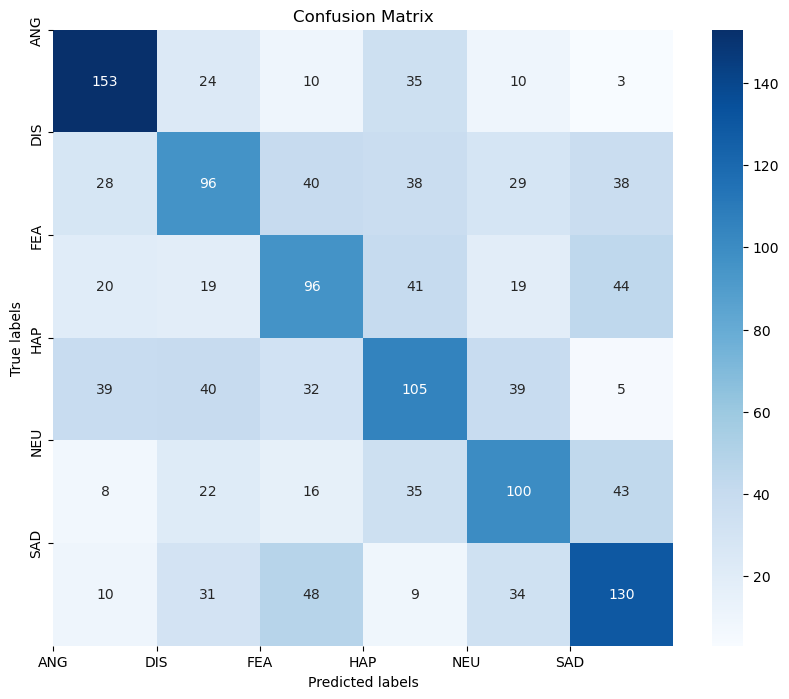

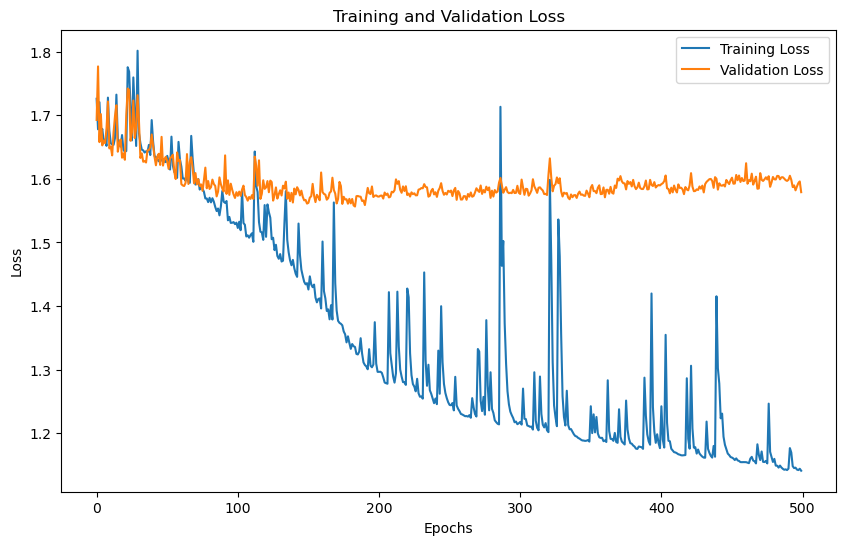

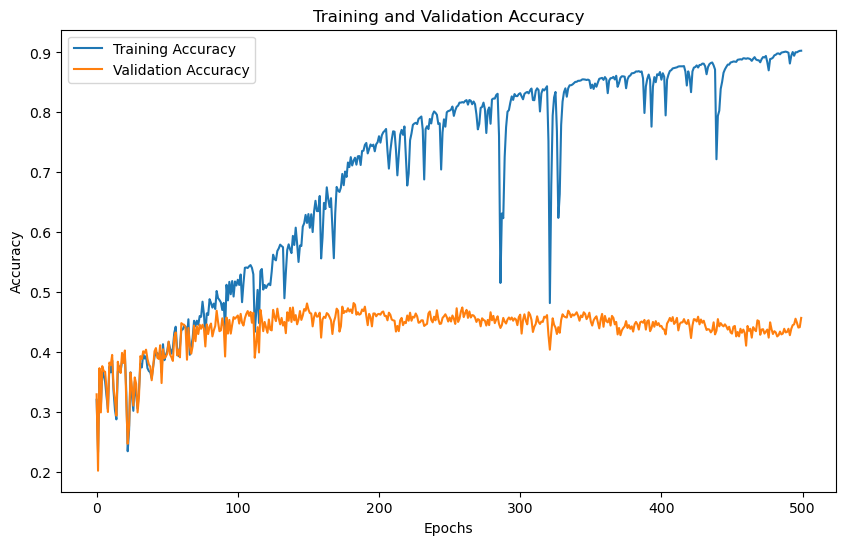

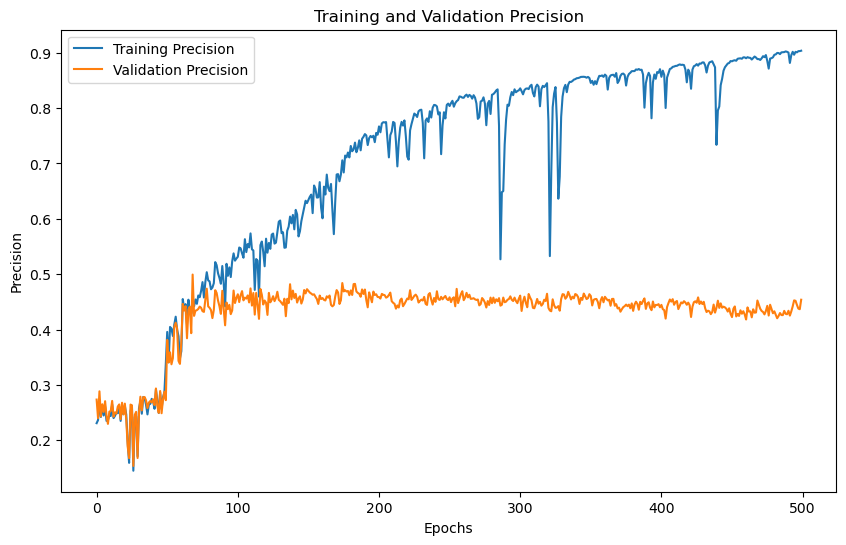

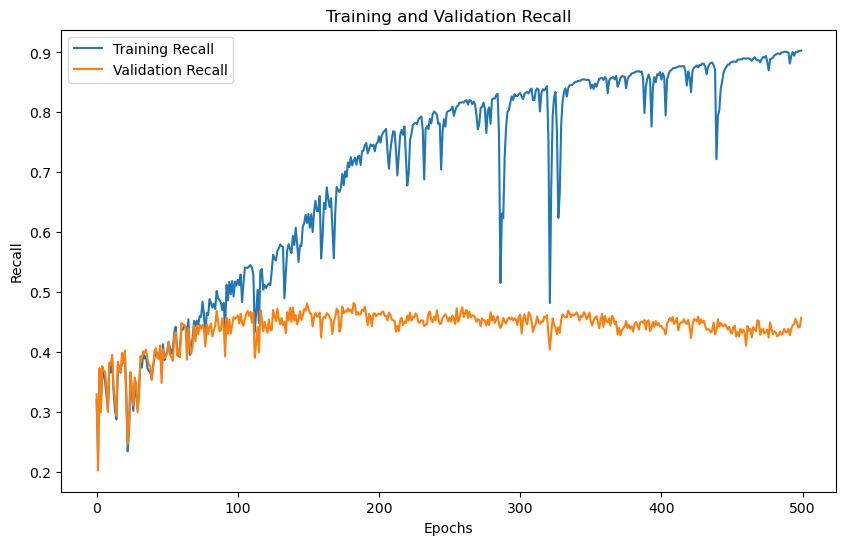

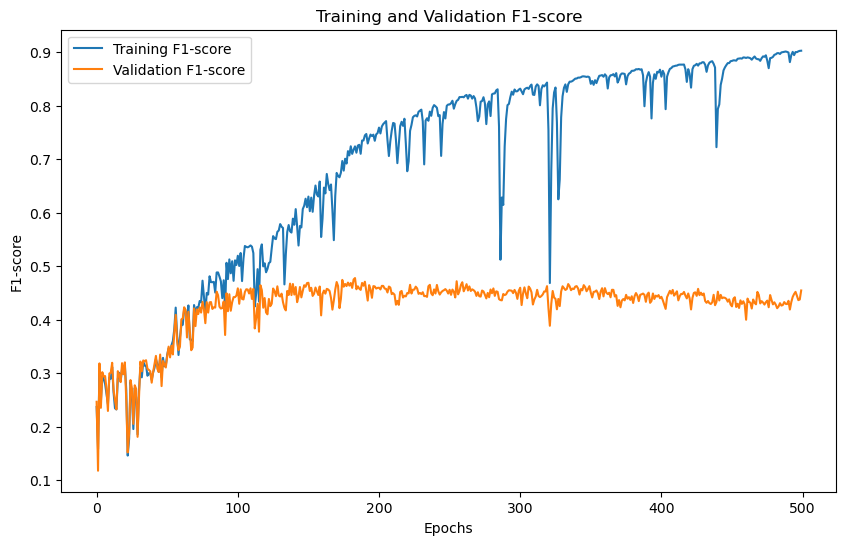

'Model Training and Evaluation Successfully completed'

In [44]:
train_model()

# TESS

# N_MFCC 16

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  16
No. of classes 7
Input size : 16
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (2800, 16)
Y Shape : (2800, 7)
Training with N_MFCC: 16
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8632, Training Accuracy: 0.4638, Training Precision:0.4594,Training Recall:0.4638,Training F1-Score:0.3879
Validation Loss: 1.7292, Validation Accuracy: 0.4446, Validation Precision:0.4856,Validation Recall:0.4446,Validation F1-Score:0.3772
Epoch [2/500],
Training Loss: 1.6620, Training Accuracy: 0.6098, Training Precision:0.5471,Training Recall:0.6098,Training F1-Score:0.5669
Validation Loss: 1.6040, Validation Accuracy: 0.5946, Validation Precision:0.5394,Validation Recall:0.5946,Validation F1-Score:0.5539
Epoch [3/500],
Training Loss: 1.5951, Training Accuracy: 0.6379, Training Precision:0.6476,Training Recall:0.6379,Training F1-Score:0.6360
Validation Loss: 1.5690, Validation Accuracy: 0.6161, Validation Precision

Epoch [31/500],
Training Loss: 1.2108, Training Accuracy: 0.9652, Training Precision:0.9656,Training Recall:0.9652,Training F1-Score:0.9651
Validation Loss: 1.2408, Validation Accuracy: 0.9268, Validation Precision:0.9281,Validation Recall:0.9268,Validation F1-Score:0.9270
Epoch [32/500],
Training Loss: 1.2106, Training Accuracy: 0.9442, Training Precision:0.9476,Training Recall:0.9442,Training F1-Score:0.9444
Validation Loss: 1.2488, Validation Accuracy: 0.9179, Validation Precision:0.9256,Validation Recall:0.9179,Validation F1-Score:0.9187
Epoch [33/500],
Training Loss: 1.2163, Training Accuracy: 0.9317, Training Precision:0.9370,Training Recall:0.9317,Training F1-Score:0.9314
Validation Loss: 1.2629, Validation Accuracy: 0.9018, Validation Precision:0.9090,Validation Recall:0.9018,Validation F1-Score:0.9012
Epoch [34/500],
Training Loss: 1.2187, Training Accuracy: 0.9460, Training Precision:0.9481,Training Recall:0.9460,Training F1-Score:0.9464
Validation Loss: 1.2700, Validation Ac

Epoch [61/500],
Training Loss: 1.1895, Training Accuracy: 0.9830, Training Precision:0.9832,Training Recall:0.9830,Training F1-Score:0.9830
Validation Loss: 1.2298, Validation Accuracy: 0.9411, Validation Precision:0.9419,Validation Recall:0.9411,Validation F1-Score:0.9411
Epoch [62/500],
Training Loss: 1.1888, Training Accuracy: 0.9857, Training Precision:0.9858,Training Recall:0.9857,Training F1-Score:0.9857
Validation Loss: 1.2274, Validation Accuracy: 0.9411, Validation Precision:0.9418,Validation Recall:0.9411,Validation F1-Score:0.9410
Epoch [63/500],
Training Loss: 1.1824, Training Accuracy: 0.9866, Training Precision:0.9867,Training Recall:0.9866,Training F1-Score:0.9866
Validation Loss: 1.2296, Validation Accuracy: 0.9393, Validation Precision:0.9404,Validation Recall:0.9393,Validation F1-Score:0.9393
Epoch [64/500],
Training Loss: 1.1848, Training Accuracy: 0.9839, Training Precision:0.9843,Training Recall:0.9839,Training F1-Score:0.9839
Validation Loss: 1.2387, Validation Ac

Epoch [91/500],
Training Loss: 1.1833, Training Accuracy: 0.9871, Training Precision:0.9872,Training Recall:0.9871,Training F1-Score:0.9870
Validation Loss: 1.2311, Validation Accuracy: 0.9375, Validation Precision:0.9393,Validation Recall:0.9375,Validation F1-Score:0.9371
Epoch [92/500],
Training Loss: 1.1859, Training Accuracy: 0.9804, Training Precision:0.9806,Training Recall:0.9804,Training F1-Score:0.9803
Validation Loss: 1.2340, Validation Accuracy: 0.9375, Validation Precision:0.9380,Validation Recall:0.9375,Validation F1-Score:0.9370
Epoch [93/500],
Training Loss: 1.1818, Training Accuracy: 0.9902, Training Precision:0.9903,Training Recall:0.9902,Training F1-Score:0.9902
Validation Loss: 1.2292, Validation Accuracy: 0.9393, Validation Precision:0.9408,Validation Recall:0.9393,Validation F1-Score:0.9394
Epoch [94/500],
Training Loss: 1.1828, Training Accuracy: 0.9754, Training Precision:0.9775,Training Recall:0.9754,Training F1-Score:0.9754
Validation Loss: 1.2385, Validation Ac

Epoch [121/500],
Training Loss: 1.1715, Training Accuracy: 0.9929, Training Precision:0.9929,Training Recall:0.9929,Training F1-Score:0.9928
Validation Loss: 1.2336, Validation Accuracy: 0.9321, Validation Precision:0.9337,Validation Recall:0.9321,Validation F1-Score:0.9321
Epoch [122/500],
Training Loss: 1.1770, Training Accuracy: 0.9777, Training Precision:0.9790,Training Recall:0.9777,Training F1-Score:0.9778
Validation Loss: 1.2441, Validation Accuracy: 0.9196, Validation Precision:0.9237,Validation Recall:0.9196,Validation F1-Score:0.9198
Epoch [123/500],
Training Loss: 1.1770, Training Accuracy: 0.9929, Training Precision:0.9929,Training Recall:0.9929,Training F1-Score:0.9928
Validation Loss: 1.2248, Validation Accuracy: 0.9411, Validation Precision:0.9414,Validation Recall:0.9411,Validation F1-Score:0.9409
Epoch [124/500],
Training Loss: 1.1742, Training Accuracy: 0.9933, Training Precision:0.9934,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2312, Validatio

...

Epoch [361/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2280, Validation Accuracy: 0.9357, Validation Precision:0.9370,Validation Recall:0.9357,Validation F1-Score:0.9359
Epoch [362/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2276, Validation Accuracy: 0.9375, Validation Precision:0.9385,Validation Recall:0.9375,Validation F1-Score:0.9376
Epoch [363/500],
Training Loss: 1.1682, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2290, Validation Accuracy: 0.9339, Validation Precision:0.9350,Validation Recall:0.9339,Validation F1-Score:0.9341
Epoch [364/500],
Training Loss: 1.1681, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2267, Validatio

Epoch [391/500],
Training Loss: 1.1736, Training Accuracy: 0.9933, Training Precision:0.9934,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2332, Validation Accuracy: 0.9339, Validation Precision:0.9334,Validation Recall:0.9339,Validation F1-Score:0.9335
Epoch [392/500],
Training Loss: 1.1719, Training Accuracy: 0.9951, Training Precision:0.9951,Training Recall:0.9951,Training F1-Score:0.9951
Validation Loss: 1.2298, Validation Accuracy: 0.9339, Validation Precision:0.9347,Validation Recall:0.9339,Validation F1-Score:0.9338
Epoch [393/500],
Training Loss: 1.1720, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2386, Validation Accuracy: 0.9268, Validation Precision:0.9277,Validation Recall:0.9268,Validation F1-Score:0.9268
Epoch [394/500],
Training Loss: 1.1720, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2384, Validatio

Epoch [421/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2263, Validation Accuracy: 0.9357, Validation Precision:0.9364,Validation Recall:0.9357,Validation F1-Score:0.9357
Epoch [422/500],
Training Loss: 1.1676, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2262, Validation Accuracy: 0.9375, Validation Precision:0.9376,Validation Recall:0.9375,Validation F1-Score:0.9374
Epoch [423/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2253, Validation Accuracy: 0.9411, Validation Precision:0.9413,Validation Recall:0.9411,Validation F1-Score:0.9410
Epoch [424/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2240, Validatio

Epoch [451/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2255, Validation Accuracy: 0.9393, Validation Precision:0.9398,Validation Recall:0.9393,Validation F1-Score:0.9393
Epoch [452/500],
Training Loss: 1.1676, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2245, Validation Accuracy: 0.9411, Validation Precision:0.9416,Validation Recall:0.9411,Validation F1-Score:0.9411
Epoch [453/500],
Training Loss: 1.1676, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2237, Validation Accuracy: 0.9393, Validation Precision:0.9399,Validation Recall:0.9393,Validation F1-Score:0.9393
Epoch [454/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2239, Validatio

Epoch [481/500],
Training Loss: 1.1676, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2247, Validation Accuracy: 0.9411, Validation Precision:0.9419,Validation Recall:0.9411,Validation F1-Score:0.9412
Epoch [482/500],
Training Loss: 1.1676, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2235, Validation Accuracy: 0.9375, Validation Precision:0.9387,Validation Recall:0.9375,Validation F1-Score:0.9377
Epoch [483/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2239, Validation Accuracy: 0.9393, Validation Precision:0.9404,Validation Recall:0.9393,Validation F1-Score:0.9395
Epoch [484/500],
Training Loss: 1.1676, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2226, Validatio

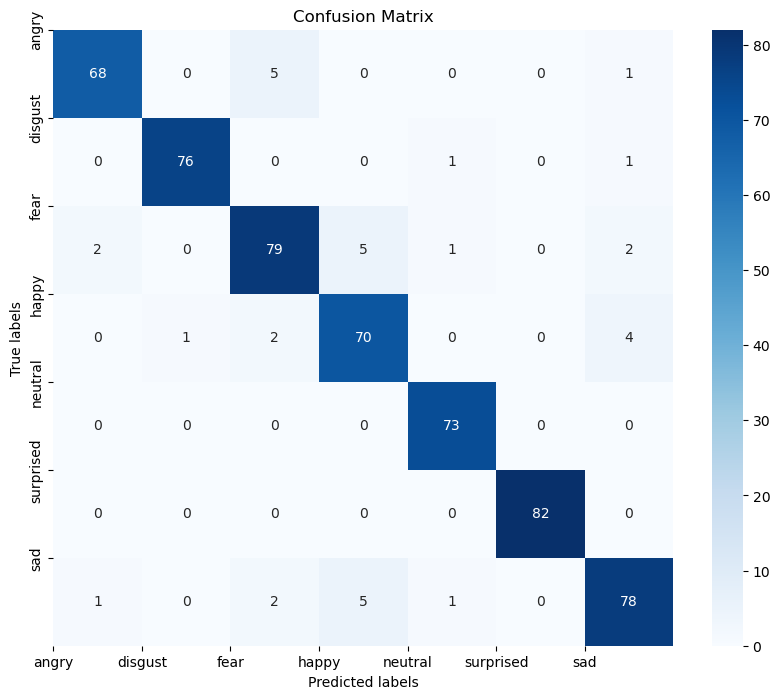

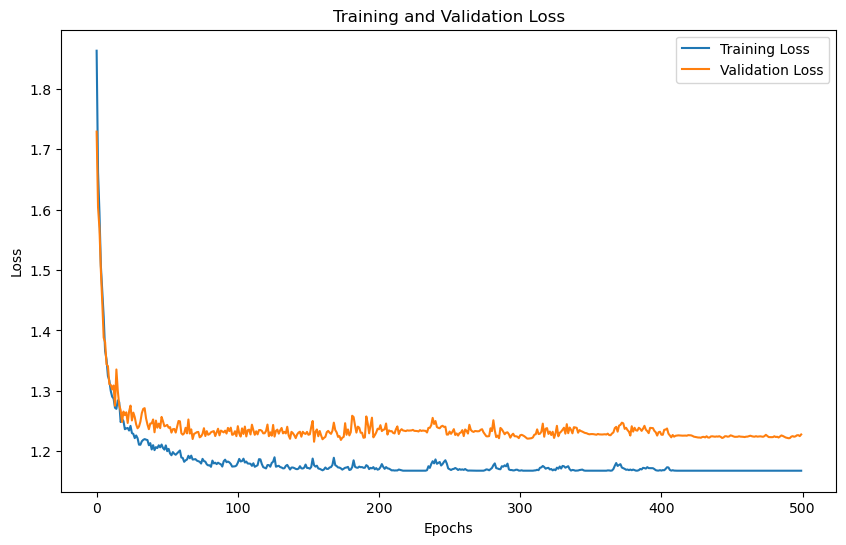

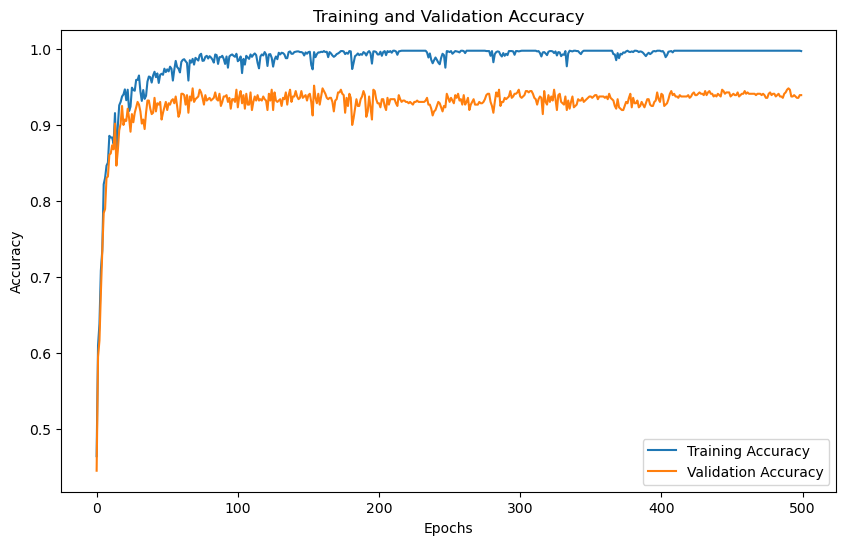

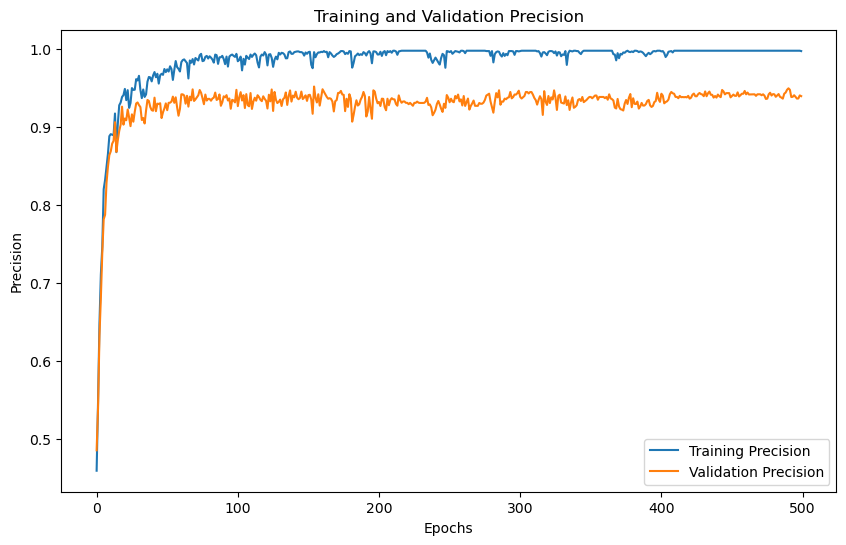

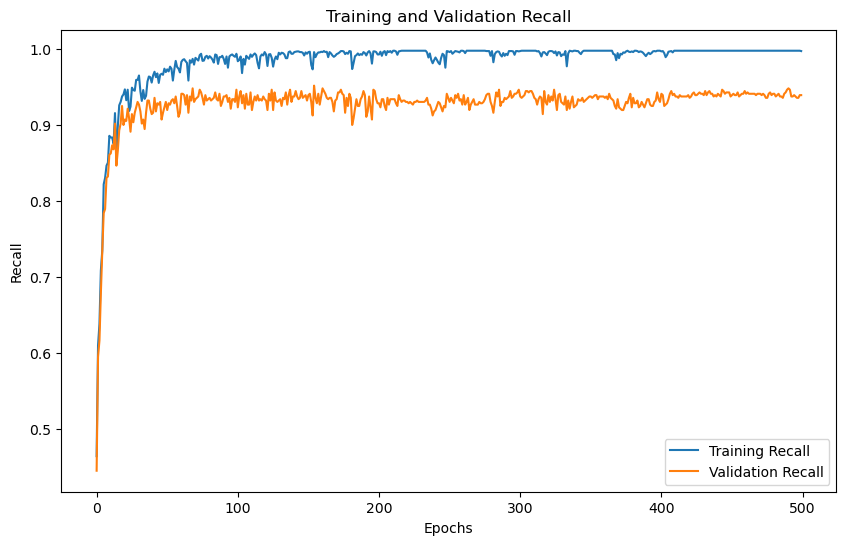

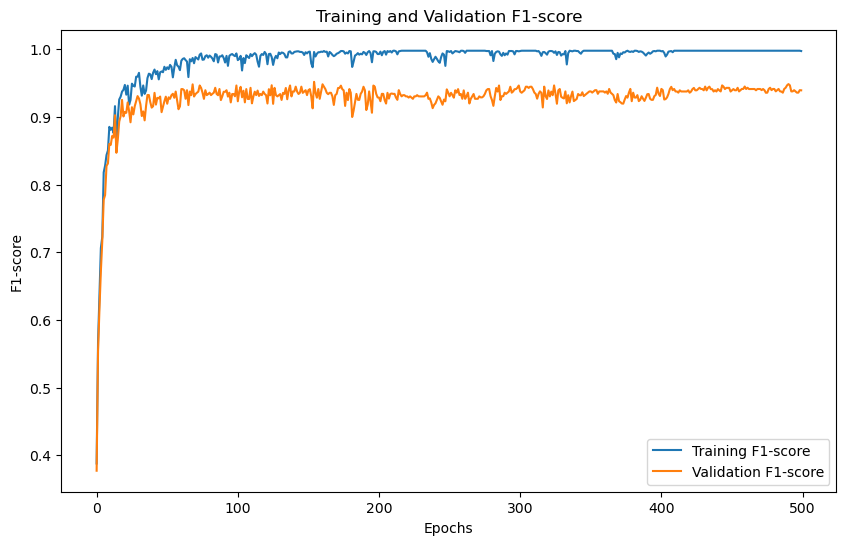

'Model Training and Evaluation Successfully completed'

In [45]:
train_model()

# N_MFCC 24

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  24
No. of classes 7
Input size : 24
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (2800, 24)
Y Shape : (2800, 7)
Training with N_MFCC: 24
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7630, Training Accuracy: 0.6397, Training Precision:0.7299,Training Recall:0.6397,Training F1-Score:0.5938
Validation Loss: 1.5490, Validation Accuracy: 0.6661, Validation Precision:0.7565,Validation Recall:0.6661,Validation F1-Score:0.6249
Epoch [2/500],
Training Loss: 1.4613, Training Accuracy: 0.7946, Training Precision:0.8050,Training Recall:0.7946,Training F1-Score:0.7820
Validation Loss: 1.3829, Validation Accuracy: 0.7804, Validation Precision:0.7909,Validation Recall:0.7804,Validation F1-Score:0.7662
Epoch [3/500],
Training Loss: 1.3822, Training Accuracy: 0.7790, Training Precision:0.7974,Training Recall:0.7790,Training F1-Score:0.7793
Validation Loss: 1.3891, Validation Accuracy: 0.7875, Validation Precision

Epoch [31/500],
Training Loss: 1.1868, Training Accuracy: 0.9848, Training Precision:0.9851,Training Recall:0.9848,Training F1-Score:0.9848
Validation Loss: 1.1958, Validation Accuracy: 0.9696, Validation Precision:0.9696,Validation Recall:0.9696,Validation F1-Score:0.9696
Epoch [32/500],
Training Loss: 1.1969, Training Accuracy: 0.9563, Training Precision:0.9619,Training Recall:0.9563,Training F1-Score:0.9558
Validation Loss: 1.2088, Validation Accuracy: 0.9589, Validation Precision:0.9613,Validation Recall:0.9589,Validation F1-Score:0.9585
Epoch [33/500],
Training Loss: 1.1925, Training Accuracy: 0.9795, Training Precision:0.9801,Training Recall:0.9795,Training F1-Score:0.9795
Validation Loss: 1.2010, Validation Accuracy: 0.9625, Validation Precision:0.9637,Validation Recall:0.9625,Validation F1-Score:0.9626
Epoch [34/500],
Training Loss: 1.1907, Training Accuracy: 0.9884, Training Precision:0.9885,Training Recall:0.9884,Training F1-Score:0.9884
Validation Loss: 1.1905, Validation Ac

Epoch [61/500],
Training Loss: 1.1750, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 1.1858, Validation Accuracy: 0.9804, Validation Precision:0.9807,Validation Recall:0.9804,Validation F1-Score:0.9803
Epoch [62/500],
Training Loss: 1.1715, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.1885, Validation Accuracy: 0.9768, Validation Precision:0.9769,Validation Recall:0.9768,Validation F1-Score:0.9767
Epoch [63/500],
Training Loss: 1.1759, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1886, Validation Accuracy: 0.9786, Validation Precision:0.9791,Validation Recall:0.9786,Validation F1-Score:0.9785
Epoch [64/500],
Training Loss: 1.1773, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.1927, Validation Ac

Epoch [91/500],
Training Loss: 1.1723, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 1.1871, Validation Accuracy: 0.9804, Validation Precision:0.9805,Validation Recall:0.9804,Validation F1-Score:0.9803
Epoch [92/500],
Training Loss: 1.1726, Training Accuracy: 0.9897, Training Precision:0.9900,Training Recall:0.9897,Training F1-Score:0.9897
Validation Loss: 1.1974, Validation Accuracy: 0.9696, Validation Precision:0.9706,Validation Recall:0.9696,Validation F1-Score:0.9694
Epoch [93/500],
Training Loss: 1.1735, Training Accuracy: 0.9929, Training Precision:0.9931,Training Recall:0.9929,Training F1-Score:0.9929
Validation Loss: 1.1975, Validation Accuracy: 0.9696, Validation Precision:0.9705,Validation Recall:0.9696,Validation F1-Score:0.9696
Epoch [94/500],
Training Loss: 1.1787, Training Accuracy: 0.9737, Training Precision:0.9750,Training Recall:0.9737,Training F1-Score:0.9736
Validation Loss: 1.2214, Validation Ac

Epoch [121/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1745, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [122/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1743, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [123/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1742, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [124/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1743, Validatio

...

Epoch [361/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1791, Validation Accuracy: 0.9857, Validation Precision:0.9859,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [362/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1787, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [363/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1784, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [364/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1786, Validatio

Epoch [391/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1779, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [392/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1774, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [393/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1773, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [394/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1779, Validatio

Epoch [421/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1780, Validation Accuracy: 0.9857, Validation Precision:0.9858,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [422/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1780, Validation Accuracy: 0.9857, Validation Precision:0.9858,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [423/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1778, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [424/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1780, Validatio

Epoch [451/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1773, Validation Accuracy: 0.9857, Validation Precision:0.9858,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [452/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1778, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [453/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1772, Validation Accuracy: 0.9857, Validation Precision:0.9858,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [454/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1770, Validatio

Epoch [481/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1754, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [482/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1762, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [483/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1761, Validation Accuracy: 0.9911, Validation Precision:0.9911,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [484/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1761, Validatio

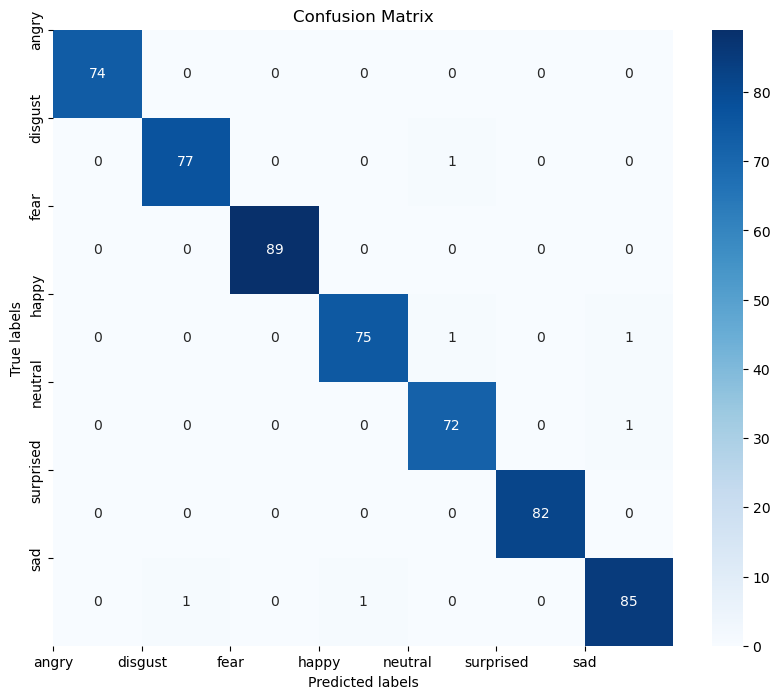

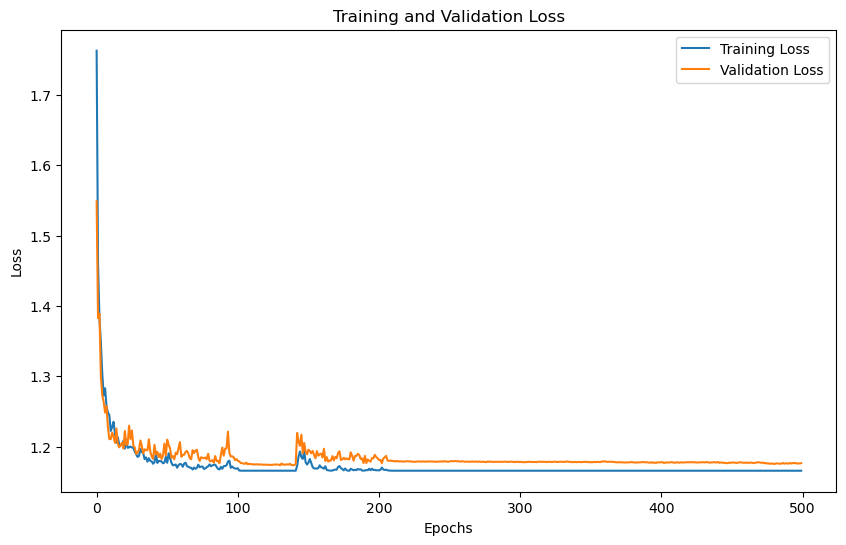

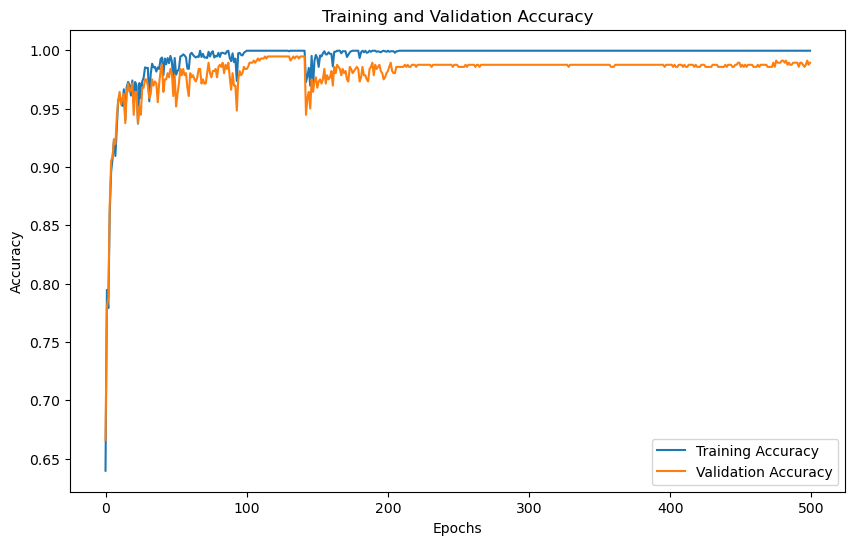

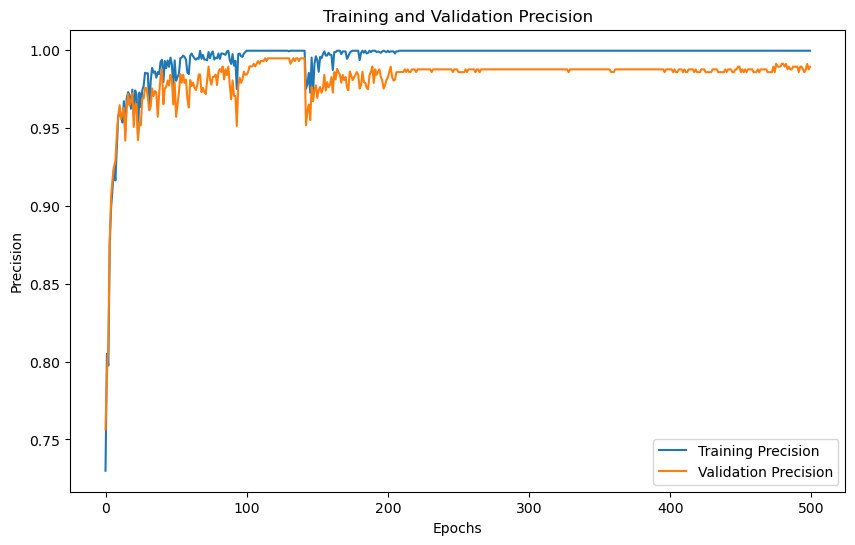

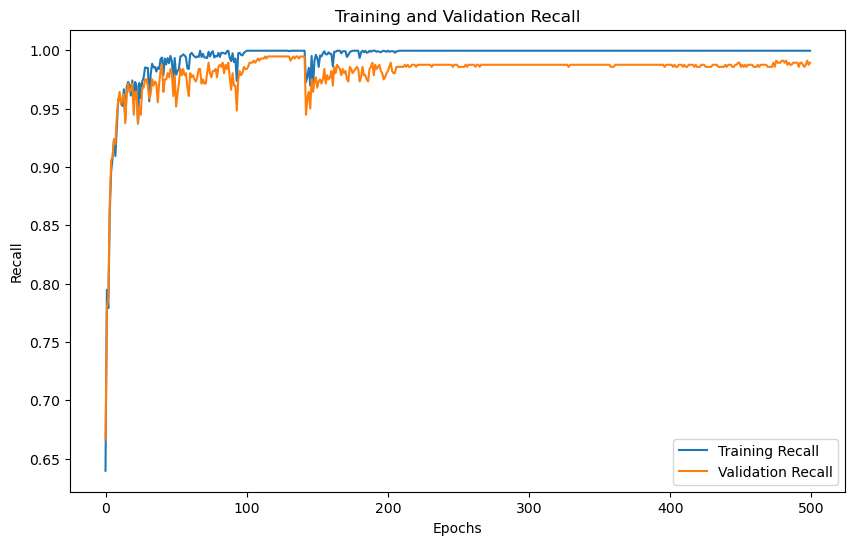

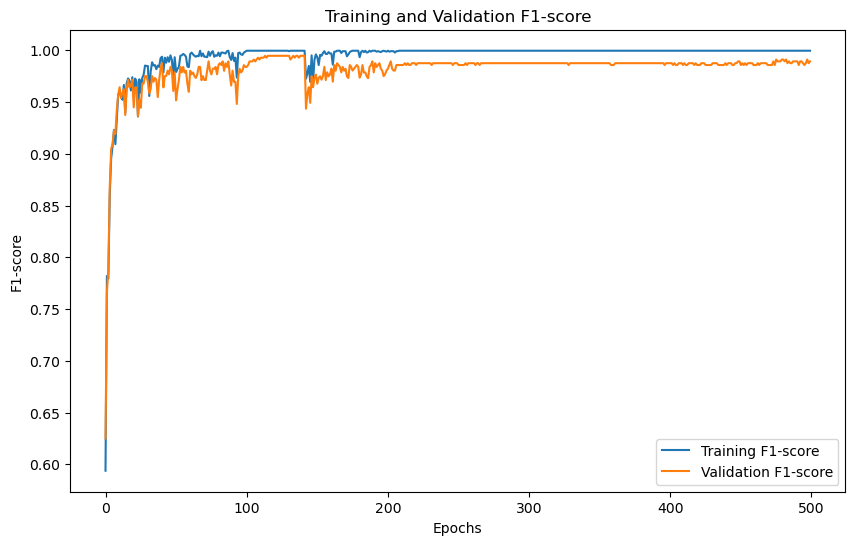

'Model Training and Evaluation Successfully completed'

In [46]:
train_model()

# N_MFCC 32

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  32
No. of classes 7
Input size : 32
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (2800, 32)
Y Shape : (2800, 7)
Training with N_MFCC: 32
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7106, Training Accuracy: 0.7750, Training Precision:0.8191,Training Recall:0.7750,Training F1-Score:0.7341
Validation Loss: 1.4301, Validation Accuracy: 0.7875, Validation Precision:0.8258,Validation Recall:0.7875,Validation F1-Score:0.7543
Epoch [2/500],
Training Loss: 1.3432, Training Accuracy: 0.9013, Training Precision:0.9057,Training Recall:0.9013,Training F1-Score:0.9005
Validation Loss: 1.2721, Validation Accuracy: 0.9071, Validation Precision:0.9104,Validation Recall:0.9071,Validation F1-Score:0.9071
Epoch [3/500],
Training Loss: 1.2567, Training Accuracy: 0.9522, Training Precision:0.9529,Training Recall:0.9522,Training F1-Score:0.9523
Validation Loss: 1.2254, Validation Accuracy: 0.9518, Validation Precision

Epoch [31/500],
Training Loss: 1.1721, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 1.1805, Validation Accuracy: 0.9857, Validation Precision:0.9857,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [32/500],
Training Loss: 1.1697, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1809, Validation Accuracy: 0.9857, Validation Precision:0.9857,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [33/500],
Training Loss: 1.1742, Training Accuracy: 0.9929, Training Precision:0.9931,Training Recall:0.9929,Training F1-Score:0.9929
Validation Loss: 1.1804, Validation Accuracy: 0.9857, Validation Precision:0.9861,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [34/500],
Training Loss: 1.1751, Training Accuracy: 0.9964, Training Precision:0.9964,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 1.1800, Validation Ac

Epoch [61/500],
Training Loss: 1.1706, Training Accuracy: 0.9973, Training Precision:0.9974,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 1.1761, Validation Accuracy: 0.9893, Validation Precision:0.9893,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [62/500],
Training Loss: 1.1691, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1771, Validation Accuracy: 0.9911, Validation Precision:0.9913,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [63/500],
Training Loss: 1.1669, Training Accuracy: 0.9933, Training Precision:0.9936,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.1835, Validation Accuracy: 0.9821, Validation Precision:0.9828,Validation Recall:0.9821,Validation F1-Score:0.9822
Epoch [64/500],
Training Loss: 1.1723, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 1.1800, Validation Ac

Epoch [91/500],
Training Loss: 1.1729, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1748, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [92/500],
Training Loss: 1.1698, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1753, Validation Accuracy: 0.9911, Validation Precision:0.9913,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [93/500],
Training Loss: 1.1660, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1729, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [94/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1725, Validation Ac

Epoch [121/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1714, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [122/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1714, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [123/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1711, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [124/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1715, Validatio

...

Epoch [361/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1706, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [362/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1702, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [363/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1705, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [364/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1703, Validatio

Epoch [391/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1712, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [392/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1711, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [393/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1712, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [394/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1711, Validatio

Epoch [421/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1793, Validation Accuracy: 0.9857, Validation Precision:0.9858,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [422/500],
Training Loss: 1.1666, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1776, Validation Accuracy: 0.9875, Validation Precision:0.9877,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [423/500],
Training Loss: 1.1668, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1767, Validation Accuracy: 0.9893, Validation Precision:0.9893,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [424/500],
Training Loss: 1.1667, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1733, Validatio

Epoch [451/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1730, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [452/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1730, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [453/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1729, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [454/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1725, Validatio

Epoch [481/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1735, Validation Accuracy: 0.9911, Validation Precision:0.9911,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [482/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1732, Validation Accuracy: 0.9911, Validation Precision:0.9911,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [483/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1731, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [484/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1724, Validatio

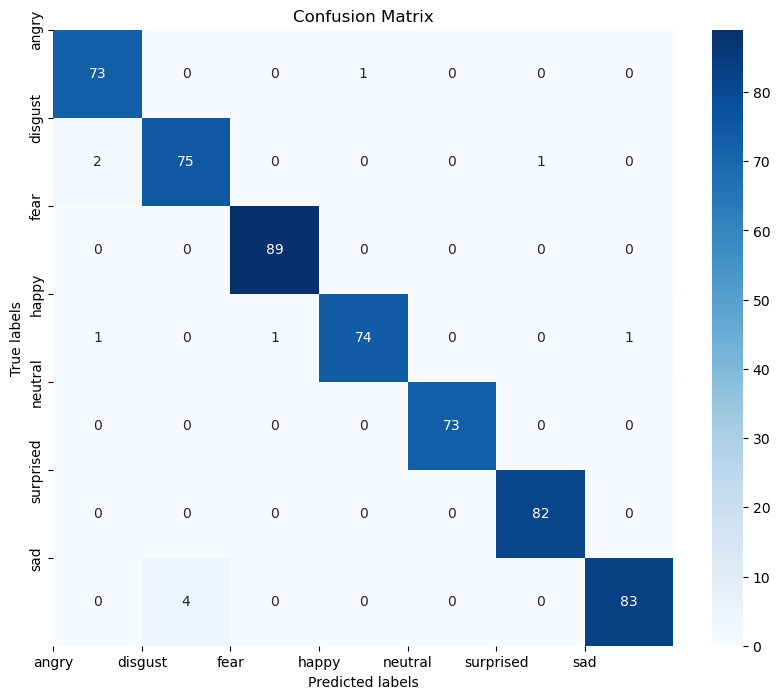

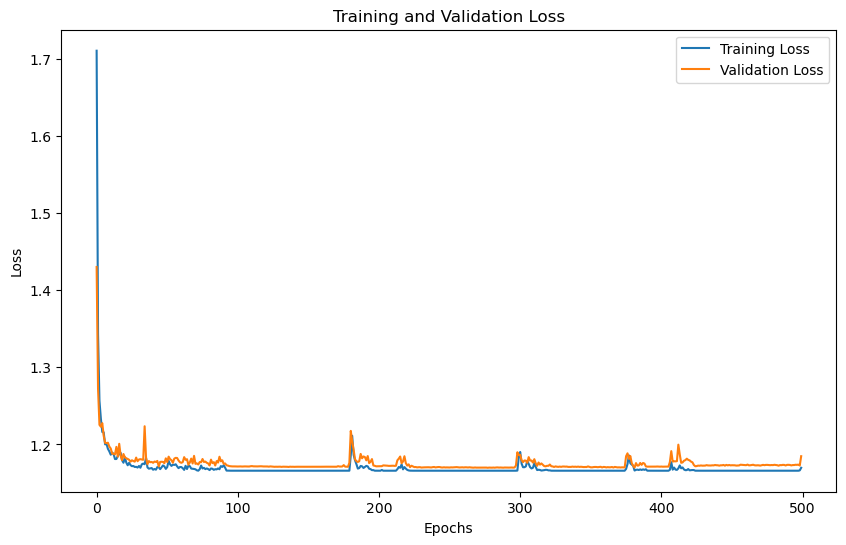

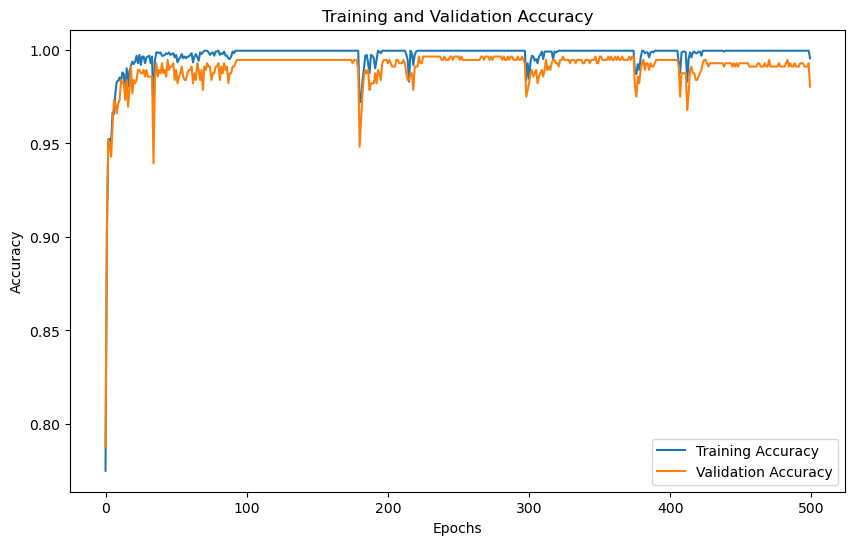

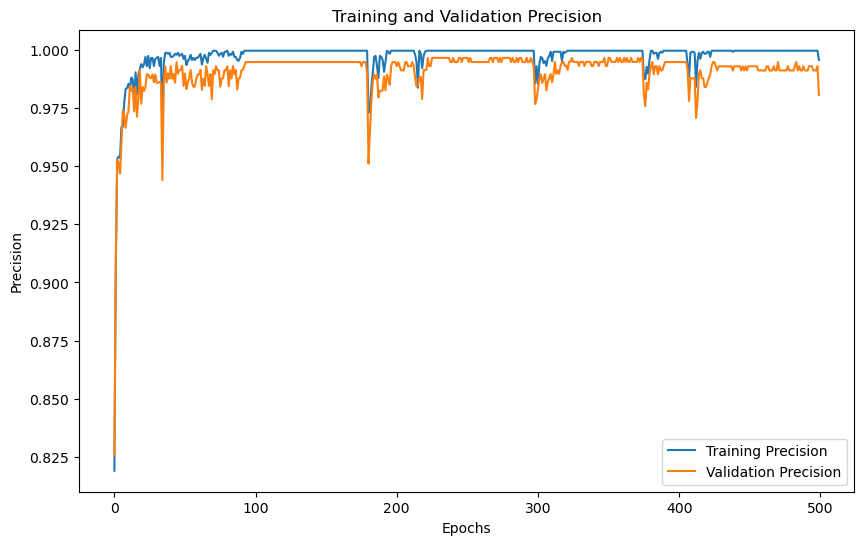

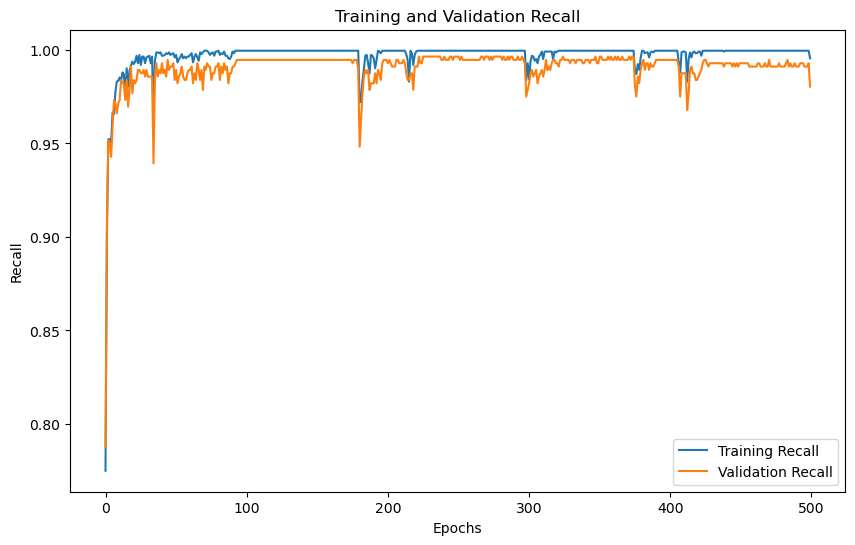

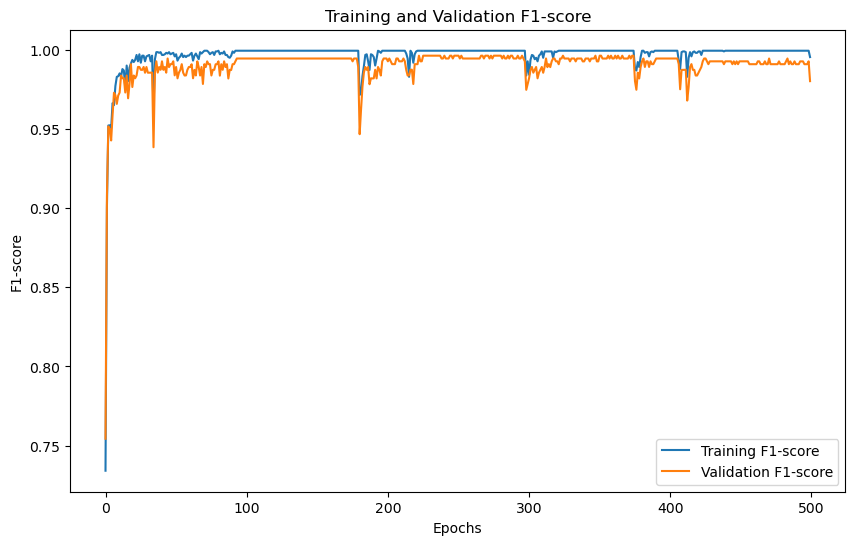

'Model Training and Evaluation Successfully completed'

In [47]:
train_model()

# N_MFCC 40

# 300 epochs

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  40
No. of classes 7
Input size : 40
Hidden Size : 256
Model Name: CNN_LSTM_Model

X Shape : (2800, 40)
Y Shape : (2800, 7)
Training with N_MFCC: 40
Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7408, Training Accuracy: 0.6558, Training Precision:0.4793,Training Recall:0.6558,Training F1-Score:0.5516
Validation Loss: 1.5237, Validation Accuracy: 0.6446, Validation Precision:0.4737,Validation Recall:0.6446,Validation F1-Score:0.5416
Epoch [2/500],
Training Loss: 1.4339, Training Accuracy: 0.8058, Training Precision:0.7080,Training Recall:0.8058,Training F1-Score:0.7501
Validation Loss: 1.3535, Validation Accuracy: 0.8232, Validation Precision:0.7241,Validation Recall:0.8232,Validation F1-Score:0.7674
Epoch [3/500],
Training Loss: 1.3410, Training Accuracy: 0.8888, Training Precision:0.9046,Training Recall:0.8888,Training F1-Score:0.8897
Validation Loss: 1.2830, Validation Accuracy: 0.8929, Validation Precision

Epoch [31/500],
Training Loss: 1.1749, Training Accuracy: 0.9879, Training Precision:0.9885,Training Recall:0.9879,Training F1-Score:0.9879
Validation Loss: 1.1813, Validation Accuracy: 0.9875, Validation Precision:0.9875,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [32/500],
Training Loss: 1.1707, Training Accuracy: 0.9938, Training Precision:0.9938,Training Recall:0.9938,Training F1-Score:0.9938
Validation Loss: 1.1843, Validation Accuracy: 0.9804, Validation Precision:0.9808,Validation Recall:0.9804,Validation F1-Score:0.9802
Epoch [33/500],
Training Loss: 1.1698, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1734, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [34/500],
Training Loss: 1.1749, Training Accuracy: 0.9862, Training Precision:0.9866,Training Recall:0.9862,Training F1-Score:0.9861
Validation Loss: 1.1922, Validation Ac

Epoch [61/500],
Training Loss: 1.1655, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1731, Validation Accuracy: 0.9929, Validation Precision:0.9930,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [62/500],
Training Loss: 1.1655, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1733, Validation Accuracy: 0.9929, Validation Precision:0.9930,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [63/500],
Training Loss: 1.1655, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1734, Validation Accuracy: 0.9929, Validation Precision:0.9930,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [64/500],
Training Loss: 1.1660, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1730, Validation Ac

Epoch [91/500],
Training Loss: 1.1656, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1845, Validation Accuracy: 0.9821, Validation Precision:0.9823,Validation Recall:0.9821,Validation F1-Score:0.9820
Epoch [92/500],
Training Loss: 1.1679, Training Accuracy: 0.9902, Training Precision:0.9908,Training Recall:0.9902,Training F1-Score:0.9902
Validation Loss: 1.1885, Validation Accuracy: 0.9768, Validation Precision:0.9790,Validation Recall:0.9768,Validation F1-Score:0.9766
Epoch [93/500],
Training Loss: 1.1708, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 1.1834, Validation Accuracy: 0.9821, Validation Precision:0.9830,Validation Recall:0.9821,Validation F1-Score:0.9820
Epoch [94/500],
Training Loss: 1.1677, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1801, Validation Ac

Epoch [121/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1758, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [122/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1758, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [123/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1758, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [124/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1758, Validatio

...

Epoch [361/500],
Training Loss: 1.1780, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 1.1740, Validation Accuracy: 0.9929, Validation Precision:0.9930,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [362/500],
Training Loss: 1.1676, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1742, Validation Accuracy: 0.9911, Validation Precision:0.9914,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [363/500],
Training Loss: 1.1674, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1750, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [364/500],
Training Loss: 1.1658, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1776, Validatio

Epoch [391/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1750, Validation Accuracy: 0.9911, Validation Precision:0.9913,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [392/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1750, Validation Accuracy: 0.9911, Validation Precision:0.9913,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [393/500],
Training Loss: 1.1659, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1806, Validation Accuracy: 0.9857, Validation Precision:0.9860,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [394/500],
Training Loss: 1.1671, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 1.1765, Validatio

Epoch [421/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1751, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [422/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1753, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [423/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1751, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [424/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1749, Validatio

Epoch [451/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1751, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [452/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1750, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [453/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1750, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [454/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1748, Validatio

Epoch [481/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1756, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [482/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1753, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [483/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1753, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [484/500],
Training Loss: 1.1654, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.1751, Validatio

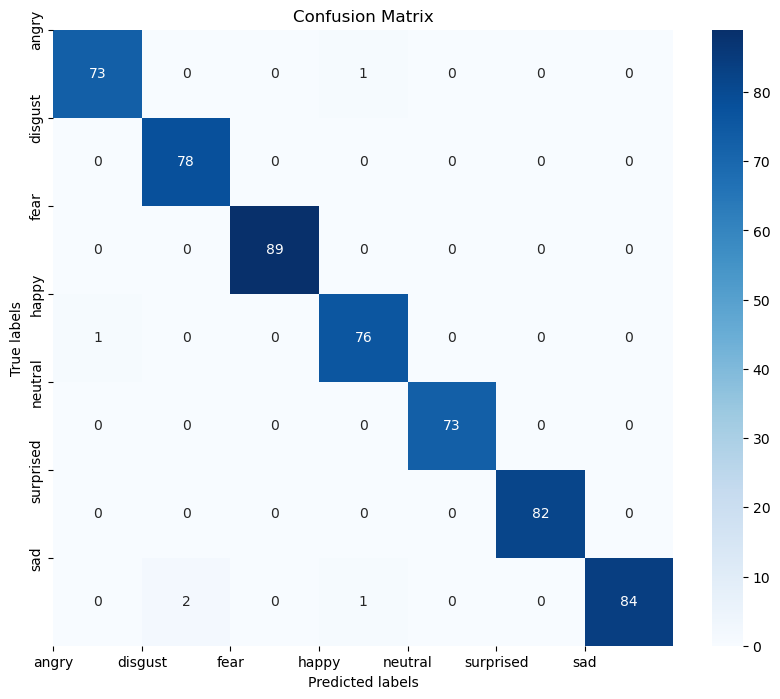

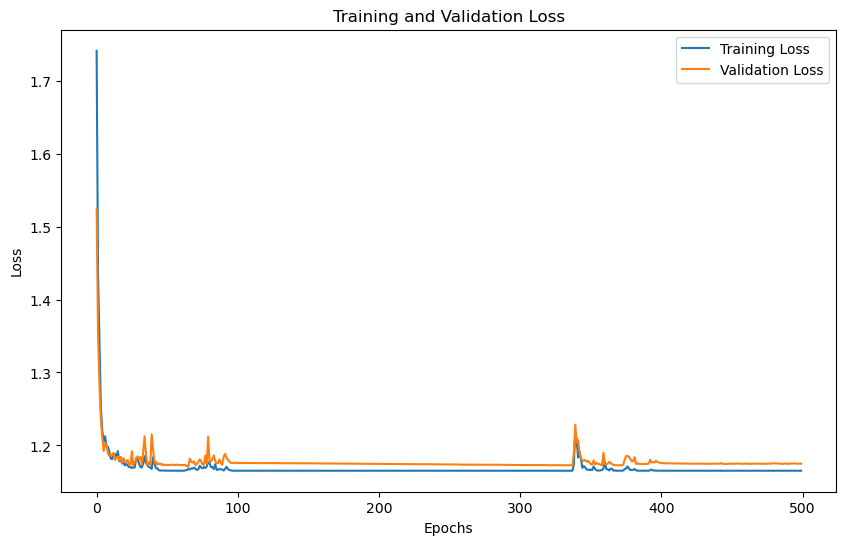

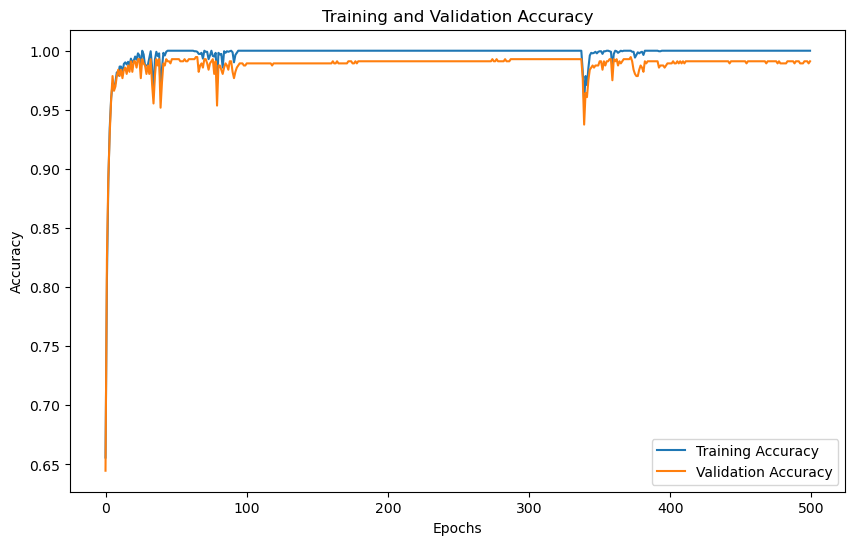

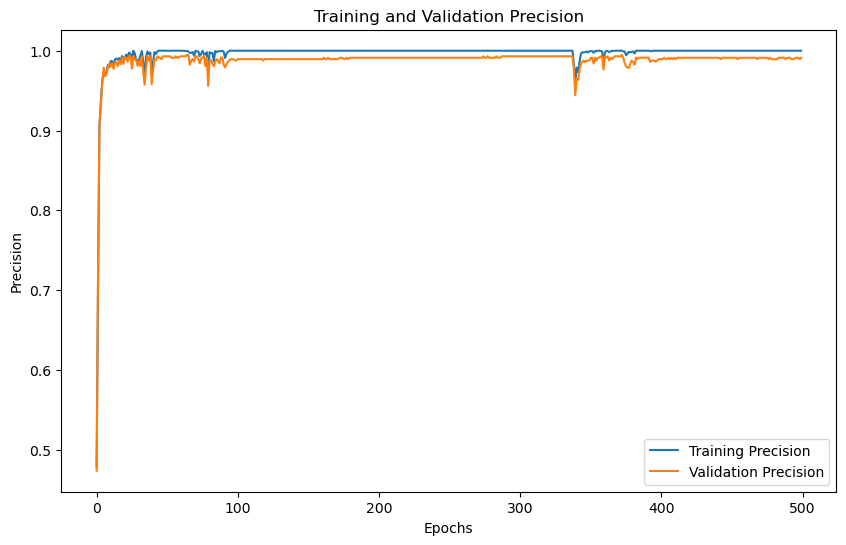

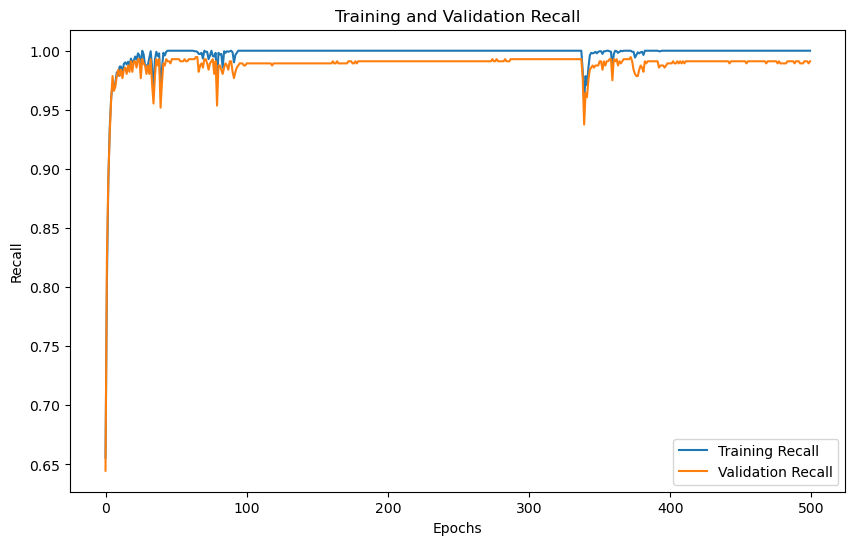

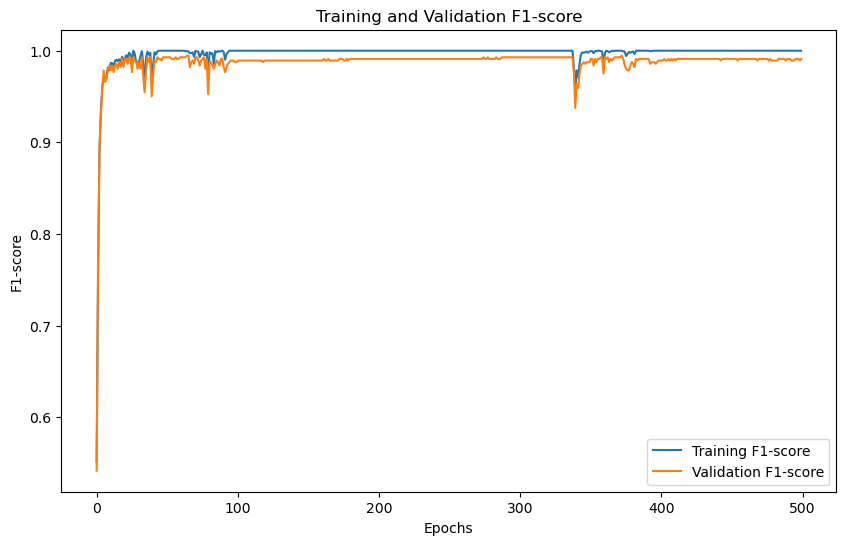

'Model Training and Evaluation Successfully completed'

In [48]:
train_model()